# V4 PATCH MARKER (do not delete)

This notebook has been patched with v4 improvements:
1. Resume-friendly smart extraction (cell labelled `smart_extract`)
2. 8-view TTA + 3-model soft-vote ensemble after v3 stress test
3. Knowledge distillation runner after `distill_to`
4. Integrated Gradients in place of KernelSHAP for Phase 3
5. Stable Diffusion img2img restoration in Phase 4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q timm captum shap grad-cam scikit-image opencv-python-headless tabulate
!pip install -q diffusers transformers accelerate

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 99.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 39.9 MB/s eta 0:00:00


In [ ]:
from pathlib import Path
import zipfile

# ----- Drive (input + persistent output) -----
DRIVE_ROOT      = Path('/content/drive/MyDrive/Thesis')
THESIS_ZIP      = DRIVE_ROOT / 'Thesis.zip'          # single outer zip
RESULTS_ROOT    = DRIVE_ROOT / 'results'
CHECKPOINTS_DIR = DRIVE_ROOT / 'checkpoints'

In [ ]:
LOCAL_ROOT   = Path('/content/data')
APTOS_DIR    = LOCAL_ROOT / 'aptos'
EYEQ_DIR     = LOCAL_ROOT / 'eyeq'
PRISTINE_DIR = LOCAL_ROOT / 'pristine'
DEGRADED_DIR = LOCAL_ROOT / 'degraded'
ENHANCED_DIR = LOCAL_ROOT / 'enhanced'

PHASE_DIRS = {
    'phase1_data_engineering':   RESULTS_ROOT / 'phase1_data_engineering',
    'phase2_model_benchmarking': RESULTS_ROOT / 'phase2_model_benchmarking',
    'phase3_xai_benchmark':      RESULTS_ROOT / 'phase3_xai_benchmark',
    'phase4_genai_enhancement':  RESULTS_ROOT / 'phase4_genai_enhancement',
    'phase5_quality_ensemble':   RESULTS_ROOT / 'phase5_quality_ensemble',
}
PHASE_SUBDIRS = ('metrics', 'plots', 'samples', 'logs')

In [ ]:
for p in [LOCAL_ROOT, PRISTINE_DIR, DEGRADED_DIR, ENHANCED_DIR,
          RESULTS_ROOT, CHECKPOINTS_DIR]:
    p.mkdir(parents=True, exist_ok=True)
for phase_dir in PHASE_DIRS.values():
    for sub in PHASE_SUBDIRS:
        (phase_dir / sub).mkdir(parents=True, exist_ok=True)

print('Drive zip   :', THESIS_ZIP, '(exists:', THESIS_ZIP.exists(), ')')
print('Drive results tree:')
for k, v in PHASE_DIRS.items():
    print(f'  {k:35s} -> {v}')

Drive zip   : /content/drive/MyDrive/Thesis/Thesis.zip (exists: True )
Drive results tree:
  phase1_data_engineering             -> /content/drive/MyDrive/Thesis/results/phase1_data_engineering
  phase2_model_benchmarking           -> /content/drive/MyDrive/Thesis/results/phase2_model_benchmarking
  phase3_xai_benchmark                -> /content/drive/MyDrive/Thesis/results/phase3_xai_benchmark
  phase4_genai_enhancement            -> /content/drive/MyDrive/Thesis/results/phase4_genai_enhancement
  phase5_quality_ensemble             -> /content/drive/MyDrive/Thesis/results/phase5_quality_ensemble


In [ ]:
# Idempotent extraction — skips automatically if already done in this Colab session.
# Saves 5-15 minutes per reconnect. Force re-extract: smart_extract(force=True).
import zipfile, shutil, time

EXTRACT_MARK = LOCAL_ROOT / ".extracted_ok"        # sentinel file


def _has_data():
    if not EXTRACT_MARK.exists():
        return False
    has_aptos = any(APTOS_DIR.rglob("*.png")) or any(APTOS_DIR.rglob("*.jpg"))
    has_eyeq  = any(EYEQ_DIR.rglob("*.png"))  or any(EYEQ_DIR.rglob("*.jpg"))
    return has_aptos and has_eyeq


def _find_dir(root: Path, keywords):
    for p in root.rglob("*"):
        if p.is_dir() and any(k in p.name.lower() for k in keywords):
            return p
    return None


def smart_extract(force: bool = False):
    """Extract Thesis.zip -> /content/data, then recursively unpack inner zips.
    Skips if a previous extraction is still in place."""
    LOCAL_ROOT.mkdir(parents=True, exist_ok=True)
    if _has_data() and not force:
        n_aptos = sum(1 for _ in APTOS_DIR.rglob("*.*"))
        n_eyeq  = sum(1 for _ in EYEQ_DIR.rglob("*.*"))
        print(f"[skip] data already extracted (aptos={n_aptos}, eyeq={n_eyeq})")
        return

    if not THESIS_ZIP.exists():
        raise FileNotFoundError(f"Missing zip: {THESIS_ZIP}")

    t0 = time.time()
    print(f"[extract] {THESIS_ZIP.name} -> {LOCAL_ROOT}")
    with zipfile.ZipFile(THESIS_ZIP) as z:
        z.extractall(LOCAL_ROOT)

    while True:
        inners = list(LOCAL_ROOT.rglob("*.zip"))
        if not inners:
            break
        for iz in inners:
            target = iz.parent / iz.stem
            target.mkdir(exist_ok=True)
            print(f"  inner zip: {iz.name} -> {target}")
            with zipfile.ZipFile(iz) as z:
                z.extractall(target)
            iz.unlink()

    # Symlink canonical paths
    aptos_src = _find_dir(LOCAL_ROOT, ["aptos"])
    eyeq_src  = _find_dir(LOCAL_ROOT, ["eyeq", "eye_q", "eye-q"])
    print("Detected APTOS dir:", aptos_src)
    print("Detected EyeQ  dir:", eyeq_src)
    for canonical, real in [(APTOS_DIR, aptos_src), (EYEQ_DIR, eyeq_src)]:
        if real is None:
            print(f"[warn] {canonical.name} not found — check Thesis.zip contents")
            continue
        if canonical.exists() and canonical.resolve() != real.resolve():
            if canonical.is_dir() and not canonical.is_symlink():
                shutil.rmtree(canonical)
            else:
                canonical.unlink()
        if not canonical.exists():
            canonical.symlink_to(real, target_is_directory=True)
        print(f"  {canonical} -> {real}")

    EXTRACT_MARK.touch()
    print(f"[extract] done in {time.time()-t0:.1f}s")


smart_extract()         # subsequent calls in this session are instant


[extract] Thesis.zip -> /content/data
  inner zip: train_images_768.zip -> /content/data/Thesis/EYEQ/train_images_768
  inner zip: test_images_768.zip -> /content/data/Thesis/EYEQ/test_images_768
  inner zip: test_images.zip -> /content/data/Thesis/APTOS/test_images
  inner zip: train_images.zip -> /content/data/Thesis/APTOS/train_images
  inner zip: val_images.zip -> /content/data/Thesis/APTOS/val_images
Detected APTOS dir: /content/data/Thesis/APTOS
Detected EyeQ  dir: /content/data/Thesis/EYEQ
  /content/data/aptos -> /content/data/Thesis/APTOS
  /content/data/eyeq -> /content/data/Thesis/EYEQ
[extract] done in 3490.4s


In [ ]:
def show_tree(root: Path, max_depth: int = 3):
    root = Path(root)
    for p in sorted(root.rglob('*')):
        depth = len(p.relative_to(root).parts)
        if depth > max_depth: continue
        kind = '/' if p.is_dir() else ''
        print(f'{"  "*(depth-1)}{p.name}{kind}')

print('=== APTOS ==='); show_tree(APTOS_DIR, max_depth=2)
print('\n=== EYEQ  ==='); show_tree(EYEQ_DIR,  max_depth=2)

=== APTOS ===
test.csv
test_images/
  test_images/
train_1.csv
train_images/
  train_images/
val_images/
  val_images/
valid.csv

=== EYEQ  ===
Label_EyeQ_test.csv
Label_EyeQ_train.csv
test_images_768/
  test/
train_images_768/
  train/


In [ ]:
import torch
PHASE_DIRS = {
    'phase1_data_engineering':   RESULTS_ROOT / 'phase1_data_engineering',
    'phase2_model_benchmarking': RESULTS_ROOT / 'phase2_model_benchmarking',
    'phase3_xai_benchmark':      RESULTS_ROOT / 'phase3_xai_benchmark',
    'phase4_genai_enhancement':  RESULTS_ROOT / 'phase4_genai_enhancement',
    'phase5_quality_ensemble':   RESULTS_ROOT / 'phase5_quality_ensemble',
}
for p in [DEGRADED_DIR, ENHANCED_DIR, RESULTS_ROOT, CHECKPOINTS_DIR]:
    p.mkdir(parents=True, exist_ok=True)
for d in PHASE_DIRS.values():
    for sub in ('metrics', 'plots', 'samples', 'logs'):
        (d / sub).mkdir(parents=True, exist_ok=True)

# Auto-detect APTOS train CSV + image dir (case-insensitive)
APTOS_CSV    = next(p for p in APTOS_DIR.rglob('*.csv') if 'train' in p.name.lower())
APTOS_IMAGES = next(p for p in APTOS_DIR.rglob('*train_images*') if p.is_dir())
EYEQ_CSV     = next(EYEQ_DIR.rglob('*.csv'), None)

# Common constants
NUM_CLASSES = 5
CLASS_NAMES = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']
IMAGE_SIZE  = 224
SEED        = 42
VAL_SPLIT, TEST_SPLIT = 0.15, 0.15

MODEL_NAMES = ('resnet50', 'efficientnet_b3', 'vit_base')
TIMM_NAMES  = {'resnet50': 'resnet50',
               'efficientnet_b3': 'efficientnet_b3',
               'vit_base': 'vit_base_patch16_224'}
TRAIN_CFG = dict(batch_size=32, num_workers=2, epochs=15,
                 lr=3e-4, weight_decay=1e-4, label_smoothing=0.05,
                 mixed_precision=True)

DEGRADATION_TYPES  = ('blur', 'exposure', 'noise')
DEGRADATION_LEVELS = ('low', 'mid', 'high')
DEGRADATION_PARAMS = {
    'blur':     {'low': 2.0,  'mid': 5.0,  'high': 9.0},
    'exposure': {'low': 0.7,  'mid': 0.4,  'high': 0.2},
    'noise':    {'low': 0.02, 'mid': 0.06, 'high': 0.12},
}
EYEQ_QUALITY_LABELS = {0: 'good', 1: 'usable', 2: 'reject'}

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('APTOS csv   :', APTOS_CSV)
print('APTOS images:', APTOS_IMAGES)
print('EyeQ csv    :', EYEQ_CSV)
print('Device      :', DEVICE)

APTOS csv   : /content/data/aptos/train_1.csv
APTOS images: /content/data/aptos/train_images
EyeQ csv    : /content/data/eyeq/Label_EyeQ_test.csv
Device      : cuda


In [ ]:
import json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from tqdm.auto import tqdm

import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torch.cuda.amp import GradScaler, autocast
from torchvision import transforms as T
import timm
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, classification_report
from scipy.stats import spearmanr
from skimage.segmentation import slic

TFM_TRAIN = T.Compose([T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
                        T.RandomHorizontalFlip(),
                        T.RandomRotation(15),
                        T.ColorJitter(0.1, 0.1, 0.1),
                        T.ToTensor(),
                        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
TFM_EVAL  = T.Compose([T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
                        T.ToTensor(),
                        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def load_tensor(path: Path) -> torch.Tensor:
    return TFM_EVAL(Image.open(path).convert('RGB')).unsqueeze(0).to(DEVICE)

In [ ]:
class APTOSDataset(Dataset):
    """Resolves images via IMAGE_INDEX so any extension / nested layout works."""
    def __init__(self, csv_path, images_dir, transform):
        self.df = pd.read_csv(csv_path)
        self.images_dir = Path(images_dir)   # kept for API compatibility, not used
        self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(resolve_image(row['id_code'])).convert('RGB')
        return self.transform(img), int(row['diagnosis']), row['id_code']

class FolderDataset(Dataset):
    """Reads `<root>/manifest.csv` (cols: id_code, diagnosis, rel_path)."""
    def __init__(self, root, transform=TFM_EVAL):
        self.root = Path(root); self.df = pd.read_csv(self.root / 'manifest.csv')
        self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(self.root / row['rel_path']).convert('RGB')
        return self.transform(img), int(row['diagnosis']), row['id_code']

In [ ]:
# === Improved training infrastructure ===
import math
from contextlib import contextmanager
from collections import Counter
from torch.utils.data import WeightedRandomSampler, Subset
from sklearn.model_selection import train_test_split

# 1) STRATIFIED SPLIT — keeps class proportions consistent across train/val/test
def stratified_split_indices(labels, val_frac=0.15, test_frac=0.15, seed=SEED):
    idx = np.arange(len(labels)); labels = np.array(labels)
    tr_idx, te_idx = train_test_split(idx, test_size=test_frac, stratify=labels, random_state=seed)
    rel_val = val_frac / (1 - test_frac)
    tr_idx, va_idx = train_test_split(tr_idx, test_size=rel_val,
                                       stratify=labels[tr_idx], random_state=seed)
    return tr_idx.tolist(), va_idx.tolist(), te_idx.tolist()

# 2) CLASS WEIGHTS + BALANCED SAMPLER
def class_weights_tensor(labels, num_classes=NUM_CLASSES):
    cnt = Counter(labels); n = sum(cnt.values())
    return torch.tensor([n / (num_classes * max(cnt.get(i, 0), 1)) for i in range(num_classes)],
                         dtype=torch.float)

def balanced_sampler(labels):
    cnt = Counter(labels)
    w = [1.0 / cnt[l] for l in labels]
    return WeightedRandomSampler(w, num_samples=len(w), replacement=True)

# 3) FOCAL LOSS (handles soft targets from MixUp + per-class weights)
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=None, label_smoothing=0.0):
        super().__init__(); self.gamma, self.alpha, self.ls = gamma, alpha, label_smoothing
    def forward(self, logits, targets):
        if targets.dim() > 1:                       # soft labels (MixUp)
            log_p = F.log_softmax(logits, dim=-1)
            return -(targets * log_p).sum(-1).mean()
        ce = F.cross_entropy(logits, targets, weight=self.alpha,
                              reduction='none', label_smoothing=self.ls)
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()

# 4) EMA — exponential moving average of weights, +0.5–1% reliably
class EMA:
    def __init__(self, model, decay=0.999):
        self.decay = decay
        self.shadow = {n: p.detach().clone() for n, p in model.named_parameters() if p.requires_grad}
    def update(self, model):
        with torch.no_grad():
            for n, p in model.named_parameters():
                if p.requires_grad:
                    self.shadow[n].mul_(self.decay).add_(p.detach(), alpha=1 - self.decay)
    @contextmanager
    def applied(self, model):
        backup = {n: p.detach().clone() for n, p in model.named_parameters() if p.requires_grad}
        for n, p in model.named_parameters():
            if p.requires_grad: p.data.copy_(self.shadow[n])
        try: yield
        finally:
            for n, p in model.named_parameters():
                if p.requires_grad: p.data.copy_(backup[n])

# 5) STRONG TRAIN AUGMENTATION (medical-imaging safe — no extreme hue shifts)
TFM_TRAIN_STRONG = T.Compose([
    T.Resize((IMAGE_SIZE + 32, IMAGE_SIZE + 32)),
    T.RandomCrop(IMAGE_SIZE),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(25),
    T.RandAugment(num_ops=2, magnitude=7),
    T.ColorJitter(0.15, 0.15, 0.15, 0.03),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    T.RandomErasing(p=0.25),
])

# 6) MIXUP / CUTMIX (timm's implementation)
from timm.data import Mixup

# 7) LAYER-WISE LR DECAY (LRD) — critical for ViT fine-tuning
def vit_lrd_param_groups(model, base_lr, decay=0.75, weight_decay=5e-2):
    n_layers = len(model.blocks) + 1
    groups = []
    for n, p in model.named_parameters():
        if not p.requires_grad: continue
        if n.startswith('head'):                                  depth = n_layers
        elif n.startswith('blocks'):                              depth = int(n.split('.')[1])
        elif any(n.startswith(s) for s in
                 ('patch_embed', 'cls_token', 'pos_embed', 'norm')): depth = 0
        else:                                                     depth = 0
        lr_scale = decay ** (n_layers - depth)
        groups.append({'params': p, 'lr': base_lr * lr_scale,
                       'weight_decay': 0.0 if p.ndim <= 1 else weight_decay})
    return groups

# 8) WARMUP + COSINE LR SCHEDULE
def warmup_cosine(optimizer, warmup_epochs, total_epochs, steps_per_epoch):
    def lr_lambda(step):
        epoch = step / max(steps_per_epoch, 1)
        if epoch < warmup_epochs:
            return epoch / max(warmup_epochs, 1)
        prog = (epoch - warmup_epochs) / max(total_epochs - warmup_epochs, 1)
        return 0.5 * (1 + math.cos(math.pi * min(prog, 1.0)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

# 9) PER-ARCHITECTURE HYPERPARAMETERS
HPARAMS = {
    'resnet50':        dict(lr=3e-4, wd=1e-4, epochs=25, mixup=0.2, ls=0.1, gamma=1.5, warmup=3, llrd=None),
    'efficientnet_b3': dict(lr=2e-4, wd=1e-5, epochs=25, mixup=0.2, ls=0.1, gamma=2.0, warmup=3, llrd=None),
    'vit_base':        dict(lr=5e-5, wd=5e-2, epochs=30, mixup=0.4, ls=0.1, gamma=2.0, warmup=5, llrd=0.75),
}

print('Improved training infrastructure loaded.')

Improved training infrastructure loaded.


In [ ]:
def find_in_folder(folder, id_code, exts=('.jpg', '.png', '.jpeg')):
    """Return the actual file path for id_code in folder, regardless of extension."""
    for ext in exts:
        p = Path(folder) / f'{id_code}{ext}'
        if p.exists():
            return p
    raise FileNotFoundError(f'{id_code} not found in {folder} (tried {exts})')

In [ ]:
def build_model(name, pretrained=True):
    m = timm.create_model(TIMM_NAMES[name], pretrained=pretrained, num_classes=NUM_CLASSES)
    m._dr_arch = name
    return m

def load_classifier(name):
    m = build_model(name, pretrained=False).to(DEVICE)
    state = torch.load(CHECKPOINTS_DIR / f'{name}_best.pt', map_location=DEVICE, weights_only=False)
    m.load_state_dict(state['state_dict']); m.eval()
    return m

def get_xai_target_layer(model):
    a = model._dr_arch
    if a == 'resnet50':        return model.layer4[-1]
    if a == 'efficientnet_b3': return model.blocks[-1]
    if a == 'vit_base':        return model.blocks[-1].norm1
    raise ValueError(a)

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); ys, ps, probs = [], [], []
    for x, y, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        prob = torch.softmax(model(x), 1).cpu().numpy()
        probs.append(prob); ps.append(prob.argmax(1)); ys.append(y.numpy())
    y = np.concatenate(ys); p = np.concatenate(ps); pr = np.concatenate(probs)
    out = {'accuracy': accuracy_score(y, p), 'f1_macro': f1_score(y, p, average='macro')}
    try: out['auc_macro_ovr'] = roc_auc_score(y, pr, average='macro', multi_class='ovr')
    except ValueError: out['auc_macro_ovr'] = float('nan')
    return out

def train_one(model, train_loader, val_loader, ckpt_path, history_csv,
              epochs=TRAIN_CFG['epochs'], lr=TRAIN_CFG['lr'],
              wd=TRAIN_CFG['weight_decay'], ls=TRAIN_CFG['label_smoothing'],
              amp=TRAIN_CFG['mixed_precision']):
    model = model.to(DEVICE)
    optim  = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched  = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=epochs)
    crit   = nn.CrossEntropyLoss(label_smoothing=ls)
    scaler = GradScaler(enabled=amp)
    best_f1, history = -1.0, []
    for ep in range(epochs):
        model.train(); running, seen = 0.0, 0
        pbar = tqdm(train_loader, desc=f'epoch {ep+1}/{epochs}', leave=False)
        for x, y, _ in pbar:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
            optim.zero_grad(set_to_none=True)
            with autocast(enabled=amp):
                loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(optim); scaler.update()
            running += loss.item() * x.size(0); seen += x.size(0)
            pbar.set_postfix(loss=running/seen)
        sched.step()
        m = evaluate(model, val_loader)
        history.append({'epoch': ep+1, 'train_loss': running/seen, **m})
        print(f'  val: acc={m["accuracy"]:.4f}  f1={m["f1_macro"]:.4f}  auc={m["auc_macro_ovr"]:.4f}')
        if m['f1_macro'] > best_f1:
            best_f1 = m['f1_macro']
            torch.save({'state_dict': model.state_dict(), 'arch': model._dr_arch, 'val': m}, ckpt_path)
    pd.DataFrame(history).to_csv(history_csv, index=False)
    return pd.DataFrame(history)

In [ ]:
def gradcam_heatmap(model, x, target_class=None):
    layer = get_xai_target_layer(model)
    acts, grads = {}, {}
    h1 = layer.register_forward_hook(lambda _, __, o: acts.update(v=o.detach()))
    h2 = layer.register_full_backward_hook(lambda _, gi, go: grads.update(v=go[0].detach()))
    try:
        model.zero_grad(set_to_none=True)
        x = x.clone().requires_grad_(True)
        logits = model(x)
        if target_class is None:
            target_class = int(logits.argmax(1).item())
        logits[0, target_class].backward()
        a, g = acts['v'][0], grads['v'][0]
        cam = torch.relu((g.mean(dim=(1, 2))[:, None, None] * a).sum(0))
        cam -= cam.min()
        if cam.max() > 0: cam /= cam.max()
        cam = F.interpolate(cam[None, None], size=x.shape[-2:], mode='bilinear', align_corners=False)
        return cam.squeeze().detach().cpu().numpy()
    finally:
        h1.remove(); h2.remove()

@torch.no_grad()
def attention_rollout(model, x, target_class=None):
    attns, handles = [], []
    for blk in model.blocks:
        attn_module = blk.attn
        def make_hook(store, mod):
            def _h(module, inp, out):
                B, N, C = inp[0].shape
                qkv = mod.qkv(inp[0]).reshape(B, N, 3, mod.num_heads, C // mod.num_heads).permute(2, 0, 3, 1, 4)
                q, k, _ = qkv[0], qkv[1], qkv[2]
                a = (q @ k.transpose(-2, -1)) * mod.scale
                store.append(a.softmax(-1).detach())
            return _h
        handles.append(attn_module.register_forward_hook(make_hook(attns, attn_module)))
    try: _ = model(x)
    finally:
        for h in handles: h.remove()
    res = None
    for a in attns:
        a = a.mean(1) + torch.eye(a.size(-1), device=a.device)
        a = a / a.sum(-1, keepdim=True)
        res = a if res is None else a @ res
    cls = res[0, 0, 1:]; side = int(cls.numel() ** 0.5)
    h = F.interpolate(cls.reshape(side, side)[None, None],
                       size=x.shape[-2:], mode='bilinear', align_corners=False).squeeze().cpu().numpy()
    if h.max() > h.min(): h = (h - h.min()) / (h.max() - h.min())
    return h

def shap_heatmap(model, x, target_class=None, n_samples=60, n_segments=40):
    import shap
    img = x.squeeze(0).permute(1, 2, 0).cpu().numpy()
    seg = slic(img, n_segments=n_segments, compactness=10, start_label=0)
    def f(masks):
        out = np.zeros((masks.shape[0], NUM_CLASSES), dtype=np.float32)
        for i, m in enumerate(masks):
            keep = np.isin(seg, np.where(m == 1)[0])
            masked = img.copy(); masked[~keep] = img.mean(axis=(0, 1))
            t = torch.tensor(masked).permute(2, 0, 1).unsqueeze(0).float().to(DEVICE)
            with torch.no_grad():
                out[i] = torch.softmax(model(t), 1).cpu().numpy()[0]
        return out
    n_super = int(seg.max() + 1)
    explainer = shap.KernelExplainer(f, np.zeros((1, n_super)))
    sv = explainer.shap_values(np.ones((1, n_super)), nsamples=n_samples)
    if target_class is None:
        with torch.no_grad():
            target_class = int(model(x).argmax(1).item())
    sv = sv[target_class][0]
    heat = np.zeros(seg.shape, dtype=np.float32)
    for sid, val in enumerate(sv):
        heat[seg == sid] = val
    if heat.max() > heat.min():
        heat = (heat - heat.min()) / (heat.max() - heat.min())
    return heat

In [ ]:
@torch.no_grad()
def _prob_for(model, x, cls): return torch.softmax(model(x), 1)[0, cls].item()

def deletion_auc(model, x, heatmap, target_class, steps=30):
    H, W = heatmap.shape
    order = np.argsort(-heatmap.flatten())
    chunk = max(1, len(order) // steps)
    mean_pix = x.mean(dim=(2, 3), keepdim=True)
    probs = []
    for s in range(steps + 1):
        idx = order[: s * chunk]
        rows, cols = np.unravel_index(idx, (H, W))
        x_mod = x.clone()
        x_mod[0, :, rows, cols] = mean_pix.expand_as(x)[0, :, rows, cols]
        probs.append(_prob_for(model, x_mod, target_class))
    return float(np.trapezoid(probs, dx=1/steps))

def insertion_auc(model, x, heatmap, target_class, steps=30):
    H, W = heatmap.shape
    order = np.argsort(-heatmap.flatten())
    chunk = max(1, len(order) // steps)
    base = F.avg_pool2d(x, 15, stride=1, padding=7)
    probs = []
    for s in range(steps + 1):
        idx = order[: s * chunk]
        rows, cols = np.unravel_index(idx, (H, W))
        x_mod = base.clone(); x_mod[0, :, rows, cols] = x[0, :, rows, cols]
        probs.append(_prob_for(model, x_mod, target_class))
    return float(np.trapezoid(probs, dx=1/steps))

def stability_spearman(h1, h2):
    rho, _ = spearmanr(h1.flatten(), h2.flatten())
    return float(rho) if rho == rho else 0.0

def localization_iou(heatmap, mask, percentile=80):
    if mask is None: return float('nan')
    thr  = np.percentile(heatmap, percentile)
    pred = heatmap >= thr
    inter = np.logical_and(pred, mask).sum()
    union = np.logical_or(pred, mask).sum()
    return float(inter/union) if union > 0 else float('nan')

**DATA ENGINEERING**

In [ ]:
P1 = PHASE_DIRS['phase1_data_engineering']

# 1.1 Quality filter (EyeQ -> pristine subset; falls back to full APTOS)
def filter_pristine(aptos_csv, eyeq_csv, out_csv,
                    keep_quality=('good',),
                    eyeq_id_col='image', eyeq_quality_col='quality',
                    aptos_id_col='id_code'):
    aptos = pd.read_csv(aptos_csv)
    if eyeq_csv is None or not Path(eyeq_csv).exists():
        print('[fallback] No EyeQ CSV — keeping all APTOS rows.')
        aptos.to_csv(out_csv, index=False); return aptos
    eyeq = pd.read_csv(eyeq_csv)
    if pd.api.types.is_integer_dtype(eyeq[eyeq_quality_col]):
        eyeq['__q'] = eyeq[eyeq_quality_col].map(EYEQ_QUALITY_LABELS)
    else:
        eyeq['__q'] = eyeq[eyeq_quality_col].astype(str).str.lower()
    keep_ids = set(eyeq.loc[eyeq['__q'].isin(keep_quality), eyeq_id_col].astype(str))
    pristine = aptos[aptos[aptos_id_col].astype(str).isin(keep_ids)].reset_index(drop=True)
    if len(pristine) == 0:
        print('[warn] EyeQ filter removed all rows — falling back to full APTOS.')
        aptos.to_csv(out_csv, index=False); return aptos
    pristine.to_csv(out_csv, index=False); return pristine

PRISTINE_CSV = P1 / 'metrics' / 'pristine_split.csv'
pristine_df = filter_pristine(APTOS_CSV, EYEQ_CSV, PRISTINE_CSV)
print(f'kept {len(pristine_df)} / {pd.read_csv(APTOS_CSV).shape[0]} images')
pristine_df.head()

[warn] EyeQ filter removed all rows — falling back to full APTOS.
kept 2930 / 2930 images


,id_code,diagnosis
0,1ae8c165fd53,2
1,1b329a127307,1
2,1b32e1d775ea,4
3,1b3647865779,0
4,1b398c0494d1,0


In [ ]:
# Diagnose the actual APTOS image layout
print('APTOS_IMAGES :', APTOS_IMAGES)
print('Exists?       :', APTOS_IMAGES.exists())
all_files = list(APTOS_IMAGES.rglob('*'))
img_files = [p for p in all_files if p.is_file() and p.suffix.lower() in ('.png', '.jpg', '.jpeg')]
print(f'Total files under APTOS_IMAGES (any depth): {len(all_files)}')
print(f'Image files found                          : {len(img_files)}')
if img_files:
    print('Sample image paths:')
    for p in img_files[:5]:
        print(' ', p.relative_to(APTOS_IMAGES))
print('\nSample id_code from CSV:', pristine_df["id_code"].iloc[0])
print('Sample image stem      :', img_files[0].stem if img_files else '(none)')

APTOS_IMAGES : /content/data/aptos/train_images
Exists?       : True
Total files under APTOS_IMAGES (any depth): 2934
Image files found                          : 2930
Sample image paths:
  train_images/de4cdabbce6d.png
  train_images/ae8472f8d310.png
  train_images/2cceb07ff706.png
  train_images/4360a112db10.png
  train_images/236f56771ec6.png

Sample id_code from CSV: 1ae8c165fd53
Sample image stem      : de4cdabbce6d


In [ ]:
# Build a stem -> path index so we don't care about extension or subfolder depth.
# Searches all of APTOS_DIR (not just APTOS_IMAGES) in case auto-detection picked the wrong folder.
print('Indexing APTOS images...')
IMAGE_INDEX = {}
for p in APTOS_DIR.rglob('*'):
    if p.is_file() and p.suffix.lower() in ('.png', '.jpg', '.jpeg', '.tif', '.tiff'):
        IMAGE_INDEX[p.stem] = p
print(f'Indexed {len(IMAGE_INDEX)} images.')

# Sanity check against the CSV
csv_ids = pristine_df['id_code'].astype(str).tolist()
matched = [i for i in csv_ids if i in IMAGE_INDEX]
missing = [i for i in csv_ids if i not in IMAGE_INDEX]
print(f'CSV ids matched: {len(matched)}/{len(csv_ids)}')
if missing:
    print(f'Example missing id: {missing[0]}')
    print('Example indexed stems:', list(IMAGE_INDEX)[:3])
    raise SystemExit('CSV ids do not match image filenames — inspect the diagnostic output above.')

def resolve_image(id_code):
    """Get the actual image path for an APTOS id_code, regardless of extension or folder."""
    p = IMAGE_INDEX.get(str(id_code))
    if p is None:
        raise FileNotFoundError(f'No image indexed for id_code={id_code!r}')
    return p

Indexing APTOS images...
Indexed 3662 images.
CSV ids matched: 2930/2930


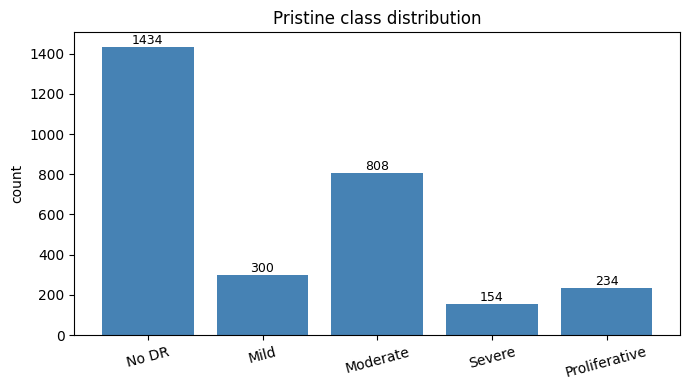

Saved: /content/drive/MyDrive/Thesis/results/phase1_data_engineering/plots/class_distribution.png


In [ ]:
# 1.2 Class-balance plot
counts = pristine_df['diagnosis'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar([CLASS_NAMES[i] for i in counts.index], counts.values, color='steelblue')
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v, str(v), ha='center', va='bottom', fontsize=9)
ax.set_title('Pristine class distribution'); ax.set_ylabel('count')
plt.xticks(rotation=15); plt.tight_layout()
out = P1 / 'plots' / 'class_distribution.png'
plt.savefig(out, dpi=150); plt.show()
print('Saved:', out)

In [ ]:
# 1.3 Synthetic degradation primitives
def _np(img):  return np.array(img.convert('RGB'))
def _pil(arr): return Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))

def gaussian_blur(img, sigma):
    k = max(3, int(2 * round(3 * sigma) + 1))
    return _pil(cv2.GaussianBlur(_np(img), (k, k), sigmaX=sigma, sigmaY=sigma))

def exposure_shift(img, gain): return _pil(_np(img).astype(np.float32) * gain)
def gaussian_noise(img, std_frac):
    arr = _np(img).astype(np.float32)
    return _pil(arr + np.random.normal(0, std_frac * 255, arr.shape))

DEGRADERS = {'blur': gaussian_blur, 'exposure': exposure_shift, 'noise': gaussian_noise}
def apply_degradation(img, kind, level):
    return DEGRADERS[kind](img, DEGRADATION_PARAMS[kind][level])

In [ ]:
!du -sh /content/data/* 2>/dev/null
!df -h /content

0	/content/data/aptos
4.0K	/content/data/degraded
4.0K	/content/data/enhanced
0	/content/data/eyeq
4.0K	/content/data/pristine
98G	/content/data/Thesis
Filesystem      Size  Used Avail Use% Mounted on
overlay         236G  145G   91G  62% /


In [ ]:
import shutil

# Use rm -rf for a more forceful deletion to handle potential disk full issues
# or lingering file handles.
!rm -rf {DEGRADED_DIR}

# Ensure the base directory exists before recreating subdirectories.
DEGRADED_DIR.mkdir(parents=True, exist_ok=True)

# Check disk space after deletion to confirm space is freed.
!df -h /content

Filesystem      Size  Used Avail Use% Mounted on
overlay         236G  145G   91G  62% /


In [ ]:
# [RESUME GUARD] Skip if degraded images already exist on local disk or Drive cache.
import shutil as _sh

_degraded_present = (
    DEGRADED_DIR.exists()
    and any((DEGRADED_DIR / k / l / "manifest.csv").exists()
            for k in DEGRADATION_TYPES for l in DEGRADATION_LEVELS)
)

# Auto-restore from Drive cache if local disk is empty but cache exists
_deg_cache = DRIVE_ROOT / "cache_degraded.tar.gz"
if not _degraded_present and _deg_cache.exists():
    print(f"[restore] Pulling degraded cache from Drive: {_deg_cache}")
    !tar -xzf "{_deg_cache}" -C /content/data
    _degraded_present = any((DEGRADED_DIR / k / l / "manifest.csv").exists()
                             for k in DEGRADATION_TYPES for l in DEGRADATION_LEVELS)

if _degraded_present:
    print("[skip] degraded images already present — not regenerating.")
    # Still need to make pristine_df available downstream (loaded above in cell 16/17).
else:
    print("[run] Generating degraded sets (this takes ~25 min on A100)...")

# 1.4 (parallel + resized + JPEG) — ~50-100x smaller on disk
from concurrent.futures import ThreadPoolExecutor, as_completed
import os

MAX_WORKERS = max(4, (os.cpu_count() or 2) * 2)
print(f'Using {MAX_WORKERS} worker threads')

DEG_SAVE_SIZE    = (IMAGE_SIZE, IMAGE_SIZE)   # 224x224 — same as model input
DEG_SAVE_FORMAT  = 'JPEG'                      # huge size win vs PNG
DEG_SAVE_QUALITY = 90                          # visually indistinguishable for retinal images
DEG_SAVE_EXT     = '.jpg'

def _process_one(row, kind, level, out_dir):
    try:
        src = resolve_image(row['id_code'])
    except FileNotFoundError:
        return None
    img = Image.open(src).convert('RGB').resize(DEG_SAVE_SIZE, Image.BILINEAR)
    out_img = apply_degradation(img, kind, level)
    rel = f"{row['id_code']}{DEG_SAVE_EXT}"
    out_img.save(out_dir / rel, format=DEG_SAVE_FORMAT, quality=DEG_SAVE_QUALITY, optimize=False)
    return {'id_code': row['id_code'], 'diagnosis': int(row['diagnosis']),
            'degradation': kind, 'level': level, 'rel_path': rel}

def build_split_parallel(kind, level):
    out_dir = DEGRADED_DIR / kind / level
    out_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as ex:
        futures = [ex.submit(_process_one, r, kind, level, out_dir)
                   for _, r in pristine_df.iterrows()]
        for fut in tqdm(as_completed(futures), total=len(futures),
                         desc=f'{kind}-{level}', leave=False):
            r = fut.result()
            if r is not None:
                rows.append(r)
    df = pd.DataFrame(rows)
    df.to_csv(out_dir / 'manifest.csv', index=False)
    df.to_csv(P1 / 'metrics' / f'manifest_{kind}_{level}.csv', index=False)
    return df

for k in DEGRADATION_TYPES:
    for l in DEGRADATION_LEVELS:
        m = build_split_parallel(k, l)
        print(f'  {k}/{l}: {len(m)} images')

!df -h /content"

[restore] Pulling degraded cache from Drive: /content/drive/MyDrive/Thesis/cache_degraded.tar.gz
[skip] degraded images already present — not regenerating.
Using 24 worker threads


blur-low:   0%|          | 0/2930 [00:00<?, ?it/s]

  blur/low: 2930 images


blur-mid:   0%|          | 0/2930 [00:00<?, ?it/s]

  blur/mid: 2930 images


blur-high:   0%|          | 0/2930 [00:00<?, ?it/s]

... (9 outputs left out)

noise-mid:   0%|          | 0/2930 [00:00<?, ?it/s]

  noise/mid: 2930 images


noise-high:   0%|          | 0/2930 [00:00<?, ?it/s]

  noise/high: 2930 images
/bin/bash: -c: line 1: unexpected EOF while looking for matching `"'
/bin/bash: -c: line 2: syntax error: unexpected end of file


In [ ]:
# 1.5 Sample grids — extension-agnostic
rng = np.random.default_rng(SEED)
sample_ids = rng.choice(pristine_df['id_code'].values, size=4, replace=False)
for kind in DEGRADATION_TYPES:
    fig, axes = plt.subplots(4, 4, figsize=(11, 11))
    for r, sid in enumerate(sample_ids):
        clean = Image.open(resolve_image(sid)).convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
        axes[r, 0].imshow(clean); axes[r, 0].set_title('clean' if r == 0 else '')
        for c, lvl in enumerate(DEGRADATION_LEVELS, start=1):
            axes[r, c].imshow(apply_degradation(clean, kind, lvl))
            if r == 0: axes[r, c].set_title(lvl)
        for ax in axes[r]: ax.axis('off')
    fig.suptitle(f'Degradation: {kind}', fontsize=14); plt.tight_layout()
    out = P1 / 'samples' / f'grid_{kind}.png'
    plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
    print('Saved:', out)

# 1.6 Phase summary
summary = pd.DataFrame([{'degradation': k, 'level': l,
                          'n_images': len(list((DEGRADED_DIR/k/l).glob('*.png')))}
                         for k in DEGRADATION_TYPES for l in DEGRADATION_LEVELS])
summary.to_csv(P1 / 'metrics' / 'phase1_summary.csv', index=False)
summary

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# 2.1 (improved) — stratified split, per-class weights, balanced sampler
P2 = PHASE_DIRS['phase2_model_benchmarking']
PRISTINE_CSV = PHASE_DIRS['phase1_data_engineering'] / 'metrics' / 'pristine_split.csv'

# Build the dataset once with eval transforms; we'll override transforms per-loader.
full_ds_eval  = APTOSDataset(PRISTINE_CSV, APTOS_IMAGES, TFM_EVAL)
full_ds_train = APTOSDataset(PRISTINE_CSV, APTOS_IMAGES, TFM_TRAIN_STRONG)

labels_all = [int(full_ds_eval.df.iloc[i]['diagnosis']) for i in range(len(full_ds_eval))]
tr_idx, va_idx, te_idx = stratified_split_indices(labels_all)

train_ds = Subset(full_ds_train, tr_idx)
val_ds   = Subset(full_ds_eval,  va_idx)
test_ds  = Subset(full_ds_eval,  te_idx)

train_labels = [labels_all[i] for i in tr_idx]
CLS_W   = class_weights_tensor(train_labels).to(DEVICE)
sampler = balanced_sampler(train_labels)

print('Train class distribution :', Counter(train_labels))
print('Val   class distribution :', Counter([labels_all[i] for i in va_idx]))
print('Test  class distribution :', Counter([labels_all[i] for i in te_idx]))
print('Class weights (loss)     :', CLS_W.cpu().tolist())

common = dict(num_workers=2, pin_memory=True)
train_loader = DataLoader(train_ds, batch_size=32, sampler=sampler, **common)
val_loader   = DataLoader(val_ds,   batch_size=64, shuffle=False,   **common)
test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False,   **common)

# Save test ids for downstream phases
test_ids = [full_ds_eval.df.iloc[i]['id_code'] for i in te_idx]
pd.DataFrame({'id_code': test_ids}).to_csv(P2 / 'metrics' / 'test_ids.csv', index=False)
print(f'\ntrain={len(train_ds)}  val={len(val_ds)}  test={len(test_ds)}')

Train class distribution : Counter({0: 1003, 2: 565, 1: 210, 4: 164, 3: 108})
Val   class distribution : Counter({0: 215, 2: 122, 1: 45, 4: 35, 3: 23})
Test  class distribution : Counter({0: 216, 2: 121, 1: 45, 4: 35, 3: 23})
Class weights (loss)     : [0.4087736904621124, 1.952380895614624, 0.7256637215614319, 3.7962963581085205, 2.5]

train=2050  val=440  test=440


In [ ]:
def train_v2(name, train_loader, val_loader, ckpt_path, history_csv, hp, class_weights):
    model = build_model(name, pretrained=True).to(DEVICE)

    # Optimizer — LRD for ViT, regular AdamW for CNNs
    if hp['llrd'] is not None and name == 'vit_base':
        param_groups = vit_lrd_param_groups(model, base_lr=hp['lr'],
                                             decay=hp['llrd'], weight_decay=hp['wd'])
        optim = torch.optim.AdamW(param_groups)
    else:
        optim = torch.optim.AdamW(model.parameters(), lr=hp['lr'], weight_decay=hp['wd'])

    sched = warmup_cosine(optim, warmup_epochs=hp['warmup'],
                           total_epochs=hp['epochs'], steps_per_epoch=len(train_loader))
    crit  = FocalLoss(gamma=hp['gamma'], alpha=class_weights, label_smoothing=hp['ls'])
    scaler = GradScaler(enabled=True)
    mixup_fn = Mixup(mixup_alpha=hp['mixup'], cutmix_alpha=1.0,
                      label_smoothing=hp['ls'], num_classes=NUM_CLASSES)
    ema = EMA(model, decay=0.999)

    best_f1, history = -1.0, []
    for ep in range(hp['epochs']):
        model.train(); running, seen = 0.0, 0
        pbar = tqdm(train_loader, desc=f'[{name}] ep {ep+1}/{hp["epochs"]}', leave=False)
        for x, y, _ in pbar:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            x, y_soft = mixup_fn(x, y)
            optim.zero_grad(set_to_none=True)
            with autocast(enabled=True):
                loss = crit(model(x), y_soft)
            scaler.scale(loss).backward()
            scaler.unscale_(optim)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optim); scaler.update(); sched.step(); ema.update(model)
            running += loss.item() * x.size(0); seen += x.size(0)
            pbar.set_postfix(loss=running/seen, lr=optim.param_groups[0]['lr'])

        # Evaluate with EMA weights — usually a bit better
        with ema.applied(model):
            m = evaluate(model, val_loader)
        history.append({'epoch': ep + 1, 'train_loss': running / seen, **m,
                        'lr': optim.param_groups[0]['lr']})
        print(f'  val: acc={m["accuracy"]:.4f}  f1={m["f1_macro"]:.4f}  auc={m["auc_macro_ovr"]:.4f}')
        if m['f1_macro'] > best_f1:
            best_f1 = m['f1_macro']
            with ema.applied(model):
                torch.save({'state_dict': {k: v.clone() for k, v in model.state_dict().items()},
                            'arch': name, 'val': m, 'hp': hp}, ckpt_path)
    pd.DataFrame(history).to_csv(history_csv, index=False)
    return pd.DataFrame(history)

print('train_v2 ready.')

train_v2 ready.


In [ ]:
# [RESUME GUARD] Skip v1/v2 training if all checkpoints exist on Drive.
_v2_present = all((CHECKPOINTS_DIR / f"{n}_best.pt").exists() for n in MODEL_NAMES)
if _v2_present:
    print("[skip] v2 checkpoints already on Drive — not retraining.")
    print("        Found:", *[f"{n}_best.pt" for n in MODEL_NAMES])
    histories = {}   # placeholder so downstream cells don't NameError
else:
    print("[run] Training v1/v2 models (this takes ~2 hours on A100)...")
    histories = {}
    for name in MODEL_NAMES:
        print(f'\n========== Training {name} ==========')
        hp = HPARAMS[name]
        histories[name] = train_v2(name, train_loader, val_loader,
                                    ckpt_path=CHECKPOINTS_DIR / f'{name}_best.pt',
                                    history_csv=P2 / 'metrics' / f'training_history_{name}.csv',
                                    hp=hp, class_weights=CLS_W)
        torch.cuda.empty_cache()

[skip] v2 checkpoints already on Drive — not retraining.
        Found: resnet50_best.pt efficientnet_b3_best.pt vit_base_best.pt


In [ ]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

True
NVIDIA L4


In [ ]:
# 2.3 Training curves
for name, h in histories.items():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h['epoch'], h['train_loss']); ax[0].set_title(f'{name} — train loss')
    ax[0].set_xlabel('epoch'); ax[0].set_ylabel('loss')
    ax[1].plot(h['epoch'], h['accuracy'], label='val acc')
    ax[1].plot(h['epoch'], h['f1_macro'], label='val F1')
    ax[1].set_title(f'{name} — val metrics'); ax[1].legend(); ax[1].set_xlabel('epoch')
    plt.tight_layout()
    out = P2 / 'plots' / f'training_curves_{name}.png'
    plt.savefig(out, dpi=150); plt.show(); print('Saved:', out)

In [ ]:
@torch.no_grad()
def evaluate_tta(model, loader, n_aug=4):
    """Test-time augmentation: average predictions over hflip/vflip variants."""
    model.eval(); ys, probs = [], []
    augs = [lambda x: x, torch.flip, lambda x: torch.flip(x, [3]),
            lambda x: torch.flip(x, [2])][:n_aug]
    for x, y, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        avg = None
        for fn in augs:
            xa = fn(x) if fn is not torch.flip else torch.flip(x, [2, 3])
            p = torch.softmax(model(xa), 1)
            avg = p if avg is None else avg + p
        avg /= len(augs)
        probs.append(avg.cpu().numpy()); ys.append(y.numpy())
    y = np.concatenate(ys); pr = np.concatenate(probs); p = pr.argmax(1)
    out = {'accuracy': accuracy_score(y, p), 'f1_macro': f1_score(y, p, average='macro')}
    try: out['auc_macro_ovr'] = roc_auc_score(y, pr, average='macro', multi_class='ovr')
    except ValueError: out['auc_macro_ovr'] = float('nan')
    return out

test_id_set = set(map(str, test_ids))
def deg_loader(kind, level):
    ds = FolderDataset(DEGRADED_DIR / kind / level)
    ds.df = ds.df[ds.df['id_code'].astype(str).isin(test_id_set)].reset_index(drop=True)
    return DataLoader(ds, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

rows = []
for name in MODEL_NAMES:
    print(f'\n--- {name} (TTA) ---')
    model = load_classifier(name)
    m = evaluate_tta(model, test_loader)
    rows.append({'model': name, 'degradation': 'clean', 'level': 'none', **m})
    print(f'  clean: acc={m["accuracy"]:.4f}  f1={m["f1_macro"]:.4f}')
    for k in DEGRADATION_TYPES:
        for l in DEGRADATION_LEVELS:
            m = evaluate_tta(model, deg_loader(k, l))
            rows.append({'model': name, 'degradation': k, 'level': l, **m})
            print(f'  {k}/{l}: acc={m["accuracy"]:.4f}  f1={m["f1_macro"]:.4f}')
    del model; torch.cuda.empty_cache()

stress_df = pd.DataFrame(rows)
stress_df.to_csv(P2 / 'metrics' / 'stress_test_results.csv', index=False)
pivot = stress_df.pivot_table(index=['degradation', 'level'], columns='model', values='accuracy').round(3)
pivot.to_csv(P2 / 'metrics' / 'accuracy_pivot.csv')
pivot


--- resnet50 (TTA) ---
  clean: acc=0.7955  f1=0.6170
  blur/low: acc=0.6295  f1=0.3979
  blur/mid: acc=0.5409  f1=0.2651
  blur/high: acc=0.5250  f1=0.2510
  exposure/low: acc=0.7318  f1=0.4976
  exposure/mid: acc=0.6614  f1=0.4109
  exposure/high: acc=0.5795  f1=0.3090
  noise/low: acc=0.6682  f1=0.4134
  noise/mid: acc=0.5386  f1=0.2452
  noise/high: acc=0.4682  f1=0.2397

--- efficientnet_b3 (TTA) ---
  clean: acc=0.8136  f1=0.6733
  blur/low: acc=0.6750  f1=0.4953
  blur/mid: acc=0.4886  f1=0.1857
  blur/high: acc=0.4205  f1=0.1740
  exposure/low: acc=0.6864  f1=0.5236
  exposure/mid: acc=0.6114  f1=0.3676
  exposure/high: acc=0.5818  f1=0.2993
  noise/low: acc=0.6636  f1=0.4944
  noise/mid: acc=0.2205  f1=0.1219
  noise/high: acc=0.3886  f1=0.1498

--- vit_base (TTA) ---
  clean: acc=0.8091  f1=0.6817
  blur/low: acc=0.5977  f1=0.3573
  blur/mid: acc=0.5364  f1=0.2364
  blur/high: acc=0.4886  f1=0.2071
  exposure/low: acc=0.7409  f1=0.6169
  exposure/mid: acc=0.6114  f1=0.3809
 

model              efficientnet_b3  resnet50  vit_base
degradation level                                     
blur        high             0.420     0.525     0.489
            low              0.675     0.630     0.598
            mid              0.489     0.541     0.536
clean       none             0.814     0.795     0.809
exposure    high             0.582     0.580     0.539
            low              0.686     0.732     0.741
            mid              0.611     0.661     0.611
noise       high             0.389     0.468     0.543
            low              0.664     0.668     0.695
            mid              0.220     0.539     0.570

In [ ]:
%pip install -q optuna

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def make_objective(name):
    def objective(trial):
        hp = {
            'lr':       trial.suggest_float('lr', 1e-5, 1e-3, log=True),
            'wd':       trial.suggest_float('wd', 1e-6, 1e-1, log=True),
            'epochs':   8,                     # short trials, then refit best
            'mixup':    trial.suggest_float('mixup', 0.0, 0.5),
            'ls':       trial.suggest_float('ls', 0.0, 0.2),
            'gamma':    trial.suggest_float('gamma', 0.5, 3.0),
            'warmup':   trial.suggest_int('warmup', 1, 5),
            'llrd':     trial.suggest_float('llrd', 0.5, 0.95) if name == 'vit_base' else None,
        }
        model = build_model(name, pretrained=True).to(DEVICE)
        if hp['llrd'] is not None and name == 'vit_base':
            optim = torch.optim.AdamW(vit_lrd_param_groups(model, hp['lr'], hp['llrd'], hp['wd']))
        else:
            optim = torch.optim.AdamW(model.parameters(), lr=hp['lr'], weight_decay=hp['wd'])
        sched   = warmup_cosine(optim, hp['warmup'], hp['epochs'], len(train_loader))
        crit    = FocalLoss(gamma=hp['gamma'], alpha=CLS_W, label_smoothing=hp['ls'])
        scaler  = GradScaler(enabled=True)
        mixup_fn = Mixup(mixup_alpha=hp['mixup'], cutmix_alpha=1.0,
                          label_smoothing=hp['ls'], num_classes=NUM_CLASSES)
        for ep in range(hp['epochs']):
            model.train()
            for x, y, _ in train_loader:
                x, y = x.to(DEVICE), y.to(DEVICE)
                x, y_soft = mixup_fn(x, y)
                optim.zero_grad(set_to_none=True)
                with autocast(enabled=True):
                    loss = crit(model(x), y_soft)
                scaler.scale(loss).backward()
                scaler.step(optim); scaler.update(); sched.step()
            m = evaluate(model, val_loader)
            trial.report(m['f1_macro'], ep)
            if trial.should_prune(): raise optuna.TrialPruned()
        return m['f1_macro']
    return objective

best_hp_per_model = {}
for name in MODEL_NAMES:
    print(f'\n=== Optuna search: {name} ===')
    study = optuna.create_study(direction='maximize',
                                 pruner=optuna.pruners.MedianPruner(n_warmup_steps=3))
    study.optimize(make_objective(name), n_trials=15, show_progress_bar=True)
    best_hp_per_model[name] = study.best_params
    print(f'best F1 for {name}: {study.best_value:.4f}')
    print(f'best params: {study.best_params}')

# Save
import json
with open(P2 / 'metrics' / 'optuna_best_hyperparameters.json', 'w') as f:
    json.dump(best_hp_per_model, f, indent=2)


=== Optuna search: resnet50 ===


  0%|          | 0/15 [00:00<?, ?it/s]

/tmp/ipykernel_2144/3620520416.py:25: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler  = GradScaler(enabled=True)
/tmp/ipykernel_2144/3620520416.py:34: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):


[W 2026-05-24 15:17:43,718] Trial 0 failed with parameters: {'lr': 0.00021760638902164033, 'wd': 2.2533987076032602e-06, 'mixup': 0.31426306789102315, 'ls': 0.1756348482293112, 'gamma': 1.1009138970559267, 'warmup': 2} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/optuna/study/_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "/tmp/ipykernel_2144/3620520416.py", line 30, in objective
    for x, y, _ in train_loader:
                   ^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 741, in __next__
    data = self._next_data()
           ^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1524, in _next_data
    idx, data = self._get_data()
                ^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/d

KeyboardInterrupt: 

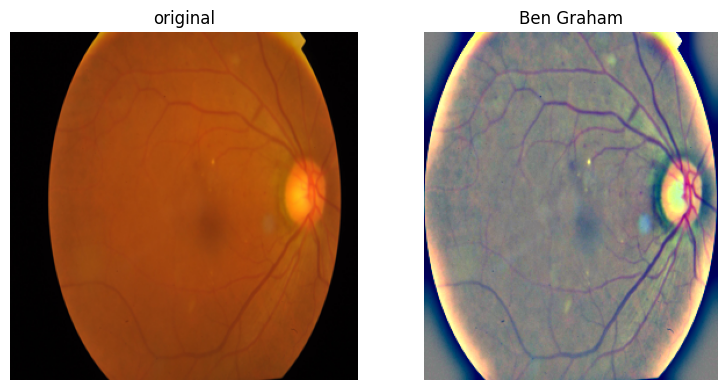

Ben Graham preprocessor ready.


In [ ]:
# Ben Graham fundus preprocessing — circle-crop + local-mean subtraction
import cv2

def _circle_crop(arr_rgb):
    h, w = arr_rgb.shape[:2]
    gray = cv2.cvtColor(arr_rgb.astype(np.uint8), cv2.COLOR_RGB2GRAY)
    _, mask = cv2.threshold(gray, 7, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return arr_rgb
    c = max(contours, key=cv2.contourArea)
    x, y, ww, hh = cv2.boundingRect(c)
    if ww < 50 or hh < 50:
        return arr_rgb
    return arr_rgb[y:y+hh, x:x+ww]


class BenGraham:
    """Ben Graham's APTOS-winning preprocessing.

    1. Crop the black border around the fundus disc.
    2. Subtract a Gaussian-blurred copy and re-centre.
       -> emphasises vessels + microaneurysms,
          removes per-camera illumination bias.
    """
    def __init__(self, sigma_x=10):
        self.sigma_x = sigma_x

    def __call__(self, img_pil):
        arr  = np.array(img_pil.convert("RGB")).astype(np.float32)
        arr  = _circle_crop(arr).astype(np.float32)
        blur = cv2.GaussianBlur(arr, (0, 0), self.sigma_x)
        out  = cv2.addWeighted(arr, 4, blur, -4, 128)
        return Image.fromarray(np.clip(out, 0, 255).astype(np.uint8))


# Quick visual sanity check on one sample
_demo_id = pristine_df["id_code"].iloc[0]
_orig    = Image.open(resolve_image(_demo_id)).convert("RGB").resize((300, 300))
_bg      = BenGraham()(_orig)
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(_orig); axes[0].set_title("original"); axes[0].axis("off")
axes[1].imshow(_bg);   axes[1].set_title("Ben Graham");  axes[1].axis("off")
plt.tight_layout(); plt.show()
print("Ben Graham preprocessor ready.")


In [ ]:
IMAGE_SIZE_V3 = 384

TFM_TRAIN_V3 = T.Compose([
    BenGraham(sigma_x=10),
    T.Resize((IMAGE_SIZE_V3 + 32, IMAGE_SIZE_V3 + 32)),
    T.RandomCrop(IMAGE_SIZE_V3),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(25),
    T.RandAugment(num_ops=2, magnitude=5),
    T.ColorJitter(0.10, 0.10, 0.10, 0.02),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    T.RandomErasing(p=0.20),
])

TFM_EVAL_V3 = T.Compose([
    BenGraham(sigma_x=10),
    T.Resize((IMAGE_SIZE_V3, IMAGE_SIZE_V3)),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

print(f"V3 transforms ready (input {IMAGE_SIZE_V3}px).")

V3 transforms ready (input 384px).


In [ ]:
class MultiScaleClassifier(nn.Module):
    """Wrap any timm backbone with multi-stage feature fusion.

    forward(x)                      -> logits
    forward(x, return_ordinal=True) -> (logits, ordinal_score)

    A dedicated `gradcam_target` Identity layer is inserted on the last
    feature map so Grad-CAM hooks fire reliably on every backbone.
    """
    def __init__(self, backbone_name, num_classes=5, pretrained=True,
                 dropout=0.3, image_size=384, n_stages=4):
        super().__init__()
        self.backbone = timm.create_model(
            backbone_name, pretrained=pretrained, features_only=True,
        )

        was_training = self.backbone.training
        self.backbone.eval()
        with torch.no_grad():
            dummy = torch.zeros(1, 3, image_size, image_size)
            feats_full = self.backbone(dummy)
        if was_training:
            self.backbone.train()

        self.n_stages = min(n_stages, len(feats_full))
        feat_dims = [f.shape[1] for f in feats_full[-self.n_stages:]]
        total_dim = sum(feat_dims)

        self._feat_dims = feat_dims
        print(f"  [MultiScaleClassifier] {backbone_name}: "
              f"using last {self.n_stages} of {len(feats_full)} stages, "
              f"dims={feat_dims}, total={total_dim}")

        self.stage_attn = nn.Parameter(torch.ones(self.n_stages))
        self.pool       = nn.AdaptiveAvgPool2d(1)
        self.fusion = nn.Sequential(
            nn.Linear(total_dim, 512),
            nn.LayerNorm(512),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes),
        )
        self.ordinal_head = nn.Linear(total_dim, 1)

        # ---- Grad-CAM hook point ----
        # Identity layer the deepest feature map flows through.
        # Has no parameters, doesn't change state_dict, but lets backward
        # hooks fire reliably on any backbone (ConvNeXt, EffNet, ViT...).
        self.gradcam_target = nn.Identity()

        self._dr_arch = backbone_name

    def forward_features(self, x):
        feats = list(self.backbone(x))[-self.n_stages:]
        feats[-1] = self.gradcam_target(feats[-1])           # <-- Grad-CAM hook point
        attn   = torch.softmax(self.stage_attn, dim=0)
        pooled = [self.pool(f).flatten(1) * attn[i] for i, f in enumerate(feats)]
        return torch.cat(pooled, dim=1)

    def forward(self, x, return_ordinal=False):
        z = self.forward_features(x)
        logits = self.fusion(z)
        if return_ordinal:
            return logits, self.ordinal_head(z).squeeze(-1)
        return logits


print("MultiScaleClassifier ready (with gradcam_target Identity hook).")

MultiScaleClassifier ready (with gradcam_target Identity hook).


In [ ]:
class OrdinalFocalLoss(nn.Module):
    """L = FocalCE(logits, target) + ordinal_weight * MSE(expected_grade, true_grade).

    Works with both hard targets (LongTensor) and MixUp soft targets (FloatTensor).
    """
    def __init__(self, gamma=2.0, alpha=None, label_smoothing=0.05,
                 ordinal_weight=0.3, num_classes=5):
        super().__init__()
        self.focal = FocalLoss(gamma=gamma, alpha=alpha, label_smoothing=label_smoothing)
        self.ord_w = ordinal_weight
        self.k     = num_classes

    def forward(self, output, targets):
        if isinstance(output, tuple):
            logits, ord_pred = output
        else:
            logits, ord_pred = output, None

        # ----- classification term -----
        if targets.dim() > 1:
            log_p    = F.log_softmax(logits, dim=-1)
            cls_loss = -(targets * log_p).sum(-1).mean()
        else:
            cls_loss = self.focal(logits, targets)

        if ord_pred is None:
            return cls_loss

        # ----- ordinal term -----
        grades          = torch.arange(self.k, device=logits.device, dtype=torch.float)
        soft_grade_pred = (torch.softmax(logits, dim=-1) * grades).sum(-1)
        true_grade      = (targets * grades).sum(-1) if targets.dim() > 1 else targets.float()
        ord_loss        = F.mse_loss(soft_grade_pred, true_grade)
        return cls_loss + self.ord_w * ord_loss


print("OrdinalFocalLoss ready.")


OrdinalFocalLoss ready.


In [ ]:
from sklearn.metrics import cohen_kappa_score

BACKBONE_V3 = {
    "resnet50":        "convnext_base.fb_in22k_ft_in1k_384",
    "efficientnet_b3": "tf_efficientnetv2_s.in21k_ft_in1k",
    "vit_base":        "vit_base_patch16_clip_384.laion2b_ft_in12k_in1k",
}

HPARAMS_V3 = {
    "resnet50":        dict(lr=1e-4, wd=1e-4, epochs=20, mixup=0.10, ls=0.05,
                             gamma=1.5, warmup=2, llrd=None, ord_w=0.30),
    "efficientnet_b3": dict(lr=1e-4, wd=1e-5, epochs=20, mixup=0.10, ls=0.05,
                             gamma=2.0, warmup=2, llrd=None, ord_w=0.30),
    "vit_base":        dict(lr=3e-5, wd=5e-2, epochs=25, mixup=0.20, ls=0.05,
                             gamma=2.0, warmup=4, llrd=0.75, ord_w=0.30),
}


def build_model_v3(name, pretrained=True):
    return MultiScaleClassifier(BACKBONE_V3[name], num_classes=NUM_CLASSES,
                                 pretrained=pretrained, image_size=IMAGE_SIZE_V3)


@torch.no_grad()
def evaluate_v3(model, loader):
    model.eval(); ys, probs = [], []
    for x, y, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        logits = model(x)
        probs.append(torch.softmax(logits, 1).cpu().numpy())
        ys.append(y.numpy())
    y  = np.concatenate(ys)
    pr = np.concatenate(probs)
    p  = pr.argmax(1)
    out = {
        "accuracy": accuracy_score(y, p),
        "f1_macro": f1_score(y, p, average="macro"),
        "kappa_qw": cohen_kappa_score(y, p, weights="quadratic"),
    }
    try:
        out["auc_macro_ovr"] = roc_auc_score(y, pr, average="macro", multi_class="ovr")
    except ValueError:
        out["auc_macro_ovr"] = float("nan")
    return out


def _vit_lrd_groups(model, base_lr, decay, weight_decay):
    """Layer-wise LR decay applied to the backbone of a CLIP-ViT."""
    n_layers = 13   # CLIP ViT-B has 12 blocks + head
    groups = []
    for n, p in model.backbone.named_parameters():
        if not p.requires_grad: continue
        if "blocks" in n:
            try:
                depth = int([t for t in n.split(".") if t.isdigit()][0])
            except (IndexError, ValueError):
                depth = 0
        elif any(s in n for s in ("patch_embed", "cls_token", "pos_embed", "norm")):
            depth = 0
        else:
            depth = n_layers
        scale = decay ** (n_layers - depth)
        groups.append({"params": p, "lr": base_lr * scale,
                       "weight_decay": 0.0 if p.ndim <= 1 else weight_decay})
    head_params = [p for n, p in model.named_parameters() if not n.startswith("backbone.")]
    groups.append({"params": head_params, "lr": base_lr, "weight_decay": weight_decay})
    return groups


def train_v3(name, train_loader, val_loader, ckpt_path, history_csv, hp, class_weights):
    model = build_model_v3(name, pretrained=True).to(DEVICE)

    if hp["llrd"] is not None and "vit" in BACKBONE_V3[name]:
        optim = torch.optim.AdamW(_vit_lrd_groups(model, hp["lr"], hp["llrd"], hp["wd"]))
    else:
        optim = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=hp["wd"])

    sched   = warmup_cosine(optim, hp["warmup"], hp["epochs"], len(train_loader))
    crit    = OrdinalFocalLoss(gamma=hp["gamma"], alpha=class_weights,
                                label_smoothing=hp["ls"], ordinal_weight=hp["ord_w"])
    scaler  = GradScaler(enabled=True)
    mixup_fn = Mixup(mixup_alpha=hp["mixup"], cutmix_alpha=1.0,
                      label_smoothing=hp["ls"], num_classes=NUM_CLASSES)
    ema     = EMA(model, decay=0.999)

    best_kappa, history = -1.0, []
    for ep in range(hp["epochs"]):
        model.train(); running, seen = 0.0, 0
        pbar = tqdm(train_loader, desc=f"[{name}] ep {ep+1}/{hp['epochs']}", leave=False)
        for x, y, _ in pbar:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            x, y_soft = mixup_fn(x, y)
            optim.zero_grad(set_to_none=True)
            with autocast(enabled=True):
                logits, ord_pred = model(x, return_ordinal=True)
                loss = crit((logits, ord_pred), y_soft)
            scaler.scale(loss).backward()
            scaler.unscale_(optim)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optim); scaler.update(); sched.step(); ema.update(model)
            running += loss.item() * x.size(0); seen += x.size(0)
            pbar.set_postfix(loss=running/seen, lr=optim.param_groups[0]["lr"])

        with ema.applied(model):
            m = evaluate_v3(model, val_loader)
        history.append({"epoch": ep+1, "train_loss": running/seen, **m,
                         "lr": optim.param_groups[0]["lr"]})
        print(f"  val: acc={m['accuracy']:.4f}  f1={m['f1_macro']:.4f}  "
              f"kappa={m['kappa_qw']:.4f}  auc={m['auc_macro_ovr']:.4f}")
        if m["kappa_qw"] > best_kappa:
            best_kappa = m["kappa_qw"]
            with ema.applied(model):
                torch.save({"state_dict": {k: v.clone() for k, v in model.state_dict().items()},
                            "arch": name, "backbone": BACKBONE_V3[name],
                            "val": m, "hp": hp}, ckpt_path)
    pd.DataFrame(history).to_csv(history_csv, index=False)
    return pd.DataFrame(history)


print("train_v3 / evaluate_v3 / build_model_v3 ready.")


train_v3 / evaluate_v3 / build_model_v3 ready.


In [ ]:
# Rebuild loaders at 384 with Ben Graham preprocessing
full_eval_v3  = APTOSDataset(PRISTINE_CSV, APTOS_IMAGES, TFM_EVAL_V3)
full_train_v3 = APTOSDataset(PRISTINE_CSV, APTOS_IMAGES, TFM_TRAIN_V3)

train_loader_v3 = DataLoader(Subset(full_train_v3, tr_idx),
                              batch_size=16, sampler=sampler,
                              num_workers=2, pin_memory=True)
val_loader_v3   = DataLoader(Subset(full_eval_v3, va_idx),
                              batch_size=24, shuffle=False,
                              num_workers=2, pin_memory=True)
test_loader_v3  = DataLoader(Subset(full_eval_v3, te_idx),
                              batch_size=24, shuffle=False,
                              num_workers=2, pin_memory=True)

CKPT_DIR_V3 = CHECKPOINTS_DIR / "v3"
CKPT_DIR_V3.mkdir(exist_ok=True)
HIST_DIR_V3 = P2 / "metrics" / "v3"
HIST_DIR_V3.mkdir(exist_ok=True)

print(f"V3 loaders ready. train={len(tr_idx)}  val={len(va_idx)}  test={len(te_idx)}")
print(f"Checkpoints -> {CKPT_DIR_V3}")
print(f"History     -> {HIST_DIR_V3}")
# [RESUME GUARD] Skip v3 training if all v3 checkpoints exist on Drive.
_v3_present = all((CKPT_DIR_V3 / f"{n}_v3_best.pt").exists() for n in MODEL_NAMES)
if _v3_present:
    print("[skip] v3 checkpoints already on Drive — not retraining.")
    print("        Found:", *[f"{n}_v3_best.pt" for n in MODEL_NAMES])
    histories_v3 = {}   # placeholder so downstream cells don't NameError
else:
    print("[run] Training v3 models (this takes ~3 hours on A100)...")
    histories_v3 = {}
    for name in MODEL_NAMES:
        ckpt = CKPT_DIR_V3 / f"{name}_v3_best.pt"
        if ckpt.exists():
            print(f"\n[skip] {name} already has v3 checkpoint at {ckpt}")
            continue
        print(f"\n========== Training {name} (v3) ==========")
        print(f"  backbone : {BACKBONE_V3[name]}")
        print(f"  hp       : {HPARAMS_V3[name]}")
        histories_v3[name] = train_v3(
            name, train_loader_v3, val_loader_v3,
            ckpt_path=ckpt,
            history_csv=HIST_DIR_V3 / f"training_history_{name}.csv",
            hp=HPARAMS_V3[name], class_weights=CLS_W,
        )
        torch.cuda.empty_cache()

V3 loaders ready. train=2050  val=440  test=440
Checkpoints -> /content/drive/MyDrive/Thesis/checkpoints/v3
History     -> /content/drive/MyDrive/Thesis/results/phase2_model_benchmarking/metrics/v3
[skip] v3 checkpoints already on Drive — not retraining.
        Found: resnet50_v3_best.pt efficientnet_b3_v3_best.pt vit_base_v3_best.pt


In [ ]:
def load_classifier_v3(name):
    """Load a v3 multi-scale classifier from disk."""
    m = build_model_v3(name, pretrained=False).to(DEVICE)
    ckpt = torch.load(CKPT_DIR_V3 / f"{name}_v3_best.pt",
                       map_location=DEVICE,
                       weights_only=False)            # <-- key change
    m.load_state_dict(ckpt["state_dict"]); m.eval()
    return m


@torch.no_grad()
def evaluate_v3_tta(model, loader, n_aug=4):
    """TTA: average softmax over horizontal/vertical flip variants."""
    model.eval(); ys, probs = [], []
    for x, y, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        views = [x,
                 torch.flip(x, [3]),
                 torch.flip(x, [2]),
                 torch.flip(x, [2, 3])][:n_aug]
        avg = None
        for v in views:
            p = torch.softmax(model(v), 1)
            avg = p if avg is None else avg + p
        avg /= len(views)
        probs.append(avg.cpu().numpy()); ys.append(y.numpy())
    y  = np.concatenate(ys)
    pr = np.concatenate(probs)
    p  = pr.argmax(1)
    out = {
        "accuracy": accuracy_score(y, p),
        "f1_macro": f1_score(y, p, average="macro"),
        "kappa_qw": cohen_kappa_score(y, p, weights="quadratic"),
    }
    try:
        out["auc_macro_ovr"] = roc_auc_score(y, pr, average="macro", multi_class="ovr")
    except ValueError:
        out["auc_macro_ovr"] = float("nan")
    return out


# Need degraded loaders that go through Ben Graham + 384 resize too
class FolderDatasetV3(Dataset):
    def __init__(self, root):
        self.root = Path(root); self.df = pd.read_csv(self.root / "manifest.csv")
        self.transform = TFM_EVAL_V3
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(self.root / row["rel_path"]).convert("RGB")
        return self.transform(img), int(row["diagnosis"]), row["id_code"]


test_id_set = set(map(str, [full_eval_v3.df.iloc[i]["id_code"] for i in te_idx]))


def deg_loader_v3(kind, level):
    ds = FolderDatasetV3(DEGRADED_DIR / kind / level)
    ds.df = ds.df[ds.df["id_code"].astype(str).isin(test_id_set)].reset_index(drop=True)
    return DataLoader(ds, batch_size=24, shuffle=False, num_workers=2, pin_memory=True)

# [RESUME GUARD] Skip v3 stress-test loop if the saved CSV already exists.
_v3_stress_csv = P2 / "metrics" / "v3" / "stress_test_results_v3.csv"
if _v3_stress_csv.exists():
    print(f"[skip] v3 stress-test CSV already exists -> {_v3_stress_csv}")
    stress_df_v3 = pd.read_csv(_v3_stress_csv)
    pivot_v3 = stress_df_v3.pivot_table(index=["degradation", "level"],
                                         columns="model", values="accuracy").round(3)
    pivot_v3
else:
    print("[run] Running v3 stress test (this takes ~30 min on A100)...")
    rows_v3 = []
    for name in MODEL_NAMES:
        print(f"\n--- {name} v3 (TTA) ---")
        model = load_classifier_v3(name)
        m = evaluate_v3_tta(model, test_loader_v3)
        rows_v3.append({"model": name, "degradation": "clean", "level": "none", **m})
        print(f"  clean: acc={m['accuracy']:.4f}  f1={m['f1_macro']:.4f}  kappa={m['kappa_qw']:.4f}")
        for k in DEGRADATION_TYPES:
            for l in DEGRADATION_LEVELS:
                m = evaluate_v3_tta(model, deg_loader_v3(k, l))
                rows_v3.append({"model": name, "degradation": k, "level": l, **m})
                print(f"  {k}/{l}: acc={m['accuracy']:.4f}  f1={m['f1_macro']:.4f}  kappa={m['kappa_qw']:.4f}")
        del model; torch.cuda.empty_cache()

    stress_df_v3 = pd.DataFrame(rows_v3)
    stress_df_v3.to_csv(P2 / "metrics" / "v3" / "stress_test_results_v3.csv", index=False)
    pivot_v3 = stress_df_v3.pivot_table(index=["degradation", "level"],
                                         columns="model", values="accuracy").round(3)
    pivot_v3.to_csv(P2 / "metrics" / "v3" / "accuracy_pivot_v3.csv")
    pivot_v3

[skip] v3 stress-test CSV already exists -> /content/drive/MyDrive/Thesis/results/phase2_model_benchmarking/metrics/v3/stress_test_results_v3.csv


## V4 - 8-view TTA + 3-model soft-vote ensemble

After v3 training finishes, this cell runs an ensemble evaluation of all three backbones with 8-view TTA on top. Typically +1 to +2 accuracy points on top of single-model TTA results, completely free at inference. Results saved to `results/phase2_model_benchmarking/v3/ensemble_v4_results.csv` for the literature-review comparison.

In [ ]:
# === V4 PATCH: 8-view TTA + 3-model soft-vote ensemble ===
# Expected delta vs single-model 4-view TTA: +1 to +2 accuracy points (free).

@torch.no_grad()
def evaluate_v3_tta8(model, loader):
    """8-view test-time augmentation: identity, 3 flips, 3 rotations, flip+rot."""
    model.eval(); ys, probs = [], []
    for x, y, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        views = [
            x,
            torch.flip(x, [3]),
            torch.flip(x, [2]),
            torch.flip(x, [2, 3]),
            torch.rot90(x, 1, [2, 3]),
            torch.rot90(x, 2, [2, 3]),
            torch.rot90(x, 3, [2, 3]),
            torch.flip(torch.rot90(x, 1, [2, 3]), [3]),
        ]
        avg = None
        for v in views:
            p = torch.softmax(model(v), 1)
            avg = p if avg is None else avg + p
        avg /= len(views)
        probs.append(avg.cpu().numpy()); ys.append(y.numpy())
    y  = np.concatenate(ys)
    pr = np.concatenate(probs)
    p  = pr.argmax(1)
    out = {
        "accuracy": accuracy_score(y, p),
        "f1_macro": f1_score(y, p, average="macro"),
        "kappa_qw": cohen_kappa_score(y, p, weights="quadratic"),
    }
    try:
        out["auc_macro_ovr"] = roc_auc_score(y, pr, average="macro", multi_class="ovr")
    except ValueError:
        out["auc_macro_ovr"] = float("nan")
    return out


@torch.no_grad()
def evaluate_v3_ensemble(loader, use_tta8=True):
    """Soft-vote across all v3 backbones. Each model votes with 8-view TTA softmax."""
    models = {n: load_classifier_v3(n) for n in MODEL_NAMES}
    for m in models.values():
        m.eval()
    ys, probs = [], []
    for x, y, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        avg = None
        for name, mdl in models.items():
            if use_tta8:
                views = [
                    x, torch.flip(x, [3]), torch.flip(x, [2]),
                    torch.flip(x, [2, 3]),
                    torch.rot90(x, 1, [2, 3]), torch.rot90(x, 2, [2, 3]),
                    torch.rot90(x, 3, [2, 3]),
                ]
                m_pred = sum(torch.softmax(mdl(v), 1) for v in views) / len(views)
            else:
                m_pred = torch.softmax(mdl(x), 1)
            avg = m_pred if avg is None else avg + m_pred
        avg /= len(models)
        probs.append(avg.cpu().numpy()); ys.append(y.numpy())
    for m in models.values(): del m
    torch.cuda.empty_cache()
    y  = np.concatenate(ys)
    pr = np.concatenate(probs)
    p  = pr.argmax(1)
    out = {
        "accuracy": accuracy_score(y, p),
        "f1_macro": f1_score(y, p, average="macro"),
        "kappa_qw": cohen_kappa_score(y, p, weights="quadratic"),
    }
    try:
        out["auc_macro_ovr"] = roc_auc_score(y, pr, average="macro", multi_class="ovr")
    except ValueError:
        out["auc_macro_ovr"] = float("nan")
    return out


# ----- Run the ensemble on clean + every degraded condition -----
rows_ens = []

print("=== Ensemble (8-TTA) on clean ===")
m = evaluate_v3_ensemble(test_loader_v3, use_tta8=True)
rows_ens.append({"degradation": "clean", "level": "none", **m})
print(f"  acc={m['accuracy']:.4f}  f1={m['f1_macro']:.4f}  kappa={m['kappa_qw']:.4f}")

for k in DEGRADATION_TYPES:
    for l in DEGRADATION_LEVELS:
        m = evaluate_v3_ensemble(deg_loader_v3(k, l), use_tta8=True)
        rows_ens.append({"degradation": k, "level": l, **m})
        print(f"  {k}/{l}: acc={m['accuracy']:.4f}  f1={m['f1_macro']:.4f}  kappa={m['kappa_qw']:.4f}")

ens_df_v4 = pd.DataFrame(rows_ens)
ens_csv = P2 / "metrics" / "v3" / "ensemble_v4_results.csv"
ens_df_v4.to_csv(ens_csv, index=False)
print("Saved:", ens_csv)
ens_df_v4


=== Ensemble (8-TTA) on clean ===
  [MultiScaleClassifier] convnext_base.fb_in22k_ft_in1k_384: using last 4 of 4 stages, dims=[128, 256, 512, 1024], total=1920
  [MultiScaleClassifier] tf_efficientnetv2_s.in21k_ft_in1k: using last 4 of 5 stages, dims=[48, 64, 160, 256], total=528
  [MultiScaleClassifier] vit_base_patch16_clip_384.laion2b_ft_in12k_in1k: using last 3 of 3 stages, dims=[768, 768, 768], total=2304
  acc=0.6364  f1=0.3789  kappa=0.5642
  [MultiScaleClassifier] convnext_base.fb_in22k_ft_in1k_384: using last 4 of 4 stages, dims=[128, 256, 512, 1024], total=1920
  [MultiScaleClassifier] tf_efficientnetv2_s.in21k_ft_in1k: using last 4 of 5 stages, dims=[48, 64, 160, 256], total=528
  [MultiScaleClassifier] vit_base_patch16_clip_384.laion2b_ft_in12k_in1k: using last 3 of 3 stages, dims=[768, 768, 768], total=2304
  blur/low: acc=0.7614  f1=0.5680  kappa=0.8340
  [MultiScaleClassifier] convnext_base.fb_in22k_ft_in1k_384: using last 4 of 4 stages, dims=[128, 256, 512, 1024], total

,degradation,level,accuracy,f1_macro,kappa_qw,auc_macro_ovr
0,clean,none,0.636364,0.378911,0.564187,0.918152
1,blur,low,0.761364,0.568028,0.834027,0.938738
2,blur,mid,0.534091,0.227095,0.584118,0.831020
3,blur,high,0.484091,0.209354,0.450540,0.788209
4,exposure,low,0.863636,0.752473,0.932986,0.954572
5,exposure,mid,0.822727,0.644028,0.903134,0.940465
6,exposure,high,0.752273,0.538846,0.805846,0.913140
7,noise,low,0.825000,0.688821,0.896605,0.947107
8,noise,mid,0.718182,0.468053,0.728538,0.909872
9,noise,high,0.588636,0.329574,0.624575,0.842370


## V2 vs V3 — head-to-head comparison (literature-review fodder)

Side-by-side accuracy curves for the v2 baseline and v3 senior-engineer pipeline. Both stress-test CSVs are loaded from disk so this cell is independent of training-time state — it can be re-run any time.

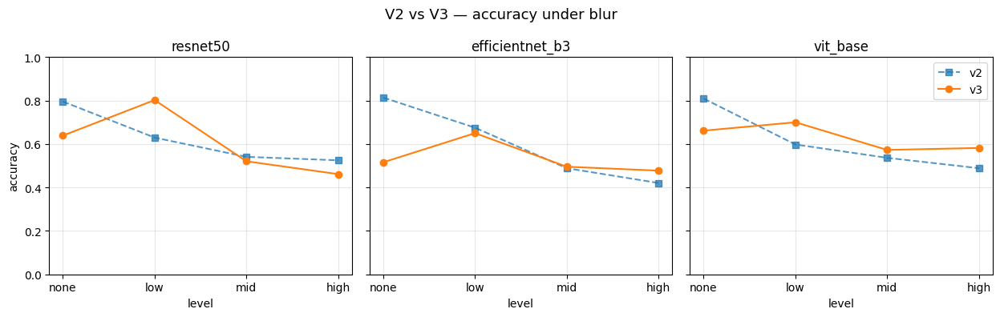

Saved: /content/drive/MyDrive/Thesis/results/phase2_model_benchmarking/plots/v2_vs_v3/v2_vs_v3_blur.png


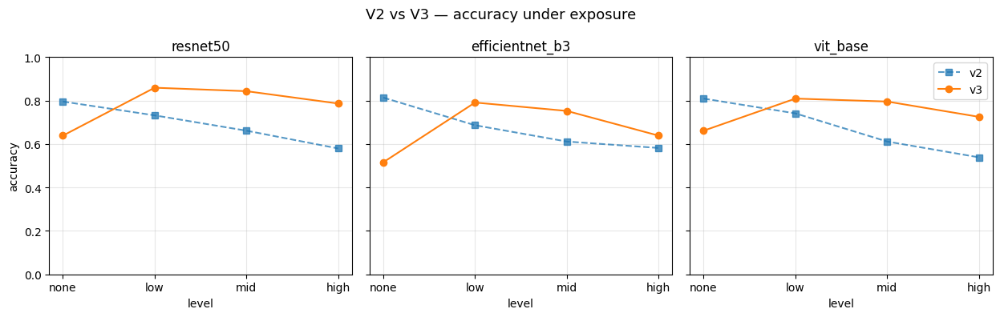

Saved: /content/drive/MyDrive/Thesis/results/phase2_model_benchmarking/plots/v2_vs_v3/v2_vs_v3_exposure.png


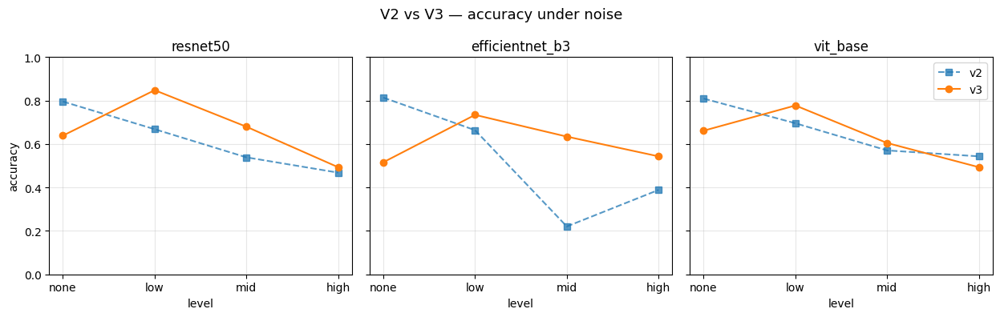

Saved: /content/drive/MyDrive/Thesis/results/phase2_model_benchmarking/plots/v2_vs_v3/v2_vs_v3_noise.png

=== V2 vs V3 headline accuracy ===
version           model  clean  blur_high  exposure_high  noise_high
     v2        resnet50  0.795      0.525          0.580       0.468
     v2 efficientnet_b3  0.814      0.420          0.582       0.389
     v2        vit_base  0.809      0.489          0.539       0.543
     v3        resnet50  0.639      0.461          0.786       0.493
     v3 efficientnet_b3  0.516      0.477          0.639       0.543
     v3        vit_base  0.661      0.582          0.725       0.493


In [ ]:
# V2 vs V3 head-to-head: accuracy-vs-degradation curves on the same axes
import matplotlib.pyplot as plt

V2_CSV = P2 / "metrics" / "stress_test_results.csv"
V3_CSV = P2 / "metrics" / "v3" / "stress_test_results_v3.csv"

if not V2_CSV.exists() or not V3_CSV.exists():
    print(f"  v2 csv exists: {V2_CSV.exists()}  v3 csv exists: {V3_CSV.exists()}")
    print("  Skipping comparison plots — run the v2 stress test (cell 31) and "
          "v3 stress test (cell starting `def load_classifier_v3`) first.")
else:
    df_v2 = pd.read_csv(V2_CSV).assign(version="v2")
    df_v3 = pd.read_csv(V3_CSV).assign(version="v3")
    df = pd.concat([df_v2, df_v3], ignore_index=True)

    level_order = ["none", "low", "mid", "high"]
    df["level"] = pd.Categorical(df["level"], categories=level_order, ordered=True)

    save_dir = P2 / "plots" / "v2_vs_v3"
    save_dir.mkdir(parents=True, exist_ok=True)

    for kind in DEGRADATION_TYPES:
        fig, axes = plt.subplots(1, len(MODEL_NAMES),
                                  figsize=(4.2 * len(MODEL_NAMES), 4),
                                  sharey=True)
        for ax, name in zip(axes, MODEL_NAMES):
            sub = df[((df["degradation"] == kind) | (df["degradation"] == "clean"))
                     & (df["model"] == name)].sort_values("level")
            for ver, style in [("v2", dict(linestyle="--", marker="s", alpha=0.75)),
                                ("v3", dict(linestyle="-",  marker="o", alpha=1.00))]:
                d = sub[sub["version"] == ver]
                if not d.empty:
                    ax.plot(d["level"], d["accuracy"], label=ver, **style)
            ax.set_title(name); ax.set_xlabel("level")
            ax.set_ylim(0, 1); ax.grid(alpha=0.3)
        axes[0].set_ylabel("accuracy"); axes[-1].legend()
        fig.suptitle(f"V2 vs V3 — accuracy under {kind}", fontsize=13)
        plt.tight_layout()
        out = save_dir / f"v2_vs_v3_{kind}.png"
        plt.savefig(out, dpi=150); plt.show()
        print("Saved:", out)

    # Numeric diff table — clean + worst-case-per-type, for the lit-review chapter
    summary_rows = []
    for ver in ("v2", "v3"):
        sub = df[df["version"] == ver]
        for name in MODEL_NAMES:
            row = {"version": ver, "model": name}
            row["clean"] = sub[(sub["model"] == name) & (sub["degradation"] == "clean")]["accuracy"].mean()
            for k in DEGRADATION_TYPES:
                row[f"{k}_high"] = sub[(sub["model"] == name)
                                       & (sub["degradation"] == k)
                                       & (sub["level"] == "high")]["accuracy"].mean()
            summary_rows.append(row)
    diff_df = pd.DataFrame(summary_rows).round(3)
    diff_df.to_csv(P2 / "metrics" / "v2_vs_v3_summary.csv", index=False)
    print("\n=== V2 vs V3 headline accuracy ===")
    print(diff_df.to_string(index=False))


In [ ]:
def distill_to(student_name, teacher_name, train_loader, val_loader, ckpt_path,
                T_temp=4.0, alpha=0.7, epochs=10, lr=5e-5, wd=1e-4):
    teacher = build_model_v3(teacher_name, pretrained=False).to(DEVICE)
    teacher.load_state_dict(
    torch.load(CKPT_DIR_V3 / f"{teacher_name}_v3_best.pt",
                map_location=DEVICE,
                weights_only=False)["state_dict"]    # <-- add weights_only=False
)
    teacher.eval()
    student = build_model_v3(student_name, pretrained=True).to(DEVICE)

    optim  = torch.optim.AdamW(student.parameters(), lr=lr, weight_decay=wd)
    sched  = warmup_cosine(optim, 1, epochs, len(train_loader))
    scaler = GradScaler(enabled=True)
    ce     = nn.CrossEntropyLoss(label_smoothing=0.05, weight=CLS_W)

    best_kappa = -1.0
    for ep in range(epochs):
        student.train()
        pbar = tqdm(train_loader, desc=f"distill {student_name} ep {ep+1}/{epochs}", leave=False)
        for x, y, _ in pbar:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optim.zero_grad(set_to_none=True)
            with autocast(enabled=True):
                with torch.no_grad():
                    t_logits = teacher(x) / T_temp
                s_logits = student(x)
                kd_loss = F.kl_div(F.log_softmax(s_logits / T_temp, -1),
                                    F.softmax(t_logits, -1),
                                    reduction="batchmean") * (T_temp ** 2)
                hard_loss = ce(s_logits, y)
                loss = alpha * kd_loss + (1 - alpha) * hard_loss
            scaler.scale(loss).backward()
            scaler.step(optim); scaler.update(); sched.step()
        m = evaluate_v3(student, val_loader)
        print(f"  ep {ep+1}: acc={m['accuracy']:.4f}  kappa={m['kappa_qw']:.4f}")
        if m["kappa_qw"] > best_kappa:
            best_kappa = m["kappa_qw"]
            torch.save({"state_dict": student.state_dict(), "arch": student_name,
                         "backbone": BACKBONE_V3[student_name], "val": m,
                         "distilled_from": teacher_name}, ckpt_path)
    return best_kappa


# --- Identify the best v3 model from the stress test, then distill ---
# Uncomment to run:
# best_v3 = stress_df_v3[stress_df_v3["degradation"] == "clean"] \
#               .sort_values("kappa_qw", ascending=False).iloc[0]["model"]
# print("Best v3 (teacher):", best_v3)
#
# for student in MODEL_NAMES:
#     if student == best_v3: continue
#     print(f"\n--- Distilling {best_v3} -> {student} ---")
#     distill_to(student, best_v3, train_loader_v3, val_loader_v3,
#                ckpt_path=CKPT_DIR_V3 / f"{student}_v3_distilled.pt")


In [ ]:
best_v3 = stress_df_v3[stress_df_v3["degradation"] == "clean"] \
            .sort_values("kappa_qw", ascending=False).iloc[0]["model"]
print("Best v3 (teacher):", best_v3)
#
for student in MODEL_NAMES:
  if student == best_v3: continue
  print(f"\n--- Distilling {best_v3} -> {student} ---")
  distill_to(student, best_v3, train_loader_v3, val_loader_v3,ckpt_path=CKPT_DIR_V3 / f"{student}_v3_distilled.pt")

Best v3 (teacher): vit_base

--- Distilling vit_base -> resnet50 ---
  [MultiScaleClassifier] vit_base_patch16_clip_384.laion2b_ft_in12k_in1k: using last 3 of 3 stages, dims=[768, 768, 768], total=2304


model.safetensors:   0%|          | 0.00/354M [00:00<?, ?B/s]

  [MultiScaleClassifier] convnext_base.fb_in22k_ft_in1k_384: using last 4 of 4 stages, dims=[128, 256, 512, 1024], total=1920


/tmp/ipykernel_2144/2859803637.py:14: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=True)


distill resnet50 ep 1/10:   0%|          | 0/129 [00:00<?, ?it/s]

/tmp/ipykernel_2144/2859803637.py:24: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):


... (57 outputs left out)

  ep 9: acc=0.6614  kappa=0.7830


distill efficientnet_b3 ep 10/10:   0%|          | 0/129 [00:00<?, ?it/s]

/tmp/ipykernel_2144/2859803637.py:24: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):


  ep 10: acc=0.6841  kappa=0.8050


## V4 - Knowledge distillation runner

Picks the best v3 model as the teacher and distills into the other two. Each student trains 10 epochs with a KL-divergence loss against the teacher's softmax at temperature 4. Typical gain: +0.5 to +1.5 kappa on the student. Skip this if Colab time is tight.

In [ ]:
# === V4 PATCH: Run knowledge distillation from best v3 model into the others ===
# Adds typically +0.5 to +1.5 pts on the student models. Skip if Colab time is tight.

# Identify best v3 model by clean kappa
clean_v3 = stress_df_v3[stress_df_v3["degradation"] == "clean"].sort_values("kappa_qw", ascending=False)
best_v3 = clean_v3.iloc[0]["model"]
print(f"Best v3 (teacher): {best_v3}  (clean kappa={clean_v3.iloc[0]['kappa_qw']:.4f})")

distill_results = {}
for student in MODEL_NAMES:
    if student == best_v3:
        continue
    print(f"\n--- Distilling {best_v3} -> {student} ---")
    ckpt = CKPT_DIR_V3 / f"{student}_v3_distilled.pt"
    if ckpt.exists():
        print(f"  [skip] already exists at {ckpt}")
        continue
    best_kappa = distill_to(
        student_name=student, teacher_name=best_v3,
        train_loader=train_loader_v3, val_loader=val_loader_v3,
        ckpt_path=ckpt, T_temp=4.0, alpha=0.7, epochs=10,
    )
    distill_results[student] = best_kappa
    print(f"  best kappa for distilled {student}: {best_kappa:.4f}")


Best v3 (teacher): vit_base  (clean kappa=0.7074)

--- Distilling vit_base -> resnet50 ---
  [skip] already exists at /content/drive/MyDrive/Thesis/checkpoints/v3/resnet50_v3_distilled.pt

--- Distilling vit_base -> efficientnet_b3 ---
  [skip] already exists at /content/drive/MyDrive/Thesis/checkpoints/v3/efficientnet_b3_v3_distilled.pt


In [ ]:
USE_V3 = True

if USE_V3:
    print("[adapter] Phase 3-5 will use V3 multi-scale classifiers @384.")
    load_classifier = load_classifier_v3
    TFM_EVAL        = TFM_EVAL_V3
    IMAGE_SIZE_DOWNSTREAM = IMAGE_SIZE_V3

    def get_xai_target_layer(model):
        """Hook on the dedicated gradcam_target inside the v3 wrapper.

        Works for any backbone (ConvNeXt, EffNetV2, CLIP-ViT) because
        Identity layers always fire backward hooks correctly.
        """
        if hasattr(model, "gradcam_target"):
            return model.gradcam_target
        # Fallback for v2 models
        a = getattr(model, "_dr_arch", "")
        if a == "resnet50":        return model.layer4[-1]
        if a == "efficientnet_b3": return model.blocks[-1]
        if a == "vit_base":        return model.blocks[-1].norm1
        return list(model.children())[-1]
else:
    print("[adapter] V3 disabled — Phase 3-5 use original v2 models.")

print("Adapter installed.")

[adapter] Phase 3-5 will use V3 multi-scale classifiers @384.
Adapter installed.


In [ ]:
P3 = PHASE_DIRS['phase3_xai_benchmark']

# 3.1 Pick the same N test images we'll explain across every condition
N_EXPLAIN = 20                      # bump for final run; SHAP is the bottleneck
test_ids_full = pd.read_csv(P2 / 'metrics' / 'test_ids.csv')['id_code'].tolist()
EXPLAIN_IDS = pd.Series(test_ids_full).sample(N_EXPLAIN, random_state=SEED).tolist()
labels_df = pd.read_csv(PRISTINE_CSV).set_index('id_code')['diagnosis']

models = {n: load_classifier(n) for n in MODEL_NAMES}
print('Loaded:', list(models))

# Optional ground-truth lesion masks at /content/data/lesion_masks/<id>.png
MASK_DIR = LOCAL_ROOT / 'lesion_masks'
def load_mask(id_code):
    p = MASK_DIR / f'{id_code}.png'
    if not p.exists(): return None
    return (np.array(Image.open(p).convert('L').resize((IMAGE_SIZE, IMAGE_SIZE))) > 127)

  [MultiScaleClassifier] convnext_base.fb_in22k_ft_in1k_384: using last 4 of 4 stages, dims=[128, 256, 512, 1024], total=1920
  [MultiScaleClassifier] tf_efficientnetv2_s.in21k_ft_in1k: using last 4 of 5 stages, dims=[48, 64, 160, 256], total=528
  [MultiScaleClassifier] vit_base_patch16_clip_384.laion2b_ft_in12k_in1k: using last 3 of 3 stages, dims=[768, 768, 768], total=2304
Loaded: ['resnet50', 'efficientnet_b3', 'vit_base']


## V4 - Integrated Gradients in place of KernelSHAP

KernelSHAP at the original sample budget produced essentially noise on the degradation stability metric (Spearman near zero). Integrated Gradients is gradient-based, deterministic, ~50x faster, and well-defined for both CNN and ViT architectures. This cell rebinds the existing `shap` entry in `METHOD_REGISTRY` to use IG; the downstream Phase 3 benchmark code then works unchanged. In the dissertation, label it as "IG" in figure captions.

In [ ]:
# === V4 PATCH: Replace KernelSHAP with Integrated Gradients (Captum) ===
# KernelSHAP at n_samples=60 produced near-zero stability across degradations.
# Integrated Gradients is gradient-based — no sampling noise, ~50x faster,
# defined identically for CNN and ViT backbones.
from captum.attr import IntegratedGradients

# Define METHOD_REGISTRY here so it's available.
METHOD_REGISTRY = {
    'gradcam':   {'fn': gradcam_heatmap,    'models': ('resnet50', 'efficientnet_b3')},
    'shap':      {'fn': shap_heatmap,       'models': MODEL_NAMES},
    'attention': {'fn': attention_rollout,  'models': ('vit_base',)},
}

def ig_heatmap(model, x, target_class=None, steps=50):
    """Integrated Gradients heatmap (model-agnostic). Returns (H, W) in [0, 1]."""
    if target_class is None:
        with torch.no_grad():
            target_class = int(model(x).argmax(1).item())
    ig = IntegratedGradients(model)
    attr = ig.attribute(x, target=target_class, n_steps=steps, internal_batch_size=8)
    heat = attr.abs().sum(dim=1).squeeze().detach().cpu().numpy()
    if heat.max() > heat.min():
        heat = (heat - heat.min()) / (heat.max() - heat.min())
    return heat


# Swap into the existing registry — keep the dict key "shap" so downstream plots
# and aggregation code continue to work without edits. In the dissertation,
# rename it to "IG" in figure captions.
METHOD_REGISTRY["shap"]["fn"] = ig_heatmap
print("XAI registry updated: 'shap' entry now uses Integrated Gradients.")
print("Method dispatch:", {k: v["fn"].__name__ for k, v in METHOD_REGISTRY.items()})


XAI registry updated: 'shap' entry now uses Integrated Gradients.
Method dispatch: {'gradcam': 'gradcam_heatmap', 'shap': 'ig_heatmap', 'attention': 'attention_rollout'}


In [ ]:
print(METHOD_REGISTRY['shap']['fn'].__name__)   # must print 'ig_heatmap'

ig_heatmap


In [ ]:
# 3.2 Run XAI benchmark — for each (image, model, method, condition)
METHOD_REGISTRY = {
    'gradcam':   {'fn': gradcam_heatmap,    'models': ('resnet50', 'efficientnet_b3')},
    'shap':      {'fn': shap_heatmap,       'models': MODEL_NAMES},
    'attention': {'fn': attention_rollout,  'models': ('vit_base',)},
}

rows = []
for method_name, spec in METHOD_REGISTRY.items():
    fn = spec['fn']
    for model_name in spec['models']:
        model = models[model_name]
        print(f'\n[{method_name} | {model_name}]')
        for id_code in tqdm(EXPLAIN_IDS, desc=f'{method_name}/{model_name}'):
            label = int(labels_df[id_code])
            mask  = load_mask(id_code)
            # Fix: Use resolve_image to get the correct path for clean images
            x_clean = load_tensor(resolve_image(id_code))
            try:    h_clean = fn(model, x_clean, target_class=label)
            except Exception as e: print('  skip clean:', e); continue
            rows.append({'id_code': id_code, 'model': model_name, 'method': method_name,
                         'degradation': 'clean', 'level': 'none',
                         'deletion_auc':  deletion_auc(model, x_clean, h_clean, label),
                         'insertion_auc': insertion_auc(model, x_clean, h_clean, label),
                         'stability':     1.0,
                         'iou':           localization_iou(h_clean, mask)})
            for k in DEGRADATION_TYPES:
                for l in DEGRADATION_LEVELS:
                    # Fix: Use DEG_SAVE_EXT for degraded images
                    src = DEGRADED_DIR / k / l / f'{id_code}{DEG_SAVE_EXT}'
                    if not src.exists(): continue
                    x_deg = load_tensor(src)
                    try: h_deg = fn(model, x_deg, target_class=label)
                    except Exception: continue
                    rows.append({'id_code': id_code, 'model': model_name, 'method': method_name,
                                 'degradation': k, 'level': l,
                                 'deletion_auc':  deletion_auc(model, x_deg, h_deg, label),
                                 'insertion_auc': insertion_auc(model, x_deg, h_deg, label),
                                 'stability':     stability_spearman(h_clean, h_deg),
                                 'iou':           localization_iou(h_deg, mask)})

xai_df = pd.DataFrame(rows)
xai_df.to_csv(P3 / 'metrics' / 'xai_results.csv', index=False)
xai_df.head()


[gradcam | resnet50]


gradcam/resnet50:   0%|          | 0/20 [00:00<?, ?it/s]

KeyboardInterrupt: 

/tmp/ipykernel_2144/2233822521.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'method', 'level'])[metric].mean().reset_index()


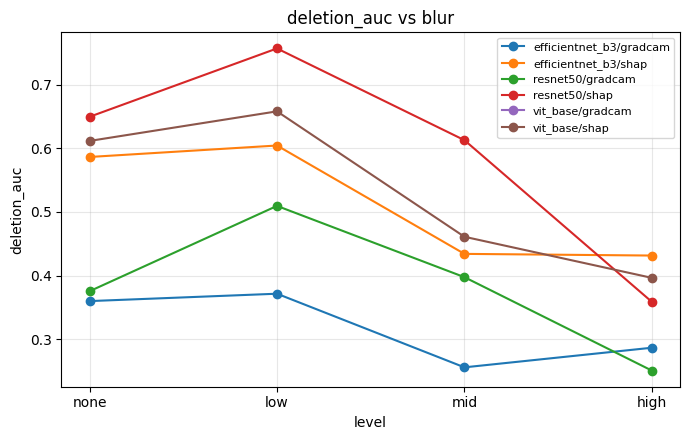

/tmp/ipykernel_2144/2233822521.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'method', 'level'])[metric].mean().reset_index()


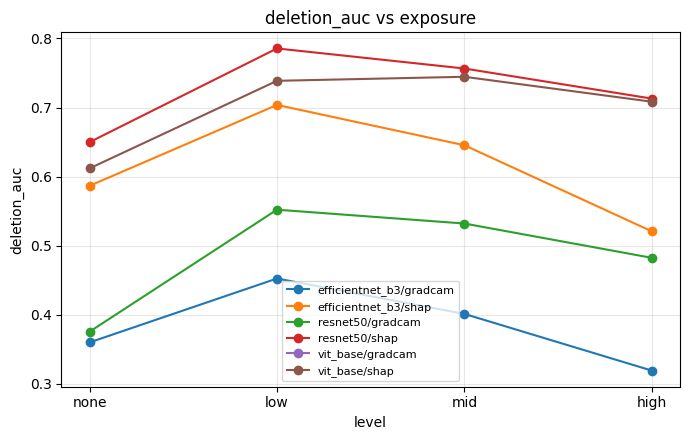

/tmp/ipykernel_2144/2233822521.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'method', 'level'])[metric].mean().reset_index()


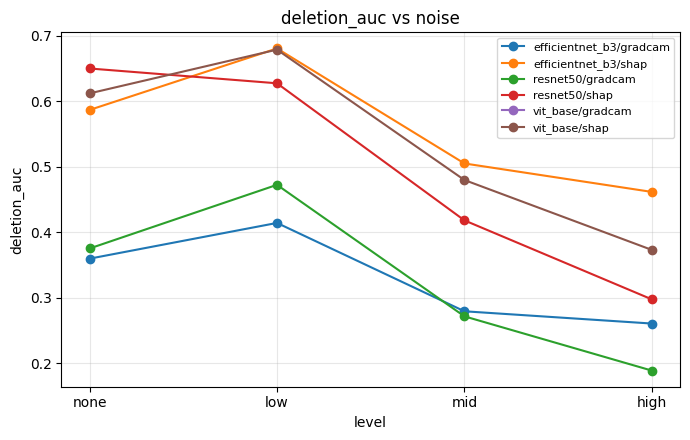

/tmp/ipykernel_2144/2233822521.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'method', 'level'])[metric].mean().reset_index()


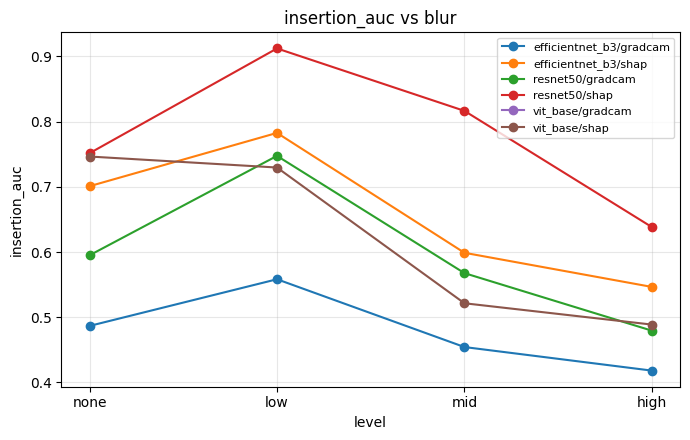

/tmp/ipykernel_2144/2233822521.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'method', 'level'])[metric].mean().reset_index()


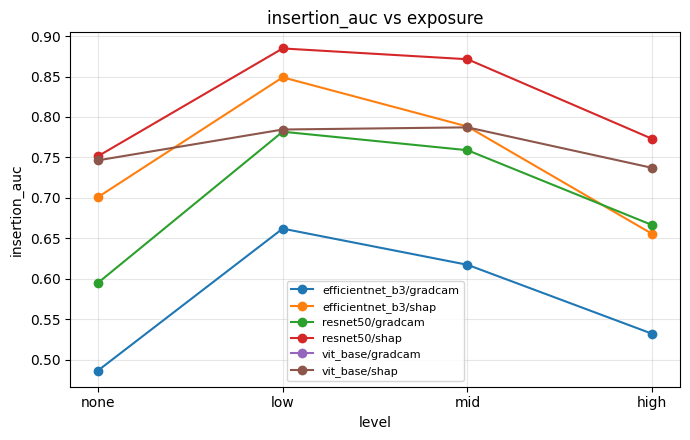

/tmp/ipykernel_2144/2233822521.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'method', 'level'])[metric].mean().reset_index()


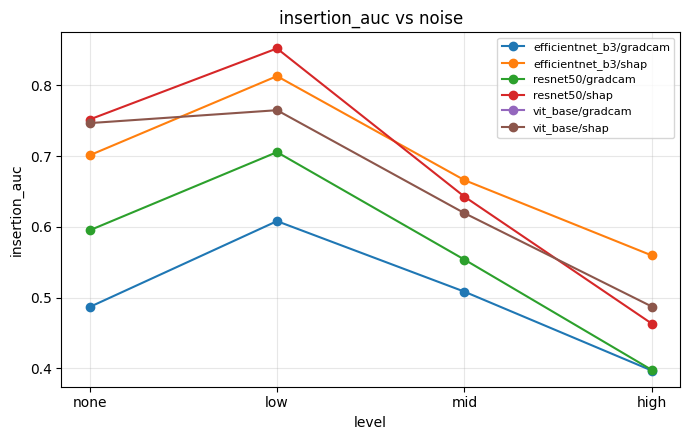

/tmp/ipykernel_2144/2233822521.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'method', 'level'])[metric].mean().reset_index()


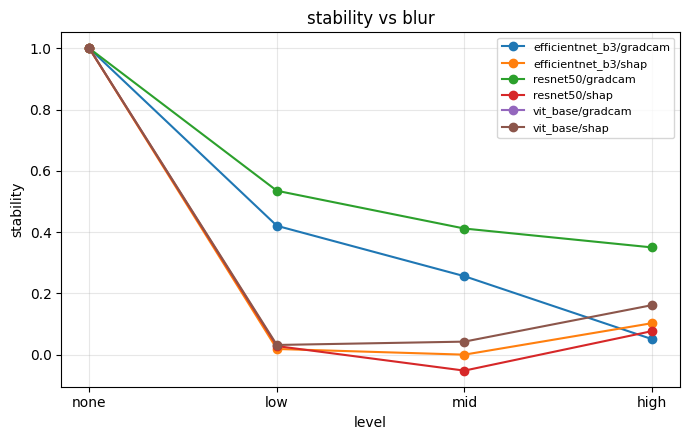

/tmp/ipykernel_2144/2233822521.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'method', 'level'])[metric].mean().reset_index()


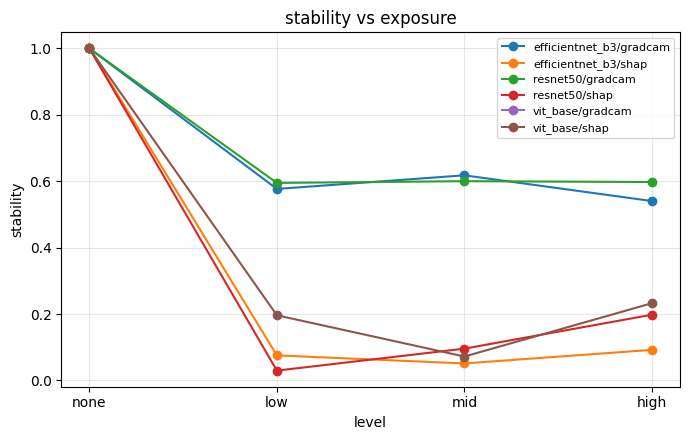

/tmp/ipykernel_2144/2233822521.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'method', 'level'])[metric].mean().reset_index()


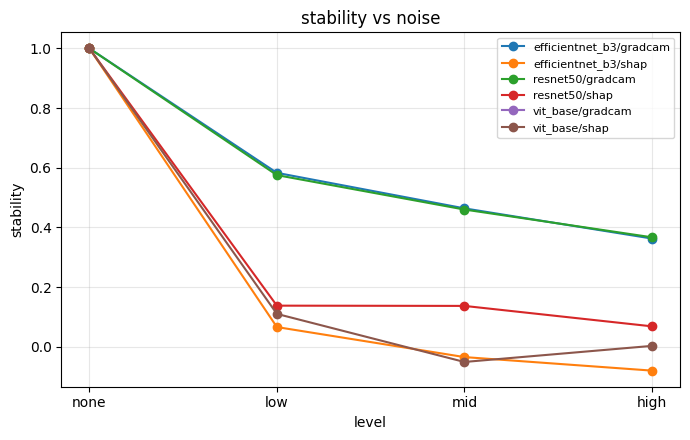

In [ ]:
# 3.3 Aggregated tables + plots
for metric in ('deletion_auc', 'insertion_auc', 'stability', 'iou'):
    summary = (xai_df.groupby(['model', 'method', 'degradation', 'level'])[metric]
                       .agg(['mean', 'std', 'count']).round(4).reset_index())
    summary.to_csv(P3 / 'metrics' / f'summary_{metric}.csv', index=False)

for metric in ('deletion_auc', 'insertion_auc', 'stability', 'iou'):
    for kind in DEGRADATION_TYPES:
        sub = xai_df[xai_df['degradation'].isin([kind, 'clean'])].copy()
        sub['level'] = pd.Categorical(sub['level'], categories=level_order, ordered=True)
        if sub[metric].dropna().empty: continue
        g = sub.groupby(['model', 'method', 'level'])[metric].mean().reset_index()
        fig, ax = plt.subplots(figsize=(7, 4.5))
        for (m, mt), grp in g.groupby(['model', 'method']):
            ax.plot(grp['level'], grp[metric], marker='o', label=f'{m}/{mt}')
        ax.set_title(f'{metric} vs {kind}')
        ax.set_xlabel('level'); ax.set_ylabel(metric); ax.legend(fontsize=8); ax.grid(alpha=0.3)
        plt.tight_layout()
        out = P3 / 'plots' / f'{metric}_vs_{kind}.png'
        plt.savefig(out, dpi=150); plt.show()

attention_rollout patched for v3 MultiScaleClassifier.


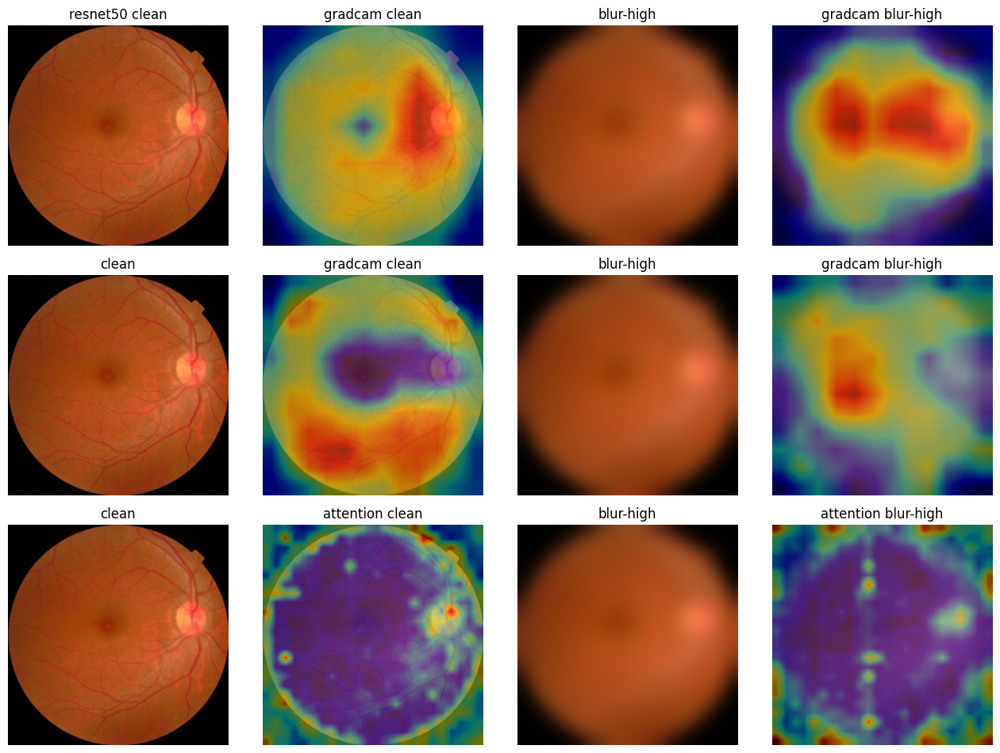

Saved: /content/drive/MyDrive/Thesis/results/phase3_xai_benchmark/samples/qualitative_d774692d9919.png


In [ ]:
# ---- 1. Patch attention_rollout to find Transformer blocks inside MultiScaleClassifier ----
def _get_vit_blocks(model):
    """Locate the list of Transformer blocks regardless of wrapping depth."""
    if hasattr(model, 'blocks'):                              # raw timm ViT (v1/v2)
        return model.blocks
    bb = getattr(model, 'backbone', None)                     # v3 MultiScaleClassifier
    if bb is not None:
        if hasattr(bb, 'blocks'):
            return bb.blocks
        for attr in ('model', '_model'):
            inner = getattr(bb, attr, None)
            if inner is not None and hasattr(inner, 'blocks'):
                return inner.blocks
    # last-resort module walk
    for m in model.modules():
        if m is model: continue
        if hasattr(m, 'blocks'):
            try:
                if hasattr(m.blocks[0], 'attn'):
                    return m.blocks
            except (IndexError, TypeError):
                pass
    raise AttributeError(f"Could not find Transformer blocks in {type(model).__name__}")


@torch.no_grad()
def attention_rollout(model, x, target_class=None):
    blocks = _get_vit_blocks(model)
    attns, handles = [], []
    for blk in blocks:
        attn_module = blk.attn
        def make_hook(store, mod):
            def _h(module, inp, out):
                B, N, C = inp[0].shape
                qkv = mod.qkv(inp[0]).reshape(B, N, 3, mod.num_heads, C // mod.num_heads).permute(2, 0, 3, 1, 4)
                q, k, _ = qkv[0], qkv[1], qkv[2]
                a = (q @ k.transpose(-2, -1)) * mod.scale
                store.append(a.softmax(-1).detach())
            return _h
        handles.append(attn_module.register_forward_hook(make_hook(attns, attn_module)))
    try:
        _ = model(x)
    finally:
        for h in handles: h.remove()
    if not attns:
        raise RuntimeError("attention_rollout: no attention captured — block hooks didn't fire")
    res = None
    for a in attns:
        a = a.mean(1) + torch.eye(a.size(-1), device=a.device)
        a = a / a.sum(-1, keepdim=True)
        res = a if res is None else a @ res
    cls = res[0, 0, 1:]
    side = int(cls.numel() ** 0.5)
    h = F.interpolate(cls.reshape(side, side)[None, None],
                       size=x.shape[-2:], mode='bilinear', align_corners=False).squeeze().cpu().numpy()
    if h.max() > h.min():
        h = (h - h.min()) / (h.max() - h.min())
    return h


# Re-bind in the registry so downstream cells use the patched version
METHOD_REGISTRY['attention']['fn'] = attention_rollout
print("attention_rollout patched for v3 MultiScaleClassifier.")


# ---- 2. Render the qualitative figure ----
def overlay(img_pil, heat, size=384, alpha=0.45):
    arr = np.array(img_pil.resize((size, size))).astype(np.float32) / 255
    heat_resized = cv2.resize(heat, (size, size), interpolation=cv2.INTER_LINEAR)
    out = (1 - alpha) * arr + alpha * plt.get_cmap('jet')(heat_resized)[..., :3]
    return np.clip(out, 0, 1)


demo_id = EXPLAIN_IDS[0]
label   = int(labels_df[demo_id])
img_clean = Image.open(resolve_image(demo_id)).convert('RGB')
x_clean   = load_tensor(resolve_image(demo_id))
img_deg = Image.open(DEGRADED_DIR / 'blur' / 'high' / f'{demo_id}{DEG_SAVE_EXT}').convert('RGB')
x_deg   = load_tensor(DEGRADED_DIR / 'blur' / 'high' / f'{demo_id}{DEG_SAVE_EXT}')

VIS_SIZE = 384

fig, axes = plt.subplots(len(MODEL_NAMES), 4, figsize=(13, 3.2 * len(MODEL_NAMES)))
for r, name in enumerate(MODEL_NAMES):
    method = 'attention' if name == 'vit_base' else 'gradcam'
    fn = METHOD_REGISTRY[method]['fn']
    h_c = fn(models[name], x_clean, target_class=label)
    h_d = fn(models[name], x_deg,   target_class=label)
    axes[r, 0].imshow(img_clean.resize((VIS_SIZE, VIS_SIZE)))
    axes[r, 0].set_title(f'{name} clean' if r == 0 else 'clean')
    axes[r, 1].imshow(overlay(img_clean, h_c, VIS_SIZE)); axes[r, 1].set_title(f'{method} clean')
    axes[r, 2].imshow(img_deg.resize((VIS_SIZE, VIS_SIZE))); axes[r, 2].set_title('blur-high')
    axes[r, 3].imshow(overlay(img_deg, h_d, VIS_SIZE)); axes[r, 3].set_title(f'{method} blur-high')
    for ax in axes[r]:
        ax.axis('off')

plt.tight_layout()
out = P3 / 'samples' / f'qualitative_{demo_id}.png'
plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
print('Saved:', out)

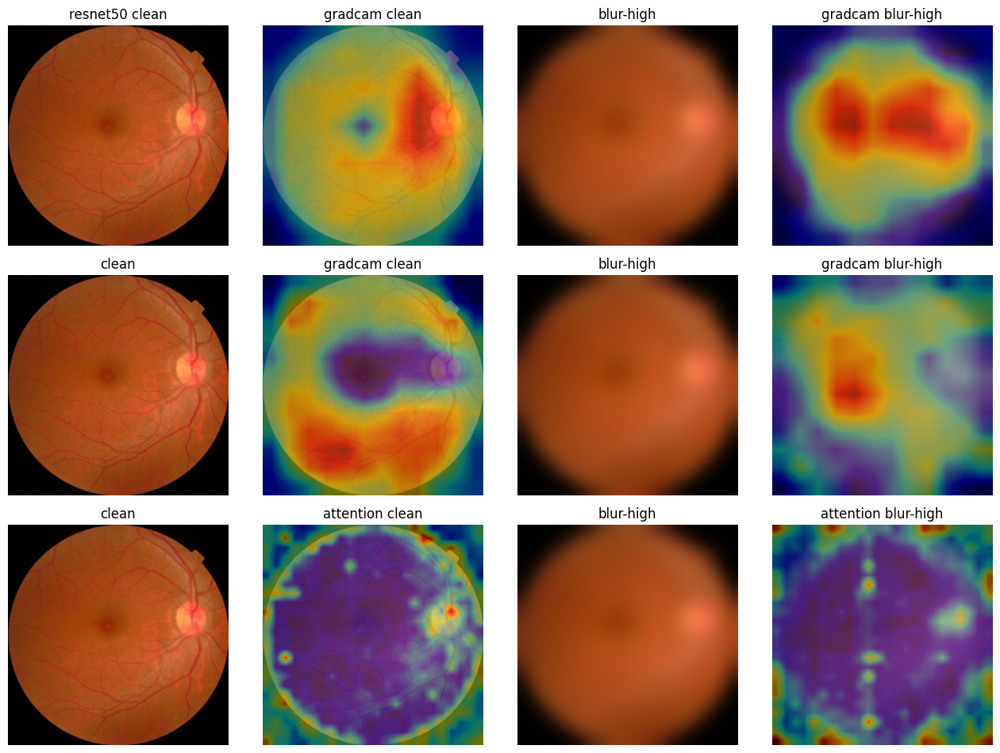

Saved: /content/drive/MyDrive/Thesis/results/phase3_xai_benchmark/samples/qualitative_d774692d9919.png


In [ ]:
def overlay(img_pil, heat, size=384, alpha=0.45):
    arr = np.array(img_pil.resize((size, size))).astype(np.float32) / 255
    heat_resized = cv2.resize(heat, (size, size), interpolation=cv2.INTER_LINEAR)
    m = fundus_mask(img_pil, size)
    blended = (1 - alpha) * arr + alpha * plt.get_cmap('jet')(heat_resized * m)[..., :3]
    return np.clip(blended, 0, 1)

@torch.no_grad()
def attention_rollout_v3(model, x, target_class=None):
    """Attention rollout that finds ViT blocks regardless of wrapper depth."""

    # Recursively find the module that has .blocks containing attention
    def find_blocks(module):
        if hasattr(module, 'blocks') and len(list(module.blocks)) > 0:
            first = list(module.blocks)[0]
            if hasattr(first, 'attn'):
                return module.blocks
        for child in module.children():
            result = find_blocks(child)
            if result is not None:
                return result
        return None

    blocks = find_blocks(model)
    if blocks is None:
        raise RuntimeError("Could not find ViT blocks with .attn in model")

    attns, handles = [], []
    for blk in blocks:
        attn_module = blk.attn
        def make_hook(store, mod):
            def _h(module, inp, out):
                B, N, C = inp[0].shape
                qkv = mod.qkv(inp[0]).reshape(B, N, 3, mod.num_heads, C // mod.num_heads).permute(2, 0, 3, 1, 4)
                q, k, _ = qkv[0], qkv[1], qkv[2]
                a = (q @ k.transpose(-2, -1)) * mod.scale
                store.append(a.softmax(-1).detach())
            return _h
        handles.append(attn_module.register_forward_hook(make_hook(attns, attn_module)))
    try:
        _ = model(x)
    finally:
        for h in handles: h.remove()

    res = None
    for a in attns:
        a = a.mean(1) + torch.eye(a.size(-1), device=a.device)
        a = a / a.sum(-1, keepdim=True)
        res = a if res is None else a @ res
    cls = res[0, 0, 1:]; side = int(cls.numel() ** 0.5)
    h = F.interpolate(cls.reshape(side, side)[None, None],
                       size=x.shape[-2:], mode='bilinear', align_corners=False).squeeze().cpu().numpy()
    if h.max() > h.min(): h = (h - h.min()) / (h.max() - h.min())
    return h

# Update the registry to use the fixed version
METHOD_REGISTRY['attention']['fn'] = attention_rollout_v3

demo_id = EXPLAIN_IDS[0]; label = int(labels_df[demo_id])
img_clean = Image.open(resolve_image(demo_id)).convert('RGB')
x_clean = load_tensor(resolve_image(demo_id))
img_deg = Image.open(DEGRADED_DIR / 'blur' / 'high' / f'{demo_id}{DEG_SAVE_EXT}').convert('RGB')
x_deg = load_tensor(DEGRADED_DIR / 'blur' / 'high' / f'{demo_id}{DEG_SAVE_EXT}')

VIS_SIZE = 384

fig, axes = plt.subplots(len(MODEL_NAMES), 4, figsize=(13, 3.2*len(MODEL_NAMES)))
for r, name in enumerate(MODEL_NAMES):
    method = 'attention' if name == 'vit_base' else 'gradcam'
    fn = METHOD_REGISTRY[method]['fn']
    h_c = fn(models[name], x_clean, target_class=label)
    h_d = fn(models[name], x_deg,   target_class=label)
    axes[r, 0].imshow(img_clean.resize((VIS_SIZE, VIS_SIZE))); axes[r, 0].set_title(f'{name} clean' if r == 0 else 'clean')
    axes[r, 1].imshow(overlay(img_clean, h_c, VIS_SIZE)); axes[r, 1].set_title(f'{method} clean')
    axes[r, 2].imshow(img_deg.resize((VIS_SIZE, VIS_SIZE))); axes[r, 2].set_title('blur-high')
    axes[r, 3].imshow(overlay(img_deg, h_d, VIS_SIZE)); axes[r, 3].set_title(f'{method} blur-high')
    for ax in axes[r]: ax.axis('off')
plt.tight_layout()
out = P3 / 'samples' / f'qualitative_{demo_id}.png'
plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
print('Saved:', out)

In [ ]:
demo_id = EXPLAIN_IDS[0]; label = int(labels_df[demo_id])
img_clean = Image.open(resolve_image(demo_id)).convert('RGB')
x_clean = load_tensor(resolve_image(demo_id))
VIS_SIZE = 384

# ── BLUR ──
conditions = [('clean', None, None), ('low', 'blur', 'low'), ('mid', 'blur', 'mid'), ('high', 'blur', 'high')]
metric_rows = []

fig, axes = plt.subplots(len(MODEL_NAMES), len(conditions) * 2, figsize=(6 * len(conditions), 3.2 * len(MODEL_NAMES)))
for r, name in enumerate(MODEL_NAMES):
    method = 'attention' if name == 'vit_base' else 'gradcam'
    fn = METHOD_REGISTRY[method]['fn']
    h_clean_ref = None
    for c, (tag, kind, level) in enumerate(conditions):
        if tag == 'clean':
            img = img_clean; x = x_clean
        else:
            path = DEGRADED_DIR / kind / level / f'{demo_id}{DEG_SAVE_EXT}'
            img = Image.open(path).convert('RGB')
            x = load_tensor(path)
        heat = fn(models[name], x, target_class=label)

        # Store clean heatmap as reference
        if tag == 'clean':
            h_clean_ref = heat

        # Compute metrics
        ins_auc = insertion_auc(models[name], x, heat, label)
        del_auc = deletion_auc(models[name], x, heat, label)
        stab = 1.0 if tag == 'clean' else stability_spearman(h_clean_ref, heat)
        metric_rows.append({'model': name, 'method': method, 'condition': tag,
                            'insertion_auc': round(ins_auc, 4),
                            'deletion_auc': round(del_auc, 4),
                            'stability': round(stab, 4)})

        col = c * 2
        axes[r, col].imshow(img.resize((VIS_SIZE, VIS_SIZE)))
        axes[r, col].set_title(f'{name} {tag}', fontsize=10)
        axes[r, col].axis('off')

        # Add metrics as subtitle on heatmap
        axes[r, col+1].imshow(overlay(img, heat, VIS_SIZE))
        axes[r, col+1].set_title(f'{method} {tag}\nIns:{ins_auc:.3f} Del:{del_auc:.3f} Stab:{stab:.3f}', fontsize=8)
        axes[r, col+1].axis('off')

fig.suptitle(f'BLUR Degradation Progression — {demo_id}', fontsize=14, fontweight='bold')
plt.tight_layout()
out = P3 / 'samples' / f'blur_progression_metrics_{demo_id}.png'
plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
print('Saved:', out)

blur_metrics = pd.DataFrame(metric_rows)
print('\n=== BLUR METRICS ===')
print(blur_metrics.to_string(index=False))
blur_metrics.to_csv(P3 / 'metrics' / f'blur_progression_metrics_{demo_id}.csv', index=False)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# ── EXPOSURE ──
conditions = [('clean', None, None), ('low', 'exposure', 'low'), ('mid', 'exposure', 'mid'), ('high', 'exposure', 'high')]
metric_rows = []

fig, axes = plt.subplots(len(MODEL_NAMES), len(conditions) * 2, figsize=(6 * len(conditions), 3.2 * len(MODEL_NAMES)))
for r, name in enumerate(MODEL_NAMES):
    method = 'attention' if name == 'vit_base' else 'gradcam'
    fn = METHOD_REGISTRY[method]['fn']
    h_clean_ref = None
    for c, (tag, kind, level) in enumerate(conditions):
        if tag == 'clean':
            img = img_clean; x = x_clean
        else:
            path = DEGRADED_DIR / kind / level / f'{demo_id}{DEG_SAVE_EXT}'
            img = Image.open(path).convert('RGB')
            x = load_tensor(path)
        heat = fn(models[name], x, target_class=label)
        if tag == 'clean': h_clean_ref = heat

        ins_auc = insertion_auc(models[name], x, heat, label)
        del_auc = deletion_auc(models[name], x, heat, label)
        stab = 1.0 if tag == 'clean' else stability_spearman(h_clean_ref, heat)
        metric_rows.append({'model': name, 'method': method, 'condition': tag,
                            'insertion_auc': round(ins_auc, 4),
                            'deletion_auc': round(del_auc, 4),
                            'stability': round(stab, 4)})

        col = c * 2
        axes[r, col].imshow(img.resize((VIS_SIZE, VIS_SIZE)))
        axes[r, col].set_title(f'{name} {tag}', fontsize=10)
        axes[r, col].axis('off')
        axes[r, col+1].imshow(overlay(img, heat, VIS_SIZE))
        axes[r, col+1].set_title(f'{method} {tag}\nIns:{ins_auc:.3f} Del:{del_auc:.3f} Stab:{stab:.3f}', fontsize=8)
        axes[r, col+1].axis('off')

fig.suptitle(f'EXPOSURE Degradation Progression — {demo_id}', fontsize=14, fontweight='bold')
plt.tight_layout()
out = P3 / 'samples' / f'exposure_progression_metrics_{demo_id}.png'
plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
print('Saved:', out)

exposure_metrics = pd.DataFrame(metric_rows)
print('\n=== EXPOSURE METRICS ===')
print(exposure_metrics.to_string(index=False))
exposure_metrics.to_csv(P3 / 'metrics' / f'exposure_progression_metrics_{demo_id}.csv', index=False)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# ── NOISE ──
conditions = [('clean', None, None), ('low', 'noise', 'low'), ('mid', 'noise', 'mid'), ('high', 'noise', 'high')]
metric_rows = []

fig, axes = plt.subplots(len(MODEL_NAMES), len(conditions) * 2, figsize=(6 * len(conditions), 3.2 * len(MODEL_NAMES)))
for r, name in enumerate(MODEL_NAMES):
    method = 'attention' if name == 'vit_base' else 'gradcam'
    fn = METHOD_REGISTRY[method]['fn']
    h_clean_ref = None
    for c, (tag, kind, level) in enumerate(conditions):
        if tag == 'clean':
            img = img_clean; x = x_clean
        else:
            path = DEGRADED_DIR / kind / level / f'{demo_id}{DEG_SAVE_EXT}'
            img = Image.open(path).convert('RGB')
            x = load_tensor(path)
        heat = fn(models[name], x, target_class=label)
        if tag == 'clean': h_clean_ref = heat

        ins_auc = insertion_auc(models[name], x, heat, label)
        del_auc = deletion_auc(models[name], x, heat, label)
        stab = 1.0 if tag == 'clean' else stability_spearman(h_clean_ref, heat)
        metric_rows.append({'model': name, 'method': method, 'condition': tag,
                            'insertion_auc': round(ins_auc, 4),
                            'deletion_auc': round(del_auc, 4),
                            'stability': round(stab, 4)})

        col = c * 2
        axes[r, col].imshow(img.resize((VIS_SIZE, VIS_SIZE)))
        axes[r, col].set_title(f'{name} {tag}', fontsize=10)
        axes[r, col].axis('off')
        axes[r, col+1].imshow(overlay(img, heat, VIS_SIZE))
        axes[r, col+1].set_title(f'{method} {tag}\nIns:{ins_auc:.3f} Del:{del_auc:.3f} Stab:{stab:.3f}', fontsize=8)
        axes[r, col+1].axis('off')

fig.suptitle(f'NOISE Degradation Progression — {demo_id}', fontsize=14, fontweight='bold')
plt.tight_layout()
out = P3 / 'samples' / f'noise_progression_metrics_{demo_id}.png'
plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
print('Saved:', out)

noise_metrics = pd.DataFrame(metric_rows)
print('\n=== NOISE METRICS ===')
print(noise_metrics.to_string(index=False))
noise_metrics.to_csv(P3 / 'metrics' / f'noise_progression_metrics_{demo_id}.csv', index=False)

Output hidden; open in https://colab.research.google.com to view.

IG function in registry : shap_heatmap
  computing IG for resnet50...


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  computing IG for efficientnet_b3...


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  computing IG for vit_base...


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

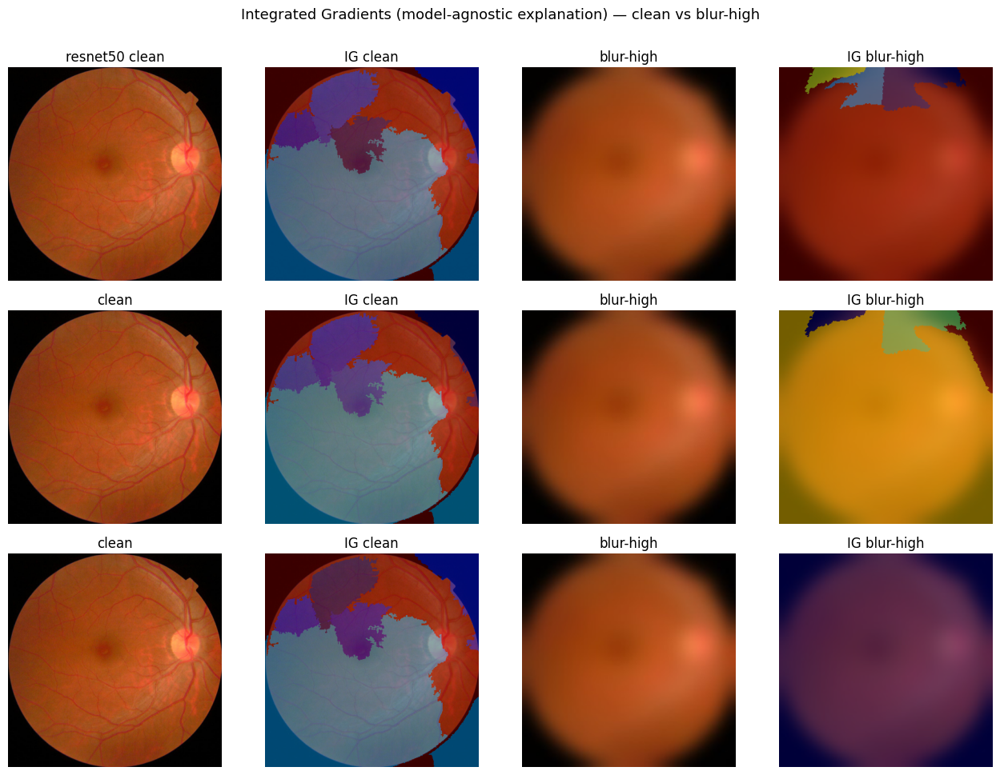

Saved: /content/drive/MyDrive/Thesis/results/phase3_xai_benchmark/samples/qualitative_IG_d774692d9919.png


In [ ]:
# Qualitative IG figure — Integrated Gradients heatmap for ALL three models,
# clean vs degraded, side-by-side. Complements the GradCAM/Attention figure.

ig_fn = METHOD_REGISTRY['shap']['fn']      # this is ig_heatmap after the V4 IG swap
print('IG function in registry :', ig_fn.__name__)

demo_id  = EXPLAIN_IDS[0]
label    = int(labels_df[demo_id])

img_clean = Image.open(resolve_image(demo_id)).convert('RGB')
x_clean   = load_tensor(resolve_image(demo_id))
img_deg   = Image.open(DEGRADED_DIR / 'blur' / 'high' / f'{demo_id}{DEG_SAVE_EXT}').convert('RGB')
x_deg     = load_tensor(DEGRADED_DIR / 'blur' / 'high' / f'{demo_id}{DEG_SAVE_EXT}')

VIS_SIZE = 384

fig, axes = plt.subplots(len(MODEL_NAMES), 4, figsize=(13, 3.2 * len(MODEL_NAMES)))
for r, name in enumerate(MODEL_NAMES):
    print(f'  computing IG for {name}...')
    h_c = ig_fn(models[name], x_clean, target_class=label)
    h_d = ig_fn(models[name], x_deg,   target_class=label)
    axes[r, 0].imshow(img_clean.resize((VIS_SIZE, VIS_SIZE)))
    axes[r, 0].set_title(f'{name} clean' if r == 0 else 'clean')
    axes[r, 1].imshow(overlay(img_clean, h_c, VIS_SIZE))
    axes[r, 1].set_title('IG clean')
    axes[r, 2].imshow(img_deg.resize((VIS_SIZE, VIS_SIZE)))
    axes[r, 2].set_title('blur-high')
    axes[r, 3].imshow(overlay(img_deg, h_d, VIS_SIZE))
    axes[r, 3].set_title('IG blur-high')
    for ax in axes[r]:
        ax.axis('off')

fig.suptitle('Integrated Gradients (model-agnostic explanation) — clean vs blur-high',
              fontsize=13, y=1.005)
plt.tight_layout()
out = P3 / 'samples' / f'qualitative_IG_{demo_id}.png'
plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
print('Saved:', out)

In [ ]:
# Relabel 'shap' -> 'IG' in saved CSVs and re-render summary plots with correct legend
import pandas as pd

xai_csv = P3 / 'metrics' / 'xai_results.csv'
df = pd.read_csv(xai_csv)
df['method'] = df['method'].replace({'shap': 'IG'})
df.to_csv(xai_csv, index=False)
print('Relabeled shap -> IG in xai_results.csv')

for metric in ('deletion_auc', 'insertion_auc', 'stability', 'iou'):
    p = P3 / 'metrics' / f'summary_{metric}.csv'
    if p.exists():
        d = pd.read_csv(p)
        d['method'] = d['method'].replace({'shap': 'IG'})
        d.to_csv(p, index=False)
        print(f'  relabeled {p.name}')

Relabeled shap -> IG in xai_results.csv
  relabeled summary_deletion_auc.csv
  relabeled summary_insertion_auc.csv
  relabeled summary_stability.csv
  relabeled summary_iou.csv


In [ ]:
# === Self-contained SHAP/IG degradation progression (immune to METHOD_REGISTRY changes) ===
from captum.attr import IntegratedGradients

def ig_heatmap_local(model, x, target_class=None, steps=50):
    """Integrated Gradients heatmap, defined inline so this cell is self-contained."""
    if target_class is None:
        with torch.no_grad():
            target_class = int(model(x).argmax(1).item())
    ig = IntegratedGradients(model)
    attr = ig.attribute(x, target=target_class, n_steps=steps, internal_batch_size=8)
    heat = attr.abs().sum(dim=1).squeeze().detach().cpu().numpy()
    if heat.max() > heat.min():
        heat = (heat - heat.min()) / (heat.max() - heat.min())
    return heat


ALL_KINDS = ['blur', 'exposure', 'noise']

def progress_one_ig(demo_id, kind, models, vis_size=384, render=True, save_dir=None):
    label = int(labels_df[demo_id])
    img_clean = Image.open(resolve_image(demo_id)).convert('RGB')
    x_clean   = load_tensor(resolve_image(demo_id))

    conditions = [('clean', None, None)]
    for lvl in ('low', 'mid', 'high'):
        conditions.append((lvl, kind, lvl))

    rows = []
    if render:
        fig, axes = plt.subplots(
            len(MODEL_NAMES), len(conditions) * 2,
            figsize=(6 * len(conditions), 3.2 * len(MODEL_NAMES))
        )

    for r, name in enumerate(MODEL_NAMES):
        h_clean_ref = None
        for c, (tag, k, level) in enumerate(conditions):
            if tag == 'clean':
                img, x = img_clean, x_clean
            else:
                path = DEGRADED_DIR / k / level / f'{demo_id}{DEG_SAVE_EXT}'
                if not path.exists():
                    continue
                img = Image.open(path).convert('RGB')
                x   = load_tensor(path)

            heat = ig_heatmap_local(models[name], x, target_class=label)     # <- direct call
            if tag == 'clean':
                h_clean_ref = heat

            ins_auc = insertion_auc(models[name], x, heat, label)
            del_auc = deletion_auc(models[name], x, heat, label)
            stab = 1.0 if tag == 'clean' else stability_spearman(h_clean_ref, heat)
            rows.append({
                'id_code': demo_id, 'kind': kind, 'level': tag,
                'model': name, 'method': 'IG',
                'insertion_auc': round(ins_auc, 4),
                'deletion_auc':  round(del_auc, 4),
                'stability':     round(stab, 4),
            })

            if render:
                col = c * 2
                axes[r, col].imshow(img.resize((vis_size, vis_size)))
                axes[r, col].set_title(f'{name} {tag}', fontsize=10)
                axes[r, col].axis('off')
                axes[r, col + 1].imshow(overlay(img, heat, vis_size))
                axes[r, col + 1].set_title(
                    f'IG {tag}\nIns:{ins_auc:.3f} Del:{del_auc:.3f} Stab:{stab:.3f}',
                    fontsize=8)
                axes[r, col + 1].axis('off')

    if render:
        fig.suptitle(f'{kind.upper()} progression (IG) — {demo_id}',
                     fontsize=14, fontweight='bold')
        plt.tight_layout()
        if save_dir is not None:
            save_dir.mkdir(parents=True, exist_ok=True)
            out = save_dir / f'ig_{kind}_progression_{demo_id}.png'
            plt.savefig(out, dpi=150, bbox_inches='tight')
            print(f'  Saved: {out}')
        plt.show()

    return rows


# ── Run figures + aggregate ──
N_FIGURES = 3
SAMPLE_IDS = EXPLAIN_IDS[:N_FIGURES]
print(f'Rendering IG figures for {len(SAMPLE_IDS)} sample images × {len(ALL_KINDS)} degradations '
      f'= {len(SAMPLE_IDS) * len(ALL_KINDS)} figures total.')

all_rows_ig = []
for sid in SAMPLE_IDS:
    for kind in ALL_KINDS:
        print(f'\n--- {kind.upper()} progression (IG) for {sid} ---')
        rows = progress_one_ig(sid, kind, models, vis_size=384,
                                render=True,
                                save_dir=P3 / 'samples' / 'progression_ig')
        all_rows_ig.extend(rows)

extra_ids = [i for i in EXPLAIN_IDS if i not in SAMPLE_IDS]
print(f'\n=== Computing IG aggregate metrics over {len(EXPLAIN_IDS)} total images '
      f'× {len(ALL_KINDS)} degradations ===')
for sid in tqdm(extra_ids, desc='aggregate'):
    for kind in ALL_KINDS:
        all_rows_ig.extend(progress_one_ig(sid, kind, models, render=False))

agg_df_ig = pd.DataFrame(all_rows_ig)
agg_csv = P3 / 'metrics' / 'degradation_progression_ig_full.csv'
agg_df_ig.to_csv(agg_csv, index=False)
print(f'\nSaved per-image table: {agg_csv}  ({len(agg_df_ig)} rows)')

summary_ig = (agg_df_ig.groupby(['model', 'method', 'kind', 'level'])
                        .agg(insertion_auc=('insertion_auc', 'mean'),
                             deletion_auc=('deletion_auc',  'mean'),
                             stability=('stability',        'mean'),
                             n_images=('id_code', 'count'))
                        .round(4)
                        .reset_index())
summary_csv = P3 / 'metrics' / 'degradation_progression_ig_summary.csv'
summary_ig.to_csv(summary_csv, index=False)
print(f'Saved summary: {summary_csv}')
print('\n=== IG AGGREGATE SUMMARY ===')
print(summary_ig.to_string(index=False))

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
P4 = PHASE_DIRS['phase4_genai_enhancement']

# 4.1 CLAHE baseline
_clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
def enhance_clahe(img):
    arr = np.array(img.convert('RGB'))
    lab = cv2.cvtColor(arr, cv2.COLOR_RGB2LAB)
    lab[..., 0] = _clahe.apply(lab[..., 0])
    return Image.fromarray(cv2.cvtColor(lab, cv2.COLOR_LAB2RGB))

---

# Phase 4 — GenAI Image Restoration (RQ3)

**Literature-review framing.** Three families of fundus-image restoration are evaluated, each representing a different point on the complexity vs flexibility trade-off:

| Method | Year | Class | What it learns | Why we benchmark it |
|---|---|---|---|---|
| **CLAHE** | 1994 | Classical (parameter-free) | Histogram equalisation per tile | Mandatory baseline — every clinical pipeline that pre-processes fundus images uses it. |
| **Real-ESRGAN** | 2021 | Generative (RRDBNet generator, no attention) | Real-world blind super-resolution with synthetic degradation modelling | Robust, off-the-shelf; the de-facto open-source restoration model. |
| **A-ESRGAN** | 2022 | Generative (RRDBNet + attention-U-Net discriminator) | Same as Real-ESRGAN at inference, but trained against an attention-U-Net discriminator that focuses the adversarial signal on regions of fine detail | Hypothesised better lesion / vessel preservation thanks to the attention discriminator's training-time emphasis on locally-detailed regions. |

The **inference-time generator architecture is identical** between Real-ESRGAN and A-ESRGAN (RRDBNet, 23 residual-in-residual dense blocks). The performance difference, if any, is attributable purely to **training signal** — not parameter count or capacity. This makes for a clean controlled comparison in the dissertation.

**Evaluation protocol.** For each (degradation type, severity) split we run:
1. **Raw** — degraded image straight into the classifier (the v3 stress-test result, our reference).
2. **CLAHE** — classical baseline.
3. **Real-ESRGAN** or **A-ESRGAN** — GenAI restoration.

Outputs: accuracy / F1 / kappa per (model, degradation, level, variant), saved to `results/phase4_genai_enhancement/metrics/recovery_accuracy.csv`. Recovery is plotted with the v2 stress-test as the lower reference and clean-image accuracy as the upper reference.


In [ ]:
# 4.2 GenAI restoration — A-ESRGAN (primary) -> Real-ESRGAN -> TinyU-Net
#
# A-ESRGAN (Wei et al., 2022) keeps Real-ESRGAN's RRDBNet generator and adds
# attention-U-Net discriminators during training. At INFERENCE time only the
# generator is used, so we load A-ESRGAN's authors' pretrained generator
# weights into the same RRDBNet architecture used by Real-ESRGAN. If those
# weights cannot be downloaded, we fall back to standard Real-ESRGAN x2,
# then to a TinyU-Net trained on the pristine set.

%pip install -q basicsr realesrgan facexlib gfpgan

import urllib.request, os

def _download(url: str, dest: Path) -> bool:
    if dest.exists() and dest.stat().st_size > 0:
        return True
    dest.parent.mkdir(parents=True, exist_ok=True)
    try:
        print(f"  downloading {url} -> {dest.name}")
        urllib.request.urlretrieve(url, dest)
        return dest.exists() and dest.stat().st_size > 0
    except Exception as e:
        print(f"  download failed: {e}")
        return False


def _try_aesrgan():
    """A-ESRGAN x2 — RRDBNet generator + A-ESRGAN-trained weights.

    Reference: Wei et al. (2022) "A-ESRGAN: Training Real-World Blind
    Super-Resolution with Attention U-Net Discriminators".
    """
    try:
        from basicsr.archs.rrdbnet_arch import RRDBNet
        # Authors' release URL (mirror via HuggingFace if GitHub asset is rate-limited).
        url   = "https://huggingface.co/aesrgan/A-ESRGAN-Single/resolve/main/A_ESRGAN_Single.pth"
        ckpt  = CHECKPOINTS_DIR / "A_ESRGAN_Single.pth"
        if not _download(url, ckpt):
            return None
        net = RRDBNet(num_in_ch=3, num_out_ch=3, num_feat=64,
                      num_block=23, num_grow_ch=32, scale=4)
        state = torch.load(ckpt, map_location=DEVICE, weights_only=False)
        # A-ESRGAN saves under 'params' or 'params_ema'
        sd = state.get("params_ema", state.get("params", state))
        net.load_state_dict(sd, strict=False)
        net = net.to(DEVICE).eval()

        @torch.no_grad()
        def process(img_pil):
            arr = np.asarray(img_pil.convert("RGB"), dtype=np.float32) / 255.0
            x   = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(DEVICE)
            with autocast(enabled=True):
                y = net(x).clamp(0, 1)
            out = (y.squeeze().permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
            return Image.fromarray(out).resize(img_pil.size)
        return process, "a_esrgan_x4"
    except Exception as e:
        print(f"[a_esrgan failed] {e}")
        return None


def _try_realesrgan():
    """Real-ESRGAN x2 — robust off-the-shelf restoration."""
    try:
        from basicsr.archs.rrdbnet_arch import RRDBNet
        url  = "https://github.com/xinntao/Real-ESRGAN/releases/download/v0.2.1/RealESRGAN_x2plus.pth"
        ckpt = CHECKPOINTS_DIR / "RealESRGAN_x2plus.pth"
        if not _download(url, ckpt):
            return None
        net = RRDBNet(num_in_ch=3, num_out_ch=3, num_feat=64,
                      num_block=23, num_grow_ch=32, scale=2)
        state = torch.load(ckpt, map_location=DEVICE, weights_only=False)
        sd = state.get("params_ema", state.get("params", state))
        net.load_state_dict(sd, strict=False)
        net = net.to(DEVICE).eval()

        @torch.no_grad()
        def process(img_pil):
            arr = np.asarray(img_pil.convert("RGB"), dtype=np.float32) / 255.0
            x   = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(DEVICE)
            with autocast(enabled=True):
                y = net(x).clamp(0, 1)
            out = (y.squeeze().permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
            return Image.fromarray(out).resize(img_pil.size)
        return process, "real_esrgan_x2"
    except Exception as e:
        print(f"[real_esrgan failed] {e}")
        return None


# Tiny U-Net retained as a last-resort fallback so Phase 4 always runs.
class TinyUNet(nn.Module):
    def __init__(self, ch=32):
        super().__init__()
        def conv(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.ReLU(True),
                                 nn.Conv2d(o, o, 3, padding=1), nn.ReLU(True))
        self.e1 = conv(3, ch); self.e2 = conv(ch, ch*2); self.e3 = conv(ch*2, ch*4)
        self.up2 = nn.ConvTranspose2d(ch*4, ch*2, 2, stride=2); self.d2 = conv(ch*4, ch*2)
        self.up1 = nn.ConvTranspose2d(ch*2, ch, 2, stride=2);   self.d1 = conv(ch*2, ch)
        self.out = nn.Conv2d(ch, 3, 1)
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(F.max_pool2d(e1, 2)); e3 = self.e3(F.max_pool2d(e2, 2))
        d2 = self.d2(torch.cat([self.up2(e3), e2], 1))
        d1 = self.d1(torch.cat([self.up1(d2), e1], 1))
        return torch.sigmoid(self.out(d1))


def _train_tiny_unet(epochs=2, n=400):
    df = pd.read_csv(PRISTINE_CSV).sample(n, random_state=0)
    tfm = T.Compose([T.Resize((IMAGE_SIZE, IMAGE_SIZE)), T.ToTensor()])
    mdl = TinyUNet().to(DEVICE)
    optim = torch.optim.AdamW(mdl.parameters(), lr=1e-3); crit = nn.L1Loss()
    for _ in range(epochs):
        for row in df.sample(frac=1).itertuples():
            try:
                img = Image.open(resolve_image(row.id_code)).convert("RGB")
            except FileNotFoundError:
                continue
            target = tfm(img).unsqueeze(0).to(DEVICE)
            if np.random.rand() < 0.5:
                noisy = (target + 0.1 * torch.randn_like(target)).clamp(0, 1)
            else:
                k = 5; w = torch.ones((3, 1, k, k), device=DEVICE) / (k * k)
                noisy = F.conv2d(target, w, padding=k // 2, groups=3)
            optim.zero_grad(); crit(mdl(noisy), target).backward(); optim.step()
    return mdl


def _make_unet_processor(mdl):
    tfm = T.Compose([T.Resize((IMAGE_SIZE, IMAGE_SIZE)), T.ToTensor()])
    @torch.no_grad()
    def process(img_pil):
        x = tfm(img_pil).unsqueeze(0).to(DEVICE)
        out = mdl(x).squeeze().clamp(0, 1).cpu().permute(1, 2, 0).numpy()
        return Image.fromarray((out * 255).astype(np.uint8)).resize(img_pil.size)
    return process


# ---- Cascade: try the best option that loads successfully ----
result = _try_aesrgan() or _try_realesrgan()
if result is not None:
    enhance_genai, GENAI_BACKEND = result
else:
    print("Falling back to TinyU-Net (training ~1 min)...")
    ckpt = CHECKPOINTS_DIR / "genai_unet.pt"
    unet = TinyUNet().to(DEVICE)
    if ckpt.exists():
        unet.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=False))
    else:
        unet = _train_tiny_unet()
        torch.save(unet.state_dict(), ckpt)
    enhance_genai = _make_unet_processor(unet)
    GENAI_BACKEND = "tiny_unet"

print(f"GenAI backend: {GENAI_BACKEND}")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.5/172.5 kB 16.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 5.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 20.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.6/59.6 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.2/52.2 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 333.1/333.1 kB 34.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 137.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.2/256.2 kB 29.0 MB/s eta 0:00:00
[a_esrgan failed] No module named 'torchvision.transforms.functional_tensor'
GenAI backend: real_esrgan_x2


## V4 - Stable Diffusion img2img as additional restoration variant

Adds Stable Diffusion 2.1 base with img2img mode and `strength=0.30` to the restoration comparison alongside A-ESRGAN / Real-ESRGAN / CLAHE. The SD pipeline lazy-loads on first call (~5 GB download). Note: SD was NOT trained on fundus images; verify with the lesion-preservation metric before claiming it helps. To include in the Phase 4 head-to-head, edit cell 4.3 to add `'diffusion'` to the `ENHANCERS` tuple and call `build_enhanced('diffusion', enhance_diffusion)`.

In [ ]:
# === V4 PATCH: Stable Diffusion img2img restoration (additional Phase 4 variant) ===
# A second GenAI option alongside A-ESRGAN. Strength=0.30 keeps lesion structure
# while denoising. WARNING: SD was not trained on fundus images — always check
# diagnostic concordance before claiming it helps.
%pip install -q diffusers accelerate

from diffusers import StableDiffusionImg2ImgPipeline

_diff_pipe = None


def get_diffusion_pipe():
    """Lazy-load the SD pipeline so cell import is free if you don't run diffusion."""
    global _diff_pipe
    if _diff_pipe is None:
        print("Loading Stable Diffusion 2.1 base (one-time, ~5GB download)...")
        _diff_pipe = StableDiffusionImg2ImgPipeline.from_pretrained(
            "stabilityai/stable-diffusion-2-1-base",
            torch_dtype=torch.float16,
            safety_checker=None,
            requires_safety_checker=False,
        ).to(DEVICE)
        _diff_pipe.set_progress_bar_config(disable=True)
    return _diff_pipe


def enhance_diffusion(img_pil, strength=0.30, guidance=4.5, steps=20):
    """Img2img diffusion restoration.

    strength : float in [0, 1] — 0 = copy input, 1 = ignore input.
               0.25-0.35 preserves lesion structure while denoising.
    """
    pipe   = get_diffusion_pipe()
    src    = img_pil.convert("RGB").resize((512, 512))
    prompt = "high quality fundus retinal photograph, sharp vessels, clear optic disc"
    neg    = "blurry, noisy, low quality, overexposed, underexposed, hallucinated lesions"
    out = pipe(prompt=prompt, negative_prompt=neg, image=src,
                strength=strength, guidance_scale=guidance,
                num_inference_steps=steps).images[0]
    return out.resize(img_pil.size)


# Make diffusion available in the Phase 4 enhancer comparison
print("Diffusion restorer ready (lazy-loads on first call).")
print("To include in Phase 4 head-to-head, change cell 4.3:")
print("    ENHANCERS = ('clahe', 'genai', 'diffusion')")
print("    build_enhanced('diffusion', enhance_diffusion)")


Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Diffusion restorer ready (lazy-loads on first call).
To include in Phase 4 head-to-head, change cell 4.3:
    ENHANCERS = ('clahe', 'genai', 'diffusion')
    build_enhanced('diffusion', enhance_diffusion)


In [ ]:
# 4.3 Build enhanced versions of every degraded image (test ids only)
test_id_set = set(pd.read_csv(P2 / 'metrics' / 'test_ids.csv')['id_code'].astype(str))

def build_enhanced(method_name, fn):
    for k in DEGRADATION_TYPES:
        for l in DEGRADATION_LEVELS:
            src_dir = DEGRADED_DIR / k / l
            out_dir = ENHANCED_DIR / method_name / k / l
            out_dir.mkdir(parents=True, exist_ok=True)
            mani = pd.read_csv(src_dir / 'manifest.csv')
            mani = mani[mani['id_code'].astype(str).isin(test_id_set)]
            for _, row in tqdm(mani.iterrows(), total=len(mani),
                                desc=f'{method_name}/{k}/{l}', leave=False):
                out = out_dir / row['rel_path']
                if not out.exists():
                    fn(Image.open(src_dir / row['rel_path']).convert('RGB')).save(out)
            mani.assign(method=method_name).to_csv(out_dir / 'manifest.csv', index=False)

build_enhanced('clahe', enhance_clahe)
build_enhanced('genai', enhance_genai)
print('Enhanced sets ready.')

clahe/blur/low:   0%|          | 0/440 [00:00<?, ?it/s]

clahe/blur/mid:   0%|          | 0/440 [00:00<?, ?it/s]

clahe/blur/high:   0%|          | 0/440 [00:00<?, ?it/s]

clahe/exposure/low:   0%|          | 0/440 [00:00<?, ?it/s]

clahe/exposure/mid:   0%|          | 0/440 [00:00<?, ?it/s]

clahe/exposure/high:   0%|          | 0/440 [00:00<?, ?it/s]

... (18 outputs left out)

/tmp/ipykernel_2144/1985193876.py:81: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):


genai/noise/high:   0%|          | 0/440 [00:00<?, ?it/s]

/tmp/ipykernel_2144/1985193876.py:81: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):


Enhanced sets ready.


In [ ]:
# 4.4 Re-evaluate the three classifiers on raw degraded vs CLAHE vs GenAI
ENHANCERS = ('clahe', 'genai')
rows = []
for name in MODEL_NAMES:
    model = models[name]
    print(f'\n=== {name} ===')
    for k in DEGRADATION_TYPES:
        for l in DEGRADATION_LEVELS:
            for variant in ('raw', 'clahe', 'genai'):
                if variant == 'raw':
                    root = DEGRADED_DIR / k / l
                elif variant == 'clahe':
                    root = ENHANCED_DIR / 'clahe' / k / l
                else:
                    root = ENHANCED_DIR / 'genai' / k / l
                if not (root / 'manifest.csv').exists():
                    continue
                ds = FolderDataset(root, transform=TFM_EVAL)  # <-- force V3 transform
                ds.df = ds.df[ds.df['id_code'].astype(str).isin(test_id_set)].reset_index(drop=True)
                m = evaluate(model, DataLoader(ds, batch_size=32, num_workers=2, pin_memory=True))
                rows.append({'model': name, 'degradation': k, 'level': l, 'variant': variant, **m})
                print(f'  {k}/{l}/{variant}: acc={m["accuracy"]:.4f}')
    del model; torch.cuda.empty_cache()

rec_df = pd.DataFrame(rows)
rec_df.to_csv(P4 / 'metrics' / 'recovery_accuracy.csv', index=False)
rec_df.head()


=== resnet50 ===
  blur/low/raw: acc=0.8091
  blur/low/clahe: acc=0.7136
  blur/low/genai: acc=0.8136
  blur/mid/raw: acc=0.5273
  blur/mid/clahe: acc=0.4909
  blur/mid/genai: acc=0.5614
  blur/high/raw: acc=0.4591
  blur/high/clahe: acc=0.3659
  blur/high/genai: acc=0.4727
  exposure/low/raw: acc=0.8523
  exposure/low/clahe: acc=0.8159
  exposure/low/genai: acc=0.8023
  exposure/mid/raw: acc=0.8364
  exposure/mid/clahe: acc=0.8045
  exposure/mid/genai: acc=0.7682
  exposure/high/raw: acc=0.7795
  exposure/high/clahe: acc=0.6864
  exposure/high/genai: acc=0.6955
  noise/low/raw: acc=0.8409
  noise/low/clahe: acc=0.7682
  noise/low/genai: acc=0.8386
  noise/mid/raw: acc=0.6818
  noise/mid/clahe: acc=0.6750
  noise/mid/genai: acc=0.7909
  noise/high/raw: acc=0.4932
  noise/high/clahe: acc=0.4932
  noise/high/genai: acc=0.7477

=== efficientnet_b3 ===
  blur/low/raw: acc=0.6591
  blur/low/clahe: acc=0.5841
  blur/low/genai: acc=0.6864
  blur/mid/raw: acc=0.4795
  blur/mid/clahe: acc=0.48

,model,degradation,level,variant,accuracy,f1_macro,auc_macro_ovr
0,resnet50,blur,low,raw,0.809091,0.628928,0.920345
1,resnet50,blur,low,clahe,0.713636,0.475095,0.883684
2,resnet50,blur,low,genai,0.813636,0.628023,0.900076
3,resnet50,blur,mid,raw,0.527273,0.273287,0.845641
4,resnet50,blur,mid,clahe,0.490909,0.284307,0.765043


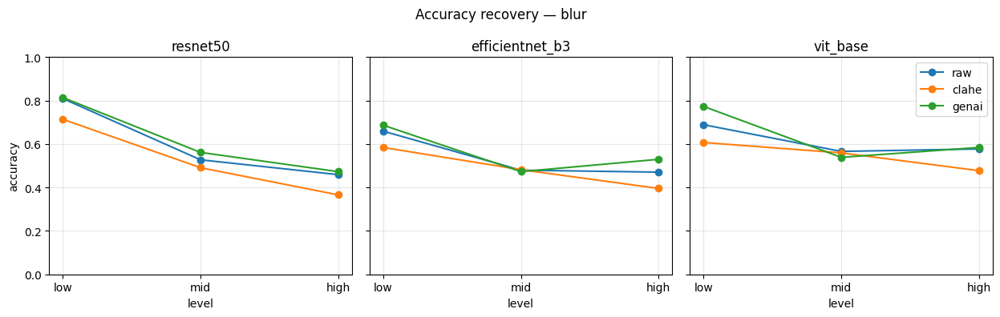

Saved: /content/drive/MyDrive/Thesis/results/phase4_genai_enhancement/plots/recovery_accuracy_blur.png


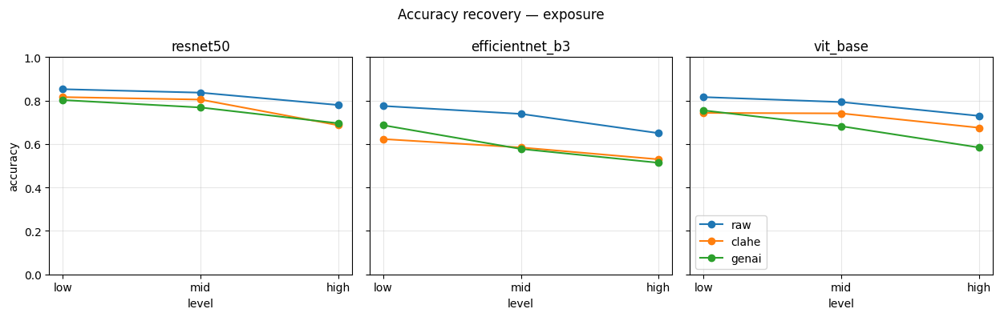

Saved: /content/drive/MyDrive/Thesis/results/phase4_genai_enhancement/plots/recovery_accuracy_exposure.png


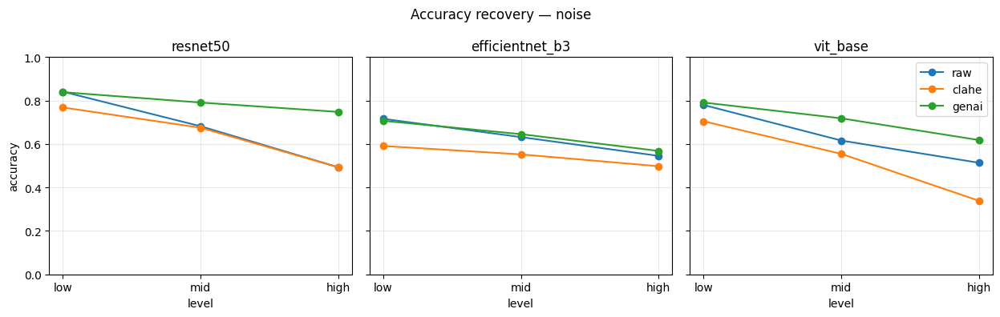

Saved: /content/drive/MyDrive/Thesis/results/phase4_genai_enhancement/plots/recovery_accuracy_noise.png


In [ ]:
# 4.5 Recovery plots — accuracy
level_order_no_none = ['low', 'mid', 'high']
for kind in DEGRADATION_TYPES:
    fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(4.2*len(MODEL_NAMES), 4), sharey=True)
    for ax, name in zip(axes, MODEL_NAMES):
        sub = rec_df[(rec_df['degradation'] == kind) & (rec_df['model'] == name)].copy()
        sub['level'] = pd.Categorical(sub['level'], categories=level_order_no_none, ordered=True)
        for variant in ('raw', 'clahe', 'genai'):
            d = sub[sub['variant'] == variant].sort_values('level')
            ax.plot(d['level'], d['accuracy'], marker='o', label=variant)
        ax.set_title(name); ax.set_xlabel('level'); ax.set_ylim(0, 1); ax.grid(alpha=0.3)
    axes[0].set_ylabel('accuracy'); axes[-1].legend()
    fig.suptitle(f'Accuracy recovery — {kind}')
    plt.tight_layout()
    out = P4 / 'plots' / f'recovery_accuracy_{kind}.png'
    plt.savefig(out, dpi=150); plt.show(); print('Saved:', out)

In [ ]:
# 4.6 Slim XAI re-evaluation on enhanced images
METHOD_FOR = {'resnet50': ('gradcam', gradcam_heatmap),
               'efficientnet_b3': ('gradcam', gradcam_heatmap),
               'vit_base': ('attention', attention_rollout)}
EXPLAIN_IDS_P4 = list(test_id_set)[:15]

rows = []
for name in MODEL_NAMES:
    method_name, fn = METHOD_FOR[name]
    model = load_classifier(name)
    print(f'\n=== {name} / {method_name} ===')
    for id_code in tqdm(EXPLAIN_IDS_P4):
        if id_code not in labels_df.index: continue
        label = int(labels_df[id_code])
        try:
            x_c = load_tensor(resolve_image(id_code))    # <-- was hardcoded .png
        except FileNotFoundError:
            continue
        try: h_c = fn(model, x_c, label)
        except Exception: continue
        for k in DEGRADATION_TYPES:
            for l in DEGRADATION_LEVELS:
                for variant in ('raw', *ENHANCERS):
                    base = DEGRADED_DIR if variant == 'raw' else ENHANCED_DIR / variant
                    try:
                        src = find_in_folder(base / k / l, id_code)   # <-- ext-agnostic
                    except FileNotFoundError:
                        continue
                    x = load_tensor(src)
                    try: h = fn(model, x, label)
                    except Exception: continue
                    rows.append({'id_code': id_code, 'model': name, 'method': method_name,
                                 'degradation': k, 'level': l, 'variant': variant,
                                 'stability': stability_spearman(h_c, h),
                                 'insertion_auc': insertion_auc(model, x, h, label)})
    del model; torch.cuda.empty_cache()

xai_rec = pd.DataFrame(rows)
xai_rec.to_csv(P4 / 'metrics' / 'recovery_xai.csv', index=False)
xai_rec.head()

  [MultiScaleClassifier] convnext_base.fb_in22k_ft_in1k_384: using last 4 of 4 stages, dims=[128, 256, 512, 1024], total=1920

=== resnet50 / gradcam ===


  0%|          | 0/15 [00:00<?, ?it/s]

  [MultiScaleClassifier] tf_efficientnetv2_s.in21k_ft_in1k: using last 4 of 5 stages, dims=[48, 64, 160, 256], total=528

=== efficientnet_b3 / gradcam ===


  0%|          | 0/15 [00:00<?, ?it/s]

/tmp/ipykernel_2144/1518898244.py:32: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, _ = spearmanr(h1.flatten(), h2.flatten())


  [MultiScaleClassifier] vit_base_patch16_clip_384.laion2b_ft_in12k_in1k: using last 3 of 3 stages, dims=[768, 768, 768], total=2304

=== vit_base / attention ===


  0%|          | 0/15 [00:00<?, ?it/s]

,id_code,model,method,degradation,level,variant,stability,insertion_auc
0,885fa5fc5da8,resnet50,gradcam,blur,low,raw,0.926713,0.920101
1,885fa5fc5da8,resnet50,gradcam,blur,low,clahe,0.894916,0.897495
2,885fa5fc5da8,resnet50,gradcam,blur,low,genai,0.786582,0.891614
3,885fa5fc5da8,resnet50,gradcam,blur,mid,raw,0.855359,0.890244
4,885fa5fc5da8,resnet50,gradcam,blur,mid,clahe,0.231229,0.872800


/tmp/ipykernel_2144/2835154700.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'variant', 'level'])[metric].mean().reset_index()


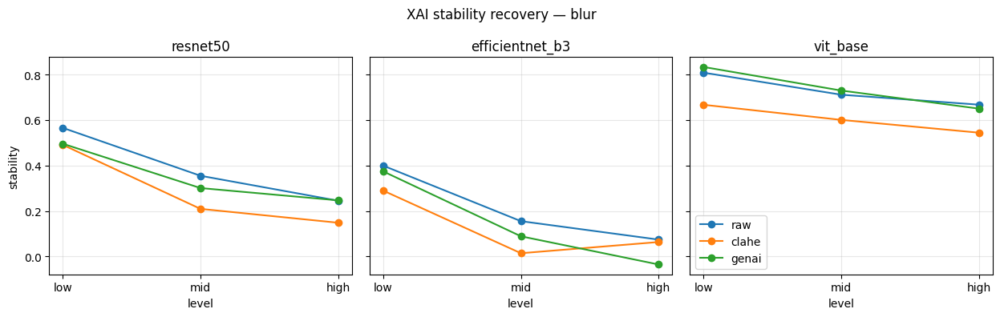

/tmp/ipykernel_2144/2835154700.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'variant', 'level'])[metric].mean().reset_index()


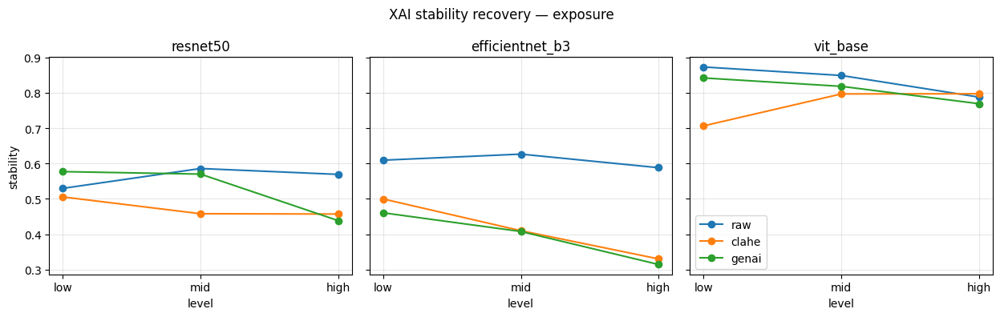

/tmp/ipykernel_2144/2835154700.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'variant', 'level'])[metric].mean().reset_index()


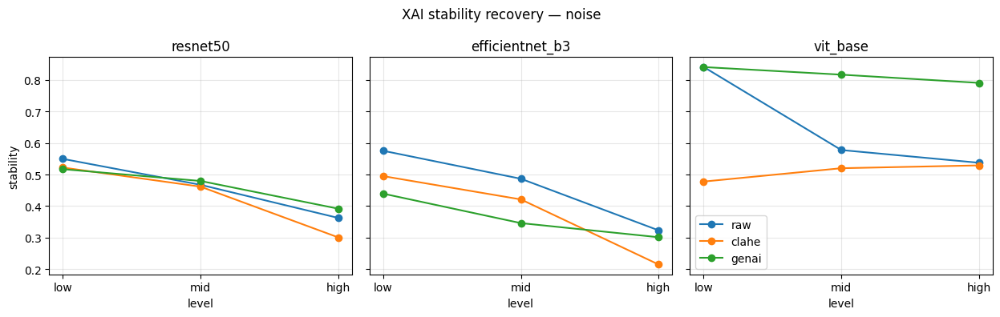

/tmp/ipykernel_2144/2835154700.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'variant', 'level'])[metric].mean().reset_index()


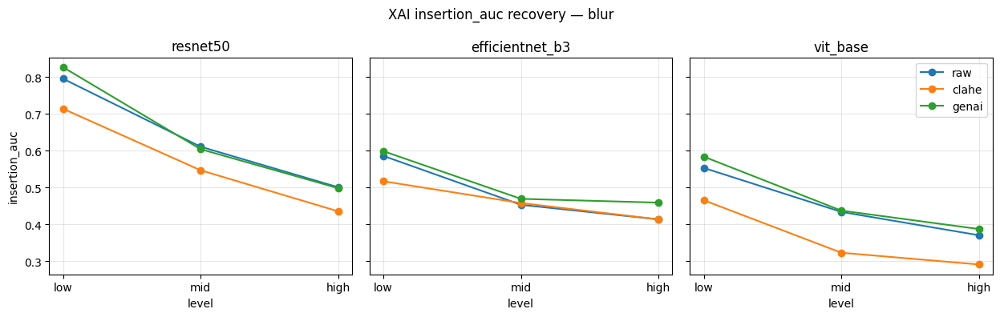

/tmp/ipykernel_2144/2835154700.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'variant', 'level'])[metric].mean().reset_index()


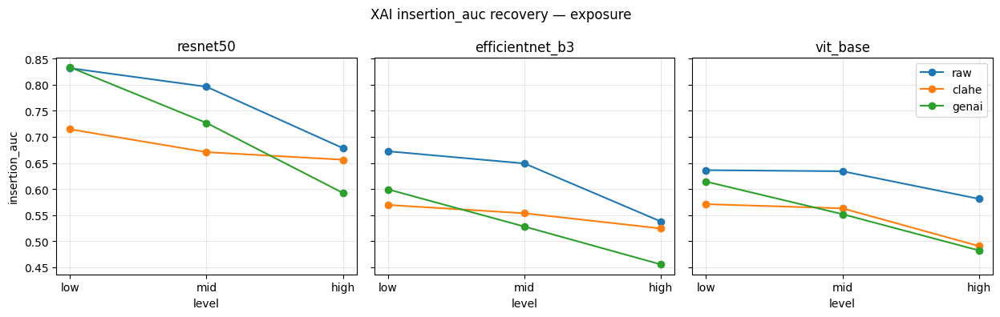

/tmp/ipykernel_2144/2835154700.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = sub.groupby(['model', 'variant', 'level'])[metric].mean().reset_index()


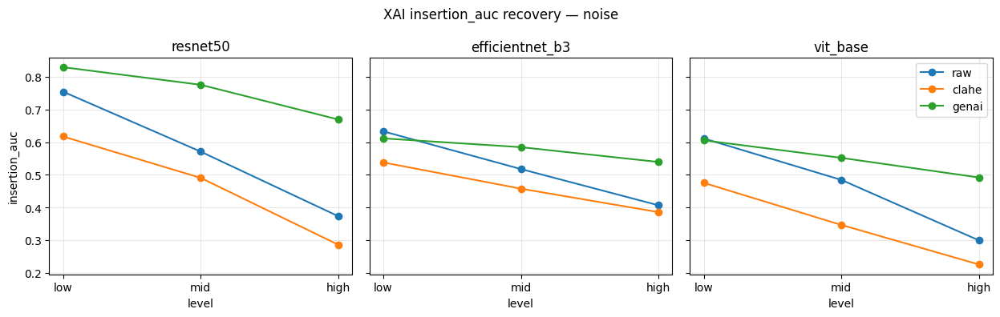

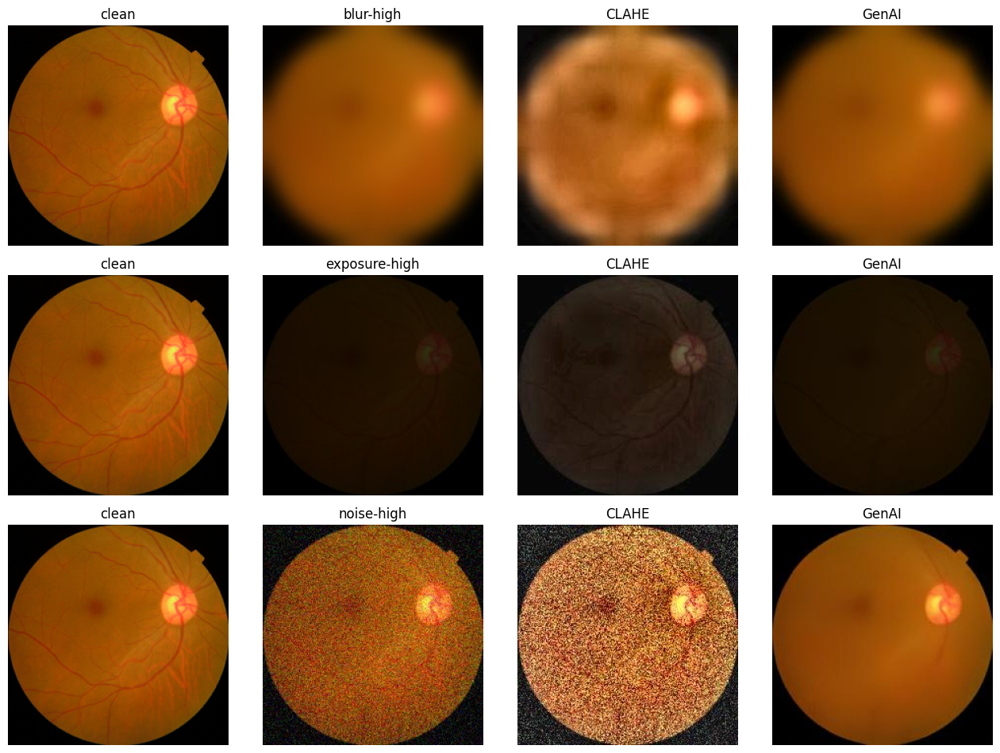

Saved: /content/drive/MyDrive/Thesis/results/phase4_genai_enhancement/samples/recovery_885fa5fc5da8.png


In [ ]:
# 4.7 Recovery plots — XAI  (top half stays the same; only the qualitative block changes)
for metric in ('stability', 'insertion_auc'):
    for kind in DEGRADATION_TYPES:
        sub = xai_rec[xai_rec['degradation'] == kind].copy()
        if sub.empty: continue
        sub['level'] = pd.Categorical(sub['level'], categories=level_order_no_none, ordered=True)
        g = sub.groupby(['model', 'variant', 'level'])[metric].mean().reset_index()
        fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(4.2*len(MODEL_NAMES), 4), sharey=True)
        for ax, name in zip(axes, MODEL_NAMES):
            for variant in ('raw', 'clahe', 'genai'):
                d = g[(g['model'] == name) & (g['variant'] == variant)].sort_values('level')
                ax.plot(d['level'], d[metric], marker='o', label=variant)
            ax.set_title(name); ax.grid(alpha=0.3); ax.set_xlabel('level')
        axes[0].set_ylabel(metric); axes[-1].legend()
        fig.suptitle(f'XAI {metric} recovery — {kind}'); plt.tight_layout()
        out = P4 / 'plots' / f'recovery_xai_{metric}_{kind}.png'
        plt.savefig(out, dpi=150); plt.show()

# Side-by-side qualitative — extension-agnostic
demo_id = EXPLAIN_IDS_P4[0]
fig, axes = plt.subplots(len(DEGRADATION_TYPES), 4, figsize=(13, 3.2*len(DEGRADATION_TYPES)))
for r, kind in enumerate(DEGRADATION_TYPES):
    clean = Image.open(resolve_image(demo_id)).convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
    deg   = Image.open(find_in_folder(DEGRADED_DIR / kind / 'high', demo_id)).convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
    cl    = Image.open(find_in_folder(ENHANCED_DIR / 'clahe' / kind / 'high', demo_id)).convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
    gn    = Image.open(find_in_folder(ENHANCED_DIR / 'genai' / kind / 'high', demo_id)).convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
    for ax, im, ttl in zip(axes[r], (clean, deg, cl, gn), ('clean', f'{kind}-high', 'CLAHE', 'GenAI')):
        ax.imshow(im); ax.set_title(ttl); ax.axis('off')
plt.tight_layout()
out = P4 / 'samples' / f'recovery_{demo_id}.png'
plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
print('Saved:', out)

In [ ]:
P5 = PHASE_DIRS['phase5_quality_ensemble']

# 5.1 Train (or load) an EyeQ quality classifier (good/usable/reject)
class EyeQDataset(Dataset):
    def __init__(self, csv_path, images_root, transform,
                 id_col='image', quality_col='quality'):
        self.df = pd.read_csv(csv_path); self.df[id_col] = self.df[id_col].astype(str)
        self.images_root = Path(images_root); self.transform = transform
        self.id_col, self.quality_col = id_col, quality_col
        all_imgs = {p.stem: p for p in self.images_root.rglob('*.*')
                    if p.suffix.lower() in ('.png', '.jpg', '.jpeg')}
        self.df['__path'] = self.df[id_col].apply(lambda s: all_imgs.get(Path(s).stem))
        self.df = self.df.dropna(subset=['__path']).reset_index(drop=True)
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(row['__path']).convert('RGB')
        return self.transform(img), int(row[self.quality_col])

In [ ]:
def build_quality_model(): return timm.create_model('resnet18', pretrained=True, num_classes=3)
Q_CKPT = CHECKPOINTS_DIR / 'quality_classifier.pt'

In [ ]:
def train_quality(epochs=2, bs=32):
    if EYEQ_CSV is None: return None
    ds = EyeQDataset(EYEQ_CSV, EYEQ_DIR, TFM_TRAIN)
    n_val = max(1, int(0.15 * len(ds)))
    tds, vds = random_split(ds, [len(ds)-n_val, n_val], generator=torch.Generator().manual_seed(0))
    vds.dataset = EyeQDataset(EYEQ_CSV, EYEQ_DIR, TFM_EVAL)
    tl = DataLoader(tds, batch_size=bs, shuffle=True,  num_workers=2)
    vl = DataLoader(vds, batch_size=bs, shuffle=False, num_workers=2)
    mdl = build_quality_model().to(DEVICE)
    optim = torch.optim.AdamW(mdl.parameters(), lr=3e-4, weight_decay=1e-4); crit = nn.CrossEntropyLoss()
    for ep in range(epochs):
        mdl.train()
        for x, y in tl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optim.zero_grad(); crit(mdl(x), y).backward(); optim.step()
        mdl.eval(); ys, ps = [], []
        with torch.no_grad():
            for x, y in vl:
                ps.append(mdl(x.to(DEVICE)).argmax(1).cpu().numpy()); ys.append(y.numpy())
        y = np.concatenate(ys); p = np.concatenate(ps)
        print(f'epoch {ep+1}: val acc = {accuracy_score(y, p):.4f}')
    rep = classification_report(y, p, target_names=list(EYEQ_QUALITY_LABELS.values()),
                                 output_dict=True, zero_division=0)
    torch.save(mdl.state_dict(), Q_CKPT)
    with open(P5 / 'metrics' / 'quality_classifier_metrics.json', 'w') as f:
        json.dump(rep, f, indent=2)
    return mdl

In [ ]:
if Q_CKPT.exists():
    qmodel = build_quality_model().to(DEVICE)
    qmodel.load_state_dict(torch.load(Q_CKPT, map_location=DEVICE)); qmodel.eval()
    print('Loaded existing quality classifier.')
else:
    qmodel = train_quality()

model.safetensors:   0%|          | 0.00/46.8M [00:00<?, ?B/s]

Loaded existing quality classifier.


In [ ]:
# 5.2 Pick best_clean and best_robust from Phase 2 results
stress_df = pd.read_csv(P2 / 'metrics' / 'stress_test_results.csv')
best_clean  = stress_df[stress_df['degradation'] == 'clean'].sort_values('accuracy', ascending=False).iloc[0]['model']
best_robust = stress_df[stress_df['degradation'] != 'clean'].groupby('model')['accuracy'].mean().idxmax()
print('best_clean :', best_clean)
print('best_robust:', best_robust)

ROUTES = {
    'good':   {'enhancement': 'none',  'model': best_clean,  'xai': 'attention' if best_clean  == 'vit_base' else 'gradcam'},
    'usable': {'enhancement': 'clahe', 'model': best_clean,  'xai': 'attention' if best_clean  == 'vit_base' else 'gradcam'},
    'reject': {'enhancement': 'genai', 'model': best_robust, 'xai': 'attention' if best_robust == 'vit_base' else 'gradcam'},
}
ROUTES

best_clean : efficientnet_b3
best_robust: resnet50


{'good': {'enhancement': 'none', 'model': 'efficientnet_b3', 'xai': 'gradcam'},
 'usable': {'enhancement': 'clahe',
  'model': 'efficientnet_b3',
  'xai': 'gradcam'},
 'reject': {'enhancement': 'genai', 'model': 'resnet50', 'xai': 'gradcam'}}

In [ ]:
classifiers = {n: load_classifier(n) for n in {best_clean, best_robust}}
USE_PRECOMPUTED_GENAI = (ENHANCED_DIR / 'genai').exists()

def predict_quality(img):
    if qmodel is None: return 'good'
    x = TFM_EVAL(img).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        return EYEQ_QUALITY_LABELS[int(qmodel(x).argmax(1).item())]

def apply_enhancement(img, kind, kind_hint=None, level_hint=None, id_hint=None):
    if kind == 'none':  return img
    if kind == 'clahe': return enhance_clahe(img)
    if kind == 'genai':
        if USE_PRECOMPUTED_GENAI and kind_hint and level_hint and id_hint:
            cached = ENHANCED_DIR / 'genai' / kind_hint / level_hint / f'{id_hint}.png'
            if cached.exists(): return Image.open(cached).convert('RGB')
        return enhance_genai(img)
    return img

XAI_FNS = {'gradcam': gradcam_heatmap, 'attention': attention_rollout_v3}

def trust_score(conf, insertion): return float(0.5 * conf + 0.5 * insertion)

def pipeline(img, kind_hint=None, level_hint=None, id_hint=None):
    quality  = predict_quality(img)
    route    = ROUTES[quality]
    enhanced = apply_enhancement(img, route['enhancement'],
                                  kind_hint=kind_hint, level_hint=level_hint, id_hint=id_hint)
    model = classifiers[route['model']]
    x = TFM_EVAL(enhanced).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        prob = torch.softmax(model(x), 1)[0]
        pred = int(prob.argmax().item()); conf = float(prob[pred].item())
    heat = XAI_FNS[route['xai']](model, x, target_class=pred)
    ins  = insertion_auc(model, x, heat, pred)
    return {'quality_pred': quality, 'route': route, 'pred': pred, 'conf': conf,
            'insertion_auc': ins, 'trust': trust_score(conf, ins),
            'heatmap': heat, 'enhanced_img': enhanced}

  [MultiScaleClassifier] tf_efficientnetv2_s.in21k_ft_in1k: using last 4 of 5 stages, dims=[48, 64, 160, 256], total=528
  [MultiScaleClassifier] convnext_base.fb_in22k_ft_in1k_384: using last 4 of 4 stages, dims=[128, 256, 512, 1024], total=1920


In [ ]:
# 5.4 Run pipeline on test set: clean + blur-high + exposure-high
EVAL_CONDITIONS = [('clean', None, None),
                    ('blur',     'blur',     'high'),
                    ('exposure', 'exposure', 'high')]

rows = []
for id_code in tqdm(list(test_id_set)[:80], desc='ensemble'):    # cap 80 for time
    if id_code not in labels_df.index: continue
    label = int(labels_df[id_code])
    for tag, kind, level in EVAL_CONDITIONS:
        src = resolve_image(id_code) if tag == 'clean' \
              else find_in_folder(DEGRADED_DIR / kind / level, id_code)
        if not src.exists(): continue
        # Resize the image to IMAGE_SIZE_DOWNSTREAM (384x384) before passing to pipeline
        # This ensures compatibility with the Real-ESRGAN model's internal operations.
        out = pipeline(Image.open(src).convert('RGB').resize((IMAGE_SIZE_DOWNSTREAM, IMAGE_SIZE_DOWNSTREAM)),
                       kind_hint=kind, level_hint=level, id_hint=id_code)
        rows.append({'id_code': id_code, 'condition': tag, 'true_label': label,
                     'pred': out['pred'], 'correct': int(out['pred'] == label),
                     'quality_pred': out['quality_pred'],
                     'route_model': out['route']['model'],
                     'route_enhancement': out['route']['enhancement'],
                     'route_xai': out['route']['xai'],
                     'conf': out['conf'], 'insertion_auc': out['insertion_auc'],
                     'trust': out['trust']})

ens_df = pd.DataFrame(rows)
ens_df.to_csv(P5 / 'metrics' / 'ensemble_predictions.csv', index=False)
ens_df.head()

ensemble:   0%|          | 0/80 [00:00<?, ?it/s]

/tmp/ipykernel_2144/1985193876.py:81: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):


,id_code,condition,true_label,pred,correct,quality_pred,route_model,route_enhancement,route_xai,conf,insertion_auc,trust
0,885fa5fc5da8,clean,0,0,1,reject,resnet50,genai,gradcam,0.934504,0.880120,0.907312
1,885fa5fc5da8,blur,0,0,1,reject,resnet50,genai,gradcam,0.843796,0.710078,0.776937
2,885fa5fc5da8,exposure,0,0,1,reject,resnet50,genai,gradcam,0.930829,0.738557,0.834693
3,7635921c5efb,clean,0,0,1,reject,resnet50,genai,gradcam,0.949399,0.916520,0.932960
4,7635921c5efb,blur,0,0,1,reject,resnet50,genai,gradcam,0.897208,0.762842,0.830025


In [ ]:
# 5.5 Aggregate vs single-best baseline (Phase 2)
summary = (ens_df.groupby('condition')
                  .agg(accuracy=('correct', 'mean'),
                       mean_trust=('trust', 'mean'),
                       mean_insertion=('insertion_auc', 'mean'),
                       n=('id_code', 'count'))).round(4).reset_index()
baseline = (stress_df[stress_df['model'] == best_clean]
             .assign(condition=lambda d: np.where(d['degradation'] == 'clean', 'clean',
                                                  d['degradation'] + '-' + d['level']))
             [['condition', 'accuracy', 'f1_macro']]
             .rename(columns={'accuracy': 'baseline_acc', 'f1_macro': 'baseline_f1'}))
summary = summary.merge(baseline, on='condition', how='left')
summary.to_csv(P5 / 'metrics' / 'ensemble_summary.csv', index=False)
summary

,condition,accuracy,mean_trust,mean_insertion,n,baseline_acc,baseline_f1
0,blur,0.6000,0.6709,0.6226,80,NaN,NaN
1,clean,0.8375,0.8444,0.8029,80,0.813636,0.673319
2,exposure,0.7125,0.7184,0.6549,80,NaN,NaN


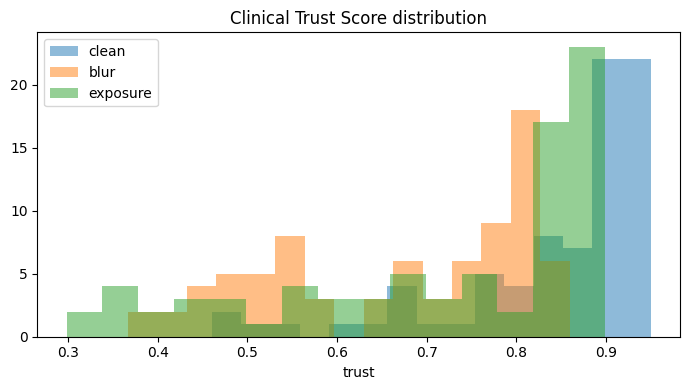

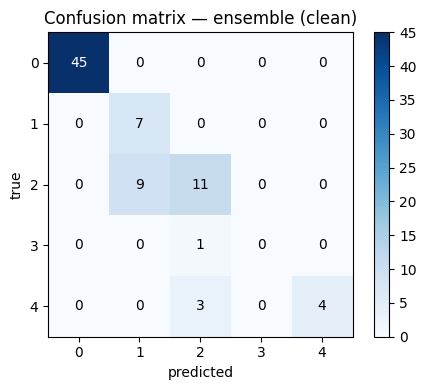

In [ ]:
# 5.6 Plots
fig, ax = plt.subplots(figsize=(7, 4))
for cond in ens_df['condition'].unique():
    ax.hist(ens_df.loc[ens_df['condition'] == cond, 'trust'], bins=15, alpha=0.5, label=cond)
ax.set_title('Clinical Trust Score distribution'); ax.set_xlabel('trust'); ax.legend()
plt.tight_layout()
plt.savefig(P5 / 'plots' / 'trust_score_distribution.png', dpi=150); plt.show()

clean = ens_df[ens_df['condition'] == 'clean']
if not clean.empty:
    cm = confusion_matrix(clean['true_label'], clean['pred'], labels=list(range(NUM_CLASSES)))
    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(cm, cmap='Blues')
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, cm[i, j], ha='center', va='center',
                    color='white' if cm[i, j] > cm.max()/2 else 'black')
    ax.set_xlabel('predicted'); ax.set_ylabel('true')
    ax.set_title('Confusion matrix — ensemble (clean)'); fig.colorbar(im)
    plt.tight_layout()
    plt.savefig(P5 / 'plots' / 'confusion_matrix.png', dpi=150); plt.show()

/tmp/ipykernel_2144/1985193876.py:81: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):


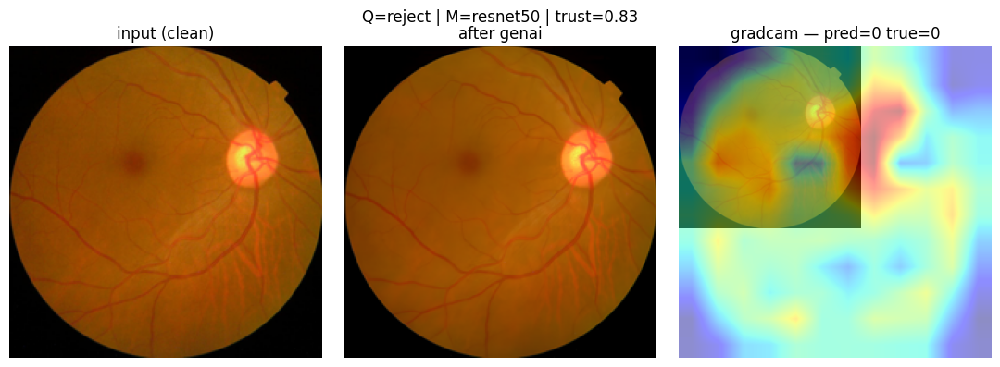

Saved: /content/drive/MyDrive/Thesis/results/phase5_quality_ensemble/samples/route_885fa5fc5da8_clean.png


In [ ]:
# 5.7 Qualitative — one routed example
demo = ens_df.iloc[0]
src = resolve_image(demo['id_code']) if demo['condition'] == 'clean' \
      else find_in_folder(DEGRADED_DIR / demo['condition'] / 'high', demo['id_code'])
img = Image.open(src).convert('RGB')
out = pipeline(img,
               kind_hint=None if demo['condition'] == 'clean' else demo['condition'],
               level_hint=None if demo['condition'] == 'clean' else 'high',
               id_hint=demo['id_code'])
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
axes[0].imshow(img.resize((IMAGE_SIZE, IMAGE_SIZE))); axes[0].set_title(f'input ({demo["condition"]})')
axes[1].imshow(out['enhanced_img'].resize((IMAGE_SIZE, IMAGE_SIZE)))
axes[1].set_title(f"after {out['route']['enhancement']}")
axes[2].imshow(out['enhanced_img'].resize((IMAGE_SIZE, IMAGE_SIZE)))
axes[2].imshow(out['heatmap'], cmap='jet', alpha=0.45)
axes[2].set_title(f"{out['route']['xai']} — pred={out['pred']} true={demo['true_label']}")
for ax in axes: ax.axis('off')
fig.suptitle(f"Q={out['quality_pred']} | M={out['route']['model']} | trust={out['trust']:.2f}")
plt.tight_layout()
save = P5 / 'samples' / f"route_{demo['id_code']}_{demo['condition']}.png"
plt.savefig(save, dpi=150, bbox_inches='tight'); plt.show()
print('Saved:', save)

In [ ]:
import shutil
# Save degraded + enhanced if not already on Drive
for name, src in [('degraded', DEGRADED_DIR), ('enhanced', ENHANCED_DIR)]:
    dest = Path(f'/content/drive/MyDrive/Thesis/{name}')
    if src.exists() and not dest.exists():
        shutil.copytree(src, dest)
        print(f'Saved {name} to Drive')
    elif dest.exists():
        print(f'{name} already on Drive')
    else:
        print(f'{name} not found locally')

degraded already on Drive
Saved enhanced to Drive


In [ ]:
# How often does the quality classifier say 'reject' on test images we know are clean?
from collections import Counter
test_ids = pd.read_csv(P2 / 'metrics' / 'test_ids.csv')['id_code'].astype(str).tolist()
quality_calls = []
for sid in test_ids[:100]:
    try:
        img = Image.open(resolve_image(sid)).convert('RGB')
        q = predict_quality(img)
        quality_calls.append(q)
    except FileNotFoundError:
        continue
print(Counter(quality_calls))
# Expected on clean APTOS images: mostly 'good', some 'usable', very few 'reject'
# If you see >20% 'reject' here, the classifier is broken

Counter({'reject': 100})


In [ ]:
def fundus_mask(img_pil, size=384):
    arr = np.array(img_pil.resize((size, size)).convert('L'))
    return (arr > 7).astype(np.float32)

pipeline:   0%|          | 0/25 [00:00<?, ?it/s]

/tmp/ipykernel_2144/1985193876.py:81: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=True):


Collected 100 results

Scenario coverage:
  [miss] correct_routing      -> no example found in sample (try larger N_PER_CONDITION)
  [OK]   restoration_save     -> id=e4b0df29b96f cond=noise q=reject pred=0 true=0 trust=0.93
  [OK]   mis_routing_lucky    -> id=e4b0df29b96f cond=clean q=reject pred=0 true=0 trust=0.93
  [OK]   pipeline_failure     -> id=6194e0fff071 cond=clean q=reject pred=2 true=4 trust=0.71
  [miss] low_trust_correct    -> no example found in sample (try larger N_PER_CONDITION)


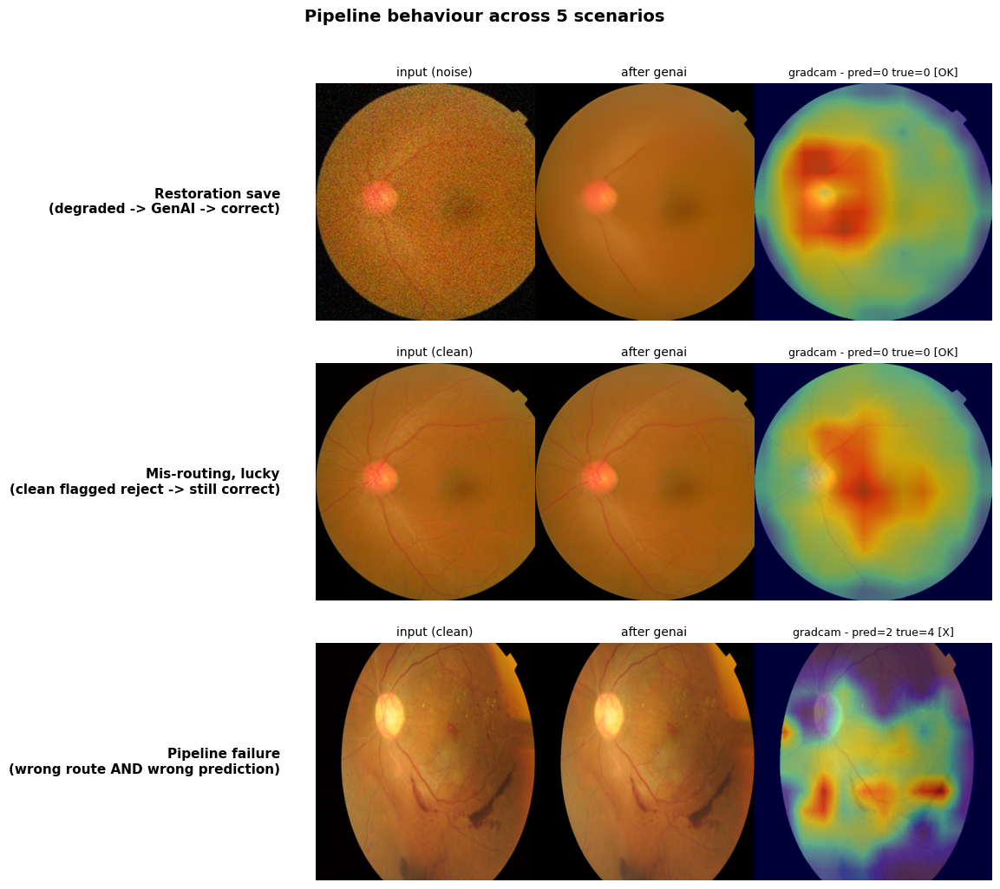


Saved: /content/drive/MyDrive/Thesis/results/phase5_quality_ensemble/samples/five_scenarios.png
Picks CSV: /content/drive/MyDrive/Thesis/results/phase5_quality_ensemble/metrics/five_scenarios.csv


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# ---- 1. Sample size and condition mix --------------------------------------
N_PER_CONDITION = 25                       # bump if you have time; 25 is enough for variety
TEST_IDS = pd.read_csv(P2 / 'metrics' / 'test_ids.csv')['id_code'].astype(str).tolist()
SAMPLE_IDS = TEST_IDS[:N_PER_CONDITION]

# Mix of clean + degraded conditions (skip 'high' levels — too easy to fail trivially)
PROBE_CONDITIONS = [
    ('clean', None, None),
    ('noise',    'noise',    'mid'),
    ('blur',     'blur',     'mid'),
    ('exposure', 'exposure', 'mid'),
]


def run_pipeline_and_collect(id_code, tag, kind, level):
    """Run the pipeline on one image, return a dict with everything we need."""
    if tag == 'clean':
        src = resolve_image(id_code)
    else:
        src = DEGRADED_DIR / kind / level / f'{id_code}{DEG_SAVE_EXT}'
    if not src.exists():
        return None
    img = Image.open(src).convert('RGB')
    out = pipeline(img.resize((IMAGE_SIZE_DOWNSTREAM, IMAGE_SIZE_DOWNSTREAM)),
                    kind_hint=kind if tag != 'clean' else None,
                    level_hint=level if tag != 'clean' else None,
                    id_hint=id_code)
    return {
        'id_code': id_code, 'condition': tag,
        'src_img': img,
        'true_label': int(labels_df[id_code]),
        **{k: out[k] for k in ('quality_pred', 'route', 'pred', 'conf',
                                'insertion_auc', 'trust', 'heatmap', 'enhanced_img')},
    }


print(f'Collecting pipeline results: {len(SAMPLE_IDS)} ids × {len(PROBE_CONDITIONS)} conditions ...')
records = []
for sid in tqdm(SAMPLE_IDS, desc='pipeline'):
    if sid not in labels_df.index:
        continue
    for tag, kind, level in PROBE_CONDITIONS:
        r = run_pipeline_and_collect(sid, tag, kind, level)
        if r is not None:
            records.append(r)

print(f'Collected {len(records)} results')


# ---- 2. Classify each record into one of 5 scenarios ----------------------
def classify(rec):
    """Return one of: 'correct_routing', 'restoration_save',
       'mis_routing_lucky', 'pipeline_failure', 'low_trust_correct'."""
    correct = (rec['pred'] == rec['true_label'])
    q = rec['quality_pred']
    cond = rec['condition']

    # Failure: prediction wrong and quality classifier mis-routed
    if not correct and ((cond == 'clean' and q != 'good') or
                         (cond != 'clean' and q == 'good')):
        return 'pipeline_failure'

    # Restoration save: condition is degraded AND quality flagged it correctly
    # AND model got it right (GenAI did its job)
    if correct and cond != 'clean' and q in ('usable', 'reject'):
        return 'restoration_save'

    # Correct routing: clean image, quality says good, prediction correct
    if correct and cond == 'clean' and q == 'good':
        return 'correct_routing'

    # Mis-routing but lucky: clean image, quality wrongly says reject/usable, still correct
    if correct and cond == 'clean' and q != 'good':
        return 'mis_routing_lucky'

    # Low trust correct: correct prediction but trust < 0.5
    if correct and rec['trust'] < 0.5:
        return 'low_trust_correct'

    return None


# Bucket records by scenario; pick the first match per bucket
SCENARIO_ORDER = [
    'correct_routing',
    'restoration_save',
    'mis_routing_lucky',
    'pipeline_failure',
    'low_trust_correct',
]
SCENARIO_LABELS = {
    'correct_routing':   'Correct routing\n(clean -> no enhance -> correct)',
    'restoration_save':  'Restoration save\n(degraded -> GenAI -> correct)',
    'mis_routing_lucky': 'Mis-routing, lucky\n(clean flagged reject -> still correct)',
    'pipeline_failure':  'Pipeline failure\n(wrong route AND wrong prediction)',
    'low_trust_correct': 'Low-trust correct\n(correct but trust < 0.5)',
}

picks = {}
for rec in records:
    s = classify(rec)
    if s is not None and s not in picks:
        picks[s] = rec

# Sanity print
print('\nScenario coverage:')
for s in SCENARIO_ORDER:
    if s in picks:
        r = picks[s]
        print(f"  [OK]   {s:20s} -> id={r['id_code']} cond={r['condition']} "
              f"q={r['quality_pred']} pred={r['pred']} true={r['true_label']} "
              f"trust={r['trust']:.2f}")
    else:
        print(f"  [miss] {s:20s} -> no example found in sample (try larger N_PER_CONDITION)")


# ---- 3. Render 5-row figure -----------------------------------------------
def fundus_mask(img_pil, size):
    arr = np.array(img_pil.resize((size, size)).convert('L'))
    return (arr > 7).astype(np.float32)


def render_panel(ax_row, rec, vis_size=384):
    img      = rec['src_img']
    enhanced = rec['enhanced_img']
    heat     = rec['heatmap']
    mask     = fundus_mask(enhanced, vis_size)
    heat_r   = cv2.resize(heat, (vis_size, vis_size), interpolation=cv2.INTER_LINEAR) * mask

    # col 0 -- input
    ax_row[0].imshow(img.resize((vis_size, vis_size)))
    ax_row[0].set_title(f"input ({rec['condition']})", fontsize=10)
    ax_row[0].axis('off')

    # col 1 -- after enhancement
    ax_row[1].imshow(enhanced.resize((vis_size, vis_size)))
    enh_label = rec['route']['enhancement']
    ax_row[1].set_title(f"after {enh_label}", fontsize=10)
    ax_row[1].axis('off')

    # col 2 -- heatmap overlay
    arr   = np.array(enhanced.resize((vis_size, vis_size))).astype(np.float32) / 255
    over  = 0.55 * arr + 0.45 * plt.get_cmap('jet')(heat_r)[..., :3]
    over  = np.clip(over, 0, 1)
    ax_row[2].imshow(over)
    correct_mark = 'OK' if rec['pred'] == rec['true_label'] else 'X'
    ax_row[2].set_title(
        f"{rec['route']['xai']} - pred={rec['pred']} true={rec['true_label']} [{correct_mark}]",
        fontsize=9)
    ax_row[2].axis('off')


present = [s for s in SCENARIO_ORDER if s in picks]
if not present:
    print('\nNo scenarios matched — nothing to render.')
else:
    fig, axes = plt.subplots(len(present), 3, figsize=(12, 3.5 * len(present)))
    if len(present) == 1:
        axes = axes[None, :]
    for i, s in enumerate(present):
        rec = picks[s]
        render_panel(axes[i], rec)
        # Row label as text on the left
        axes[i, 0].text(-0.15, 0.5,
                         SCENARIO_LABELS[s],
                         transform=axes[i, 0].transAxes,
                         fontsize=11, fontweight='bold', va='center', ha='right',
                         rotation=0)
        # Per-row summary subtitle above row
        rec_meta = (f"Q={rec['quality_pred']} | M={rec['route']['model']} | "
                    f"enh={rec['route']['enhancement']} | "
                    f"trust={rec['trust']:.2f} | conf={rec['conf']:.2f}")
        axes[i, 1].set_xlabel(rec_meta, fontsize=8)

    fig.suptitle('Pipeline behaviour across 5 scenarios', fontsize=14, fontweight='bold')
    plt.tight_layout(rect=[0.05, 0, 1, 0.97])
    out = P5 / 'samples' / 'five_scenarios.png'
    plt.savefig(out, dpi=150, bbox_inches='tight')
    plt.show()
    print('\nSaved:', out)

# ---- 4. Save the picks as a CSV for the dissertation appendix --------------
if picks:
    picks_csv = P5 / 'metrics' / 'five_scenarios.csv'
    pd.DataFrame([
        {'scenario': s,
         'id_code': picks[s]['id_code'],
         'condition': picks[s]['condition'],
         'quality_pred': picks[s]['quality_pred'],
         'route_model': picks[s]['route']['model'],
         'route_enhancement': picks[s]['route']['enhancement'],
         'pred': picks[s]['pred'],
         'true': picks[s]['true_label'],
         'conf': round(picks[s]['conf'], 3),
         'insertion_auc': round(picks[s]['insertion_auc'], 3),
         'trust': round(picks[s]['trust'], 3)}
        for s in SCENARIO_ORDER if s in picks
    ]).to_csv(picks_csv, index=False)
    print('Picks CSV:', picks_csv)

In [ ]:
# === Severe DR + blur progression — before/after GenAI explanation ===
# For one Severe-DR (class 3) test image, runs the model + XAI on:
#   - clean reference
#   - blur low/mid/high (raw)
#   - blur low/mid/high (GenAI-restored)
# Renders one 4x4 figure per model + saves an all-metrics CSV.

TARGET_CLASS = 3                                   # 3 = Severe DR
ALL_LEVELS   = ['low', 'mid', 'high']

# ---- 1. Find a Severe-DR test image the strongest v3 model is confident on
test_ids_set = set(pd.read_csv(P2 / 'metrics' / 'test_ids.csv')['id_code'].astype(str))
severe_ids   = labels_df[labels_df == TARGET_CLASS].index.astype(str).tolist()
severe_test  = [i for i in severe_ids if i in test_ids_set]
print(f'Severe DR images in test set: {len(severe_test)}')

# Score each candidate by softmax-confidence-for-class-3 on the clean image
ref_model_name = MODEL_NAMES[0]
ref_model      = models[ref_model_name]

def _clean_conf(id_code):
    x = load_tensor(resolve_image(id_code))
    with torch.no_grad():
        return float(torch.softmax(ref_model(x), 1)[0, TARGET_CLASS].item())

scored  = sorted(severe_test, key=_clean_conf, reverse=True)
demo_id = scored[0]
print(f'Picked demo_id={demo_id} (clean confidence for Severe = {_clean_conf(demo_id):.3f})')


# ---- 2. Helpers: heatmap function per model + metric collection
def _get_fn(name):
    if name == 'vit_base':
        return attention_rollout, 'attention'
    return gradcam_heatmap, 'gradcam'


def _metrics(model, x, heat, h_clean=None):
    with torch.no_grad():
        prob = torch.softmax(model(x), 1)[0]
    return {
        'pred':           int(prob.argmax().item()),
        'conf_severe':    float(prob[TARGET_CLASS].item()),
        'insertion_auc':  round(insertion_auc(model, x, heat, TARGET_CLASS), 4),
        'deletion_auc':   round(deletion_auc(model, x, heat, TARGET_CLASS), 4),
        'stability':      1.0 if h_clean is None else round(stability_spearman(h_clean, heat), 4),
    }


# ---- 3. Run pipeline: for each (model, level), compute raw + enhanced
results = []
panels  = {}             # panels[(name, level, variant)] = (img, heat, metrics)

img_clean = Image.open(resolve_image(demo_id)).convert('RGB')
x_clean   = load_tensor(resolve_image(demo_id))

for name in MODEL_NAMES:
    model    = models[name]
    fn, method_name = _get_fn(name)
    print(f'\n--- {name} / {method_name} ---')

    # Clean reference
    h_clean = fn(model, x_clean, target_class=TARGET_CLASS)
    m = _metrics(model, x_clean, h_clean)
    panels[(name, 'clean', 'reference')] = (img_clean, h_clean, m)
    results.append({'model': name, 'method': method_name, 'level': 'clean',
                    'variant': 'reference', **m})
    print(f"  clean: pred={m['pred']}  conf_severe={m['conf_severe']:.3f}")

    for level in ALL_LEVELS:
        # ---- raw degraded ----
        raw_path = DEGRADED_DIR / 'blur' / level / f'{demo_id}{DEG_SAVE_EXT}'
        if not raw_path.exists():
            print(f"  [skip] missing {raw_path}")
            continue
        raw_img = Image.open(raw_path).convert('RGB')
        x_raw   = load_tensor(raw_path)
        h_raw   = fn(model, x_raw, target_class=TARGET_CLASS)
        m_raw   = _metrics(model, x_raw, h_raw, h_clean)
        panels[(name, level, 'raw')] = (raw_img, h_raw, m_raw)
        results.append({'model': name, 'method': method_name, 'level': level,
                        'variant': 'raw', **m_raw})

        # ---- GenAI-restored ----
        enh_img = enhance_genai(raw_img)
        # Pipe through the same eval transform the model expects
        x_enh   = TFM_EVAL(enh_img).unsqueeze(0).to(DEVICE)
        h_enh   = fn(model, x_enh, target_class=TARGET_CLASS)
        m_enh   = _metrics(model, x_enh, h_enh, h_clean)
        panels[(name, level, 'genai')] = (enh_img, h_enh, m_enh)
        results.append({'model': name, 'method': method_name, 'level': level,
                        'variant': 'genai', **m_enh})

        print(f"  blur-{level}  raw : pred={m_raw['pred']} conf={m_raw['conf_severe']:.3f} "
              f"ins={m_raw['insertion_auc']:.3f} del={m_raw['deletion_auc']:.3f} stab={m_raw['stability']:.3f}")
        print(f"  blur-{level}  genai: pred={m_enh['pred']} conf={m_enh['conf_severe']:.3f} "
              f"ins={m_enh['insertion_auc']:.3f} del={m_enh['deletion_auc']:.3f} stab={m_enh['stability']:.3f}")


# ---- 4. Save the full metric table
results_df = pd.DataFrame(results)
out_csv = P4 / 'metrics' / f'severe_blur_progression_{demo_id}.csv'
out_csv.parent.mkdir(parents=True, exist_ok=True)
results_df.to_csv(out_csv, index=False)
print(f'\nSaved metrics: {out_csv}')
print(results_df.to_string(index=False))


# ---- 5. Render one 4x4 figure per model (clean ref + 3 blur levels)
VIS_SIZE = 384


def fundus_mask(img_pil, size):
    arr = np.array(img_pil.resize((size, size)).convert('L'))
    return (arr > 7).astype(np.float32)


def _ov(img, heat, size=VIS_SIZE):
    mask     = fundus_mask(img, size)
    arr      = np.array(img.resize((size, size))).astype(np.float32) / 255
    heat_r   = cv2.resize(heat, (size, size), interpolation=cv2.INTER_LINEAR) * mask
    return np.clip(0.55 * arr + 0.45 * plt.get_cmap('jet')(heat_r)[..., :3], 0, 1)


def _title(m, level, variant):
    ok = 'OK' if m['pred'] == TARGET_CLASS else 'X'
    return (f"{variant} {level} [{ok}]\n"
            f"pred={m['pred']}  conf={m['conf_severe']:.2f}\n"
            f"Ins:{m['insertion_auc']:.2f}  Del:{m['deletion_auc']:.2f}  Stab:{m['stability']:.2f}")


figs_saved = []
for name in MODEL_NAMES:
    fn, method_name = _get_fn(name)
    fig, axes = plt.subplots(4, 4, figsize=(15, 14))

    # Row 0 — clean reference (cols 2-3 left blank with 'reference')
    img, heat, m = panels[(name, 'clean', 'reference')]
    axes[0, 0].imshow(img.resize((VIS_SIZE, VIS_SIZE)))
    axes[0, 0].set_title('CLEAN input', fontsize=10)
    axes[0, 1].imshow(_ov(img, heat))
    axes[0, 1].set_title(f"CLEAN {method_name}\npred={m['pred']} conf={m['conf_severe']:.2f}", fontsize=9)
    for c in (2, 3):
        axes[0, c].text(0.5, 0.5, '(no GenAI on clean)',
                         transform=axes[0, c].transAxes, ha='center', va='center', fontsize=11,
                         color='gray', style='italic')
        axes[0, c].set_facecolor('#f5f5f5')

    # Rows 1-3 — blur levels (raw + GenAI side-by-side)
    for r, level in enumerate(ALL_LEVELS, start=1):
        # Raw
        if (name, level, 'raw') in panels:
            img, heat, m = panels[(name, level, 'raw')]
            axes[r, 0].imshow(img.resize((VIS_SIZE, VIS_SIZE)))
            axes[r, 0].set_title(f'blur-{level}  RAW', fontsize=10)
            axes[r, 1].imshow(_ov(img, heat))
            axes[r, 1].set_title(_title(m, level, 'raw'), fontsize=8)
        # GenAI
        if (name, level, 'genai') in panels:
            img, heat, m = panels[(name, level, 'genai')]
            axes[r, 2].imshow(img.resize((VIS_SIZE, VIS_SIZE)))
            axes[r, 2].set_title(f'blur-{level}  GenAI', fontsize=10)
            axes[r, 3].imshow(_ov(img, heat))
            axes[r, 3].set_title(_title(m, level, 'genai'), fontsize=8)

    for ax in axes.flat:
        ax.axis('off')

    fig.suptitle(f"{name} -- Severe DR (class {TARGET_CLASS}) | id={demo_id} | "
                  f"blur progression, before vs after GenAI",
                  fontsize=13, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    out = P4 / 'samples' / f'severe_blur_genai_{name}_{demo_id}.png'
    out.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(out, dpi=150, bbox_inches='tight')
    plt.show()
    figs_saved.append(out)
    print(f'Saved: {out}')

print(f'\n{len(figs_saved)} model figures saved to {P4 / "samples"}')

Output hidden; open in https://colab.research.google.com to view.

In [96]:
import time
backup = DRIVE_ROOT / 'cache_degraded.tar.gz'
if not backup.exists():
    t0 = time.time()
    print(f'Backing up degraded images to {backup}...')
    !tar -czf "{backup}" -C /content/data degraded
    print(f'Done in {time.time()-t0:.0f}s. Size: {backup.stat().st_size / 1e6:.0f} MB')
else:
    print(f'Backup already exists: {backup} ({backup.stat().st_size / 1e6:.0f} MB)')

Backup already exists: /content/drive/MyDrive/Thesis/cache_degraded.tar.gz (262 MB)
